In [1]:
import torch
print(torch.__version__)
print(torch.version.cuda)
print(torch.cuda.is_available())

2.12.1+cu130
13.0
True


In [2]:
import NPI
import pandas as pd
import seaborn as sns
from scipy.stats import pearsonr
from lesion_response import *
from local_lpcmci import *
from intervention_optimization import *
from recovery_evaluation import *
from hypothesis_lagged_validation import *
from centroid_calculation import *
from stage1_visualization import *
from stage2_visualization import *
from stage3_visualization import *
from stage4_visualization import *
from stage4_network_visualization import (
    plot_stage4_directed_causal_intervention_graph_split,
    extract_policy_lesion_paths,
    build_policy_lesion_path_subgraph,
    plot_stage4_policy_lesion_path_graph,
    plot_stage4_policy_lesion_recovery_path_graph_pair
)
from simulated_var_validation import (
    run_simulated_var_validation_experiment,
    summarize_simulated_var_results,
    judge_simulated_var_validation,
    build_simulated_var_two_layer_tables,
    build_screen_ratio_comparison_table
)
from Parametric_grid_search import (
    BASE_CONFIG,
    OUTPUT_DIR,
    run_stagewise_grid_search_with_constraints,
    run_full_pipeline_with_config,
    summarize_final_pipeline_result,
)

In [3]:
def flat_without_diagonal(matrix):

    "Flatten the matrix without including the diagonal"
    
    n = matrix.shape[0]
    flattened = []
    for i in range(n):
        for j in list(range(i)) + list(range(i + 1, n)): #list拼接 可以直接用i!=j
            flattened.append(matrix[i][j])
    
    return np.array(flattened)

### **NPI usage demo**

In [4]:
NPI.set_seed(42)
batch_size = 50
train_set_proportion = 0.8
ROI_num = 360
using_steps = 3
pred_steps = 1     

num_epochs = 100
lr = 1e-3
l2 = 5e-5
patience = 10
min_delta = 1e-5
dropout = 0.2
noise_std = 0.0

In [5]:
#信号处理 分割成输入数据和输出数据,数据条数共1200条 脑区数量360
signals = []
inputs = []
targets = []
for file in ['./data/raw/real_fMRI_data/102008_REST1_LR.txt',
             './data/raw/real_fMRI_data/102008_REST1_RL.txt',
             './data/raw/real_fMRI_data/102008_REST2_LR.txt',
             './data/raw/real_fMRI_data/102008_REST2_RL.txt']:
    data = np.loadtxt(file)[30:, :360].astype(np.float32)
    signals.append(data)
    input, target = NPI.multi2one(data, input_steps=using_steps, pred_steps=pred_steps)
    inputs.append(input)
    targets.append(target)
signals = np.vstack(signals).astype(np.float32)
inputs = np.vstack(inputs).astype(np.float32)
targets = np.vstack(targets).astype(np.float32)

In [6]:
#neworderlr 给出了脑区的新排列方式； neworder 表示旧脑区在新顺序中的位置映射； oldorder 是其逆映射，用于从新顺序恢复到原顺序。
neworderlr = np.loadtxt('./data/derived/Whole-brain_EC/MNI-MMP1/neworderlr.txt')
print(neworderlr)
print(neworderlr.shape)
#旧脑区 i 在新顺序中的位置 neworder[i] = 新顺序中的位置
#np.where(neworderlr == 0) → (array([1]),) np.where(neworderlr == i)[0][0] (array([1]),)[0] → array([1]) array([1])[0] → 1
neworder = np.array([np.where(neworderlr == i)[0][0] for i in range(len(neworderlr))])
#oldorder[i] 代表i号脑区在最开始的脑区的位置
oldorder = np.array([np.where(neworder == i)[0][0] for i in range(len(neworder))])
# neworder 是 old → new
# oldorder 是 new → old
# 它们是 互逆置换。
# 因为在不同步骤：fMRI 时间序列 FC / EC 矩阵 DTI 结构矩阵 ROI 的顺序不统一 👉 必须能 来回切换 ROI 顺序
# 脑区重排序让不同来源的数据在同一语义坐标系里对齐 脑区重排的目的：是让“同一个索引，在所有数据里都指向同一个脑区”。


[  0.  50.   1.   2.   3.   4.   5.  28.  29.  51.  52. 117.   6. 118.
 119.   7.  53.   8.   9.  10.  11.  12.  13.  30.  74. 140. 141. 142.
 120. 143. 144. 145. 146. 147. 148.  31.  75.  76.  32.  33.  34.  54.
  77.  78.  55.  56.  57.  58.  59.  60.  35.  36.  37.  38.  39.  61.
  79. 121.  80.  81. 149. 150. 122. 151. 152. 153. 154. 155. 156. 157.
 158. 159. 123. 124. 160. 161. 162.  82. 125.  62. 126. 127. 128. 129.
 130. 131. 163.  98. 164.  99. 100. 101. 102. 165.  63.  64. 132. 166.
  83.  40.  41.  42.  84.  43.  85.  86. 103.  87.  88. 104. 133. 167.
  89.  90.  91.  65.  66. 105.  14. 106.  15. 107. 108.  44.  45.  16.
  17. 168. 169. 170. 109. 171. 134. 110. 111.  67.  68.  69.  92.  93.
  70.  18.  71. 135. 136.  72.  94.  95. 137. 172. 173.  19.  20.  21.
  22.  23.  73.  24.  25.  26. 174. 175.  27. 112. 113. 114.  96.  46.
  97. 176. 138. 115.  47.  48.  49. 177. 178. 116. 139. 179. 180. 230.
 181. 182. 183. 184. 185. 208. 209. 231. 232. 297. 186. 298. 299. 187.
 233. 

##### train NN

Several ANNs (MLP, CNN, RNN, VAR) are provided in the NPI framework, which can be used as a surrogate brain.

In [7]:
ANN = NPI.ANN_MLP(input_dim = using_steps * ROI_num, hidden_dim = 2 * ROI_num, latent_dim = int(0.8 * ROI_num), output_dim = ROI_num,pred_steps=pred_steps, dropout=dropout)
# ANN = NPI.ANN_CNN(in_channels = ROI_num, hidden_channels = 3 * ROI_num, out_channels = ROI_num, data_length = using_steps,pred_steps=pred_steps)
# ANN = NPI.ANN_RNN(input_dim = ROI_num, hidden_dim = int(2.5 * ROI_num), latent_dim = int(2.5 * ROI_num), output_dim = ROI_num, data_length = using_steps,pred_steps=pred_steps)
# ANN = NPI.ANN_VAR(input_dim = using_steps * ROI_num, output_dim = ROI_num,pred_steps=pred_steps)

ANN, history = NPI.train_NN(
    ANN,
    inputs,
    targets,
    pred_steps=pred_steps,
    batch_size=batch_size,
    train_set_proportion=train_set_proportion,
    num_epochs=num_epochs,
    lr=lr,
    l2=l2,
    patience=patience,
    noise_std=noise_std
)

print("\nBest epoch:", history["best_epoch"])
print("Best test loss:", history["best_test_loss"])

Epoch [001/100] | train_noisy: 0.450731 | train_clean: 0.271856 | test: 0.406377
Epoch [002/100] | train_noisy: 0.294007 | train_clean: 0.230202 | test: 0.376342
Epoch [003/100] | train_noisy: 0.260152 | train_clean: 0.200338 | test: 0.352624
Epoch [004/100] | train_noisy: 0.234994 | train_clean: 0.199244 | test: 0.357377
Epoch [005/100] | train_noisy: 0.223155 | train_clean: 0.176607 | test: 0.343900
Epoch [006/100] | train_noisy: 0.211431 | train_clean: 0.151270 | test: 0.320483
Epoch [007/100] | train_noisy: 0.196198 | train_clean: 0.143787 | test: 0.322339
Epoch [008/100] | train_noisy: 0.197221 | train_clean: 0.154801 | test: 0.335144
Epoch [009/100] | train_noisy: 0.192652 | train_clean: 0.140216 | test: 0.326914
Epoch [010/100] | train_noisy: 0.190185 | train_clean: 0.127396 | test: 0.317551
Epoch [011/100] | train_noisy: 0.182240 | train_clean: 0.131310 | test: 0.324032
Epoch [012/100] | train_noisy: 0.181672 | train_clean: 0.123835 | test: 0.316078
Epoch [013/100] | train_nois

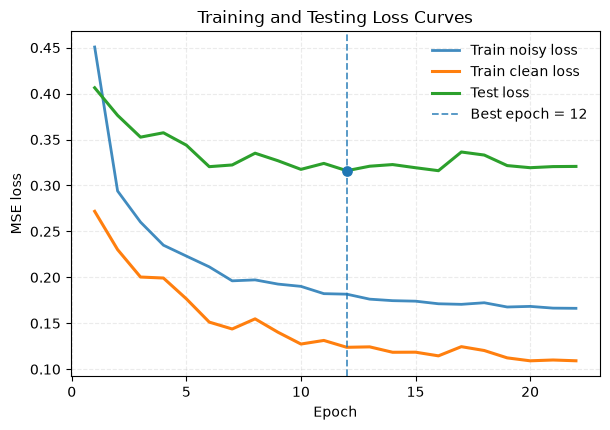

In [8]:
fig, ax = plt.subplots(figsize=(6.2, 4.4))

ax.plot(
    history["epoch"],
    history["train_noisy_loss"],
    label="Train noisy loss",
    linewidth=2.0,
    alpha=0.85
)

ax.plot(
    history["epoch"],
    history["train_clean_loss"],
    label="Train clean loss",
    linewidth=2.2
)

ax.plot(
    history["epoch"],
    history["test_loss"],
    label="Test loss",
    linewidth=2.2
)

best_epoch = history["best_epoch"]
best_test_loss = history["best_test_loss"]

ax.axvline(
    best_epoch,
    linestyle="--",
    linewidth=1.3,
    alpha=0.8,
    label=f"Best epoch = {best_epoch}"
)

ax.scatter(
    [best_epoch],
    [best_test_loss],
    s=45,
    zorder=5
)

ax.set_xlabel("Epoch")
ax.set_ylabel("MSE loss")
ax.set_title("Training and Testing Loss Curves")
ax.legend(frameon=False)
ax.grid(alpha=0.25, linestyle="--")

plt.tight_layout()
plt.show()

##### calculate empirical FC & model FC

In [9]:
#empirical_FC 是一个 ROI×ROI 的功能连接矩阵，其中每个元素表示对应两个脑区时间序列之间（整个时间维度上 计算皮尔逊相关系数）的皮尔逊相关系数。矩阵中的每一个点对应一条脑区之间的连接，而不是某一时刻的信号值。
#每一对脑区的相关系数 是用 这 12000 个点一起算出来的
# empirical_FC = NPI.corrcoef(signals) #从真实 fMRI 时间序列，算 ROI–ROI 的相关矩阵  即ROI i 和 ROI j进行比较 看看他们在整个时间轴上是不是“同步变化”
# model_FC = NPI.model_FC(ANN, node_num = ROI_num, steps = using_steps)#使用模型去模拟时间序列 然后算出FC
# print(empirical_FC.shape)
# 6. Held-out predictive FC + affine calibration + GSR
def fit_roi_affine(pred_train, true_train, eps=1e-8):
    """
    pred_train, true_train: shape (n_samples, ROI_num)
    拟合每个 ROI 的线性校正：y = a*x + b
    """
    mu_x = pred_train.mean(axis=0)
    mu_y = true_train.mean(axis=0)

    var_x = pred_train.var(axis=0)
    cov_xy = ((pred_train - mu_x) * (true_train - mu_y)).mean(axis=0)

    a = cov_xy / (var_x + eps)
    b = mu_y - a * mu_x
    return a, b
def apply_roi_affine(pred, a, b):
    """
    pred: shape (n_samples, ROI_num)
    """
    return pred * a[None, :] + b[None, :]


def remove_global_signal(X):
    """
    X shape: (n_samples, ROI_num)
    每个时间点减去该时刻全脑平均值
    """
    return X - X.mean(axis=1, keepdims=True)
# =========================================================
# Held-out predictive FC + affine calibration + GSR
# 一步预测版本
# =========================================================

train_X, train_Y, test_X, test_Y = NPI.split_train_test(
    inputs, targets, train_set_proportion=train_set_proportion
)

pred_train_all = NPI.predict_array(ANN, train_X, batch_size=256)
true_train_all = train_Y.reshape(-1, pred_steps, ROI_num)

pred_test_all = NPI.predict_array(ANN, test_X, batch_size=256)
true_test_all = test_Y.reshape(-1, pred_steps, ROI_num)

alpha = 0.8

# 一步预测只有 step_idx = 0
step_idx = 0

pred_train_k = pred_train_all[:, step_idx, :]
true_train_k = true_train_all[:, step_idx, :]

# 训练集拟合 ROI-wise affine calibration
a, b = fit_roi_affine(pred_train_k, true_train_k)

a_shrink = 1.0 + alpha * (a - 1.0)
b_shrink = alpha * b

# 测试集预测
pred_test_k = pred_test_all[:, step_idx, :]
true_test_k = true_test_all[:, step_idx, :]

# affine calibration
pred_test_k_cal = apply_roi_affine(pred_test_k, a_shrink, b_shrink)

# global signal removal
pred_test_k_fc = remove_global_signal(pred_test_k_cal)
true_test_k_fc = remove_global_signal(true_test_k)

# FC
model_FC_t1 = NPI.corrcoef(pred_test_k_fc)
empirical_FC_t1 = NPI.corrcoef(true_test_k_fc)

# 如果你后面代码习惯用 model_FC / empirical_FC，也可以这样赋值
model_FC = model_FC_t1
empirical_FC = empirical_FC_t1

##### calculate NPI Inferred EC

In [10]:
# NPI_EC = NPI.model_EC(ANN, inputs, targets, pert_strength = 1.0)
# np.fill_diagonal(NPI_EC, 0)
NPI_EC = NPI.model_EC(
    ANN,
    inputs,
    targets,
    pert_strength=1.0,
    pred_steps=pred_steps,
    step_idx=0,
    batch_size=256
)
np.fill_diagonal(NPI_EC, 0)

##### empirical FC - model FC comparison

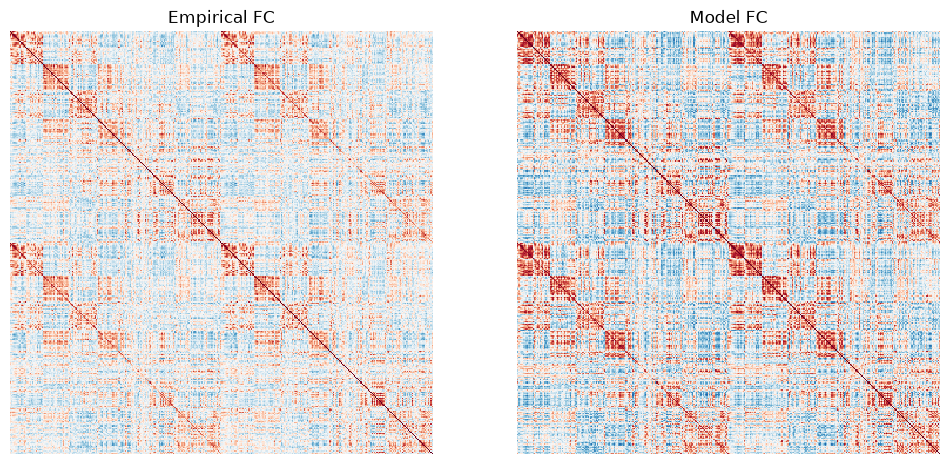

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (12, 6))
sns.heatmap(empirical_FC[neworder].T[neworder].T, ax = ax1, vmin = -1.0, vmax = 1.0, cmap = 'RdBu_r', cbar = False, square = True, xticklabels = False, yticklabels = False)
sns.heatmap(model_FC[neworder].T[neworder].T, ax = ax2, vmin = -1.0, vmax = 1.0, cmap = 'RdBu_r', cbar = False, square = True, xticklabels = False, yticklabels = False)
ax1.set_title('Empirical FC'); ax2.set_title('Model FC')
plt.show()

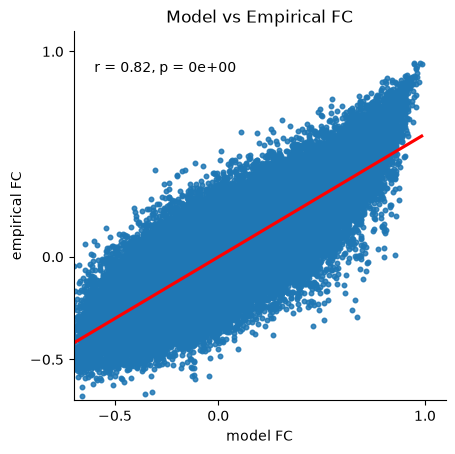

In [12]:
# r_value, p_value = pearsonr(flat_without_diagonal(model_FC), flat_without_diagonal(empirical_FC))
#
# plt.figure(figsize = (4.8, 4.8))
# plt.scatter(flat_without_diagonal(model_FC), flat_without_diagonal(empirical_FC))
#
# plt.xlim(-0.7, 1.1); plt.xticks([-0.5, 0.0, 1.0]); plt.xlabel('model FC')
# plt.ylim(-0.7, 1.1); plt.yticks([-0.5, 0.0, 1.0]); plt.ylabel('empirical FC')
# plt.text(-0.6, 0.9, 'r = {:.2f}, p = {:.0e}'.format(r_value, p_value))
#
# ax = plt.gca()
# ax.spines['right'].set_visible(False); ax.spines['top'].set_visible(False)
#
# plt.show()
#散点图每个点是一个脑区对的 FC 值 (model_FC(i,j), empirical_FC(i,j))。
# 散点图用于评估模型连接与经验连接之间的一致性。横轴是模型生成的连接强度，纵轴是经验数据中的连接强度。每一个点代表一对脑区之间的连接边，在绘制前我们去除了对角线并将矩阵展平成一维向量。从结果可以看到二者呈现出明显的正相关关系，Pearson 相关系数为 0.69，说明模型在整体连接结构层面上能够较好地重现经验脑网络特征。
#r 值表示模型生成的功能连接与经验功能连接在整体结构上的线性相关程度，越接近 1 表示越一致；p 值表示该相关性是否显著，越小说明相关性越不可能是随机出现。
# 计算 r 和 p
#r 值越接近 1 → 散点沿拟合线线性分布 → 拟合越好 r 值接近 0 → 散点随机分布 → 拟合差
#散点沿红色拟合线均匀排列 → 拟合好 散点围绕 45° 对角线 → 模型与真实数据一致 r 越大、p 越小 → 拟合越可信
r_value, p_value = pearsonr(flat_without_diagonal(model_FC), flat_without_diagonal(empirical_FC))

# 设置画布
plt.figure(figsize=(4.8, 4.8))

# 散点图 + 拟合红线
sns.regplot(
    x=flat_without_diagonal(model_FC),
    y=flat_without_diagonal(empirical_FC),
    scatter_kws={'s': 10, 'alpha': 0.6},  # 点小且半透明
    line_kws={'color': 'red'}             # 拟合线红色
)

# 坐标轴范围与刻度
plt.xlim(-0.7, 1.1)
plt.xticks([-0.5, 0.0, 1.0])
plt.xlabel('model FC')

plt.ylim(-0.7, 1.1)
plt.yticks([-0.5, 0.0, 1.0])
plt.ylabel('empirical FC')

# 在图上显示 r 和 p
plt.text(-0.6, 0.9, f'r = {r_value:.2f}, p = {p_value:.0e}')

# 去掉右边框和上边框
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plt.title('Model vs Empirical FC', fontsize=12)
plt.show()

##### NPI EC (individual)

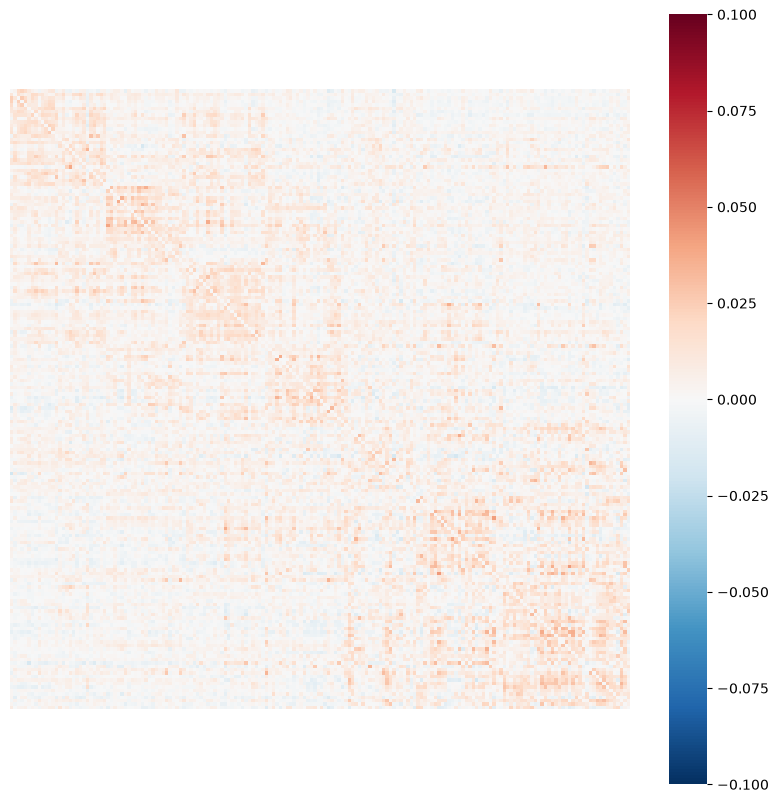

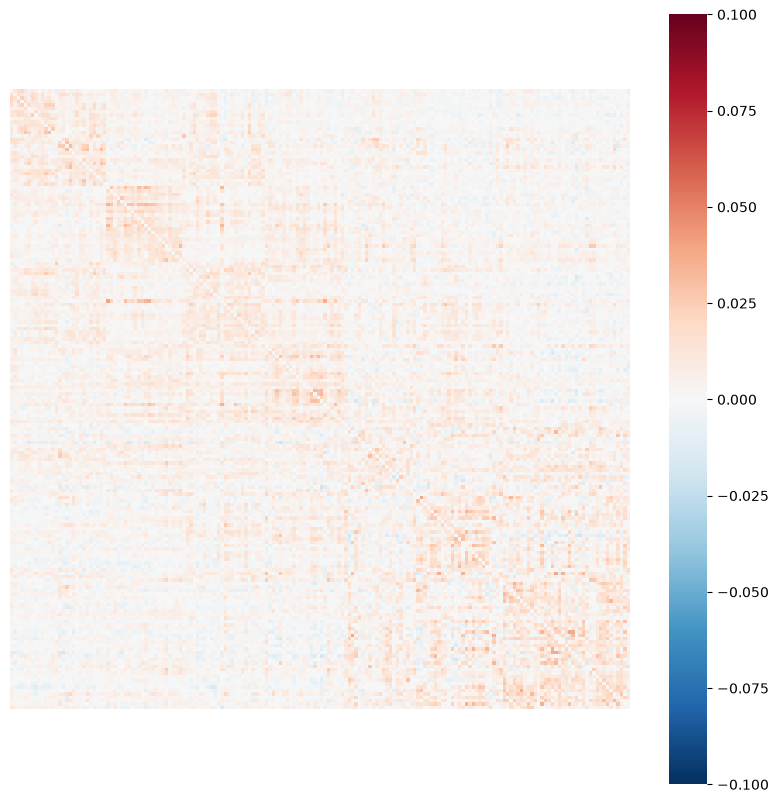

In [13]:
fig = plt.figure(figsize = (10, 10))
sns.heatmap(NPI_EC[neworder].T[neworder].T[:180, :180], vmin = -0.1, vmax = 0.1, cmap = 'RdBu_r', cbar = True, square = True, xticklabels = False, yticklabels = False)
plt.show()
fig = plt.figure(figsize = (10, 10))
sns.heatmap(
    NPI_EC[neworder].T[neworder].T[180:360, 180:360],
    vmin = -0.1, vmax = 0.1,
    cmap = 'RdBu_r',
    cbar = True, square = True,
    xticklabels = False, yticklabels = False
)
plt.show()

#新的脑区顺序下，前180个脑区两两之间的有效连接强度。颜色表示的增强还是抑制，以及强弱程度。蓝色表示抑制，红色表示增强
#展示了180个脑区 只看左半球内部的 EC 结构 整个大脑有360个脑区


阶段参数网格搜索

In [14]:
lesion_idx = 50
label_file = "./data/derived/Whole-brain_EC/MNI-MMP1/labels_MNI-MMP1.txt"
roi_names = load_mmp_labels_cortical_only(label_file)
# 运行分阶段网格搜索
search_res = run_stagewise_grid_search_with_constraints(
    base_config=BASE_CONFIG,
    model=ANN,
    inputs=inputs,
    signals=signals,
    roi_num=ROI_num,
    using_steps=using_steps,
    lesion_idx=lesion_idx,
    empirical_FC=empirical_FC,
    roi_names=roi_names,
    top_k=20,
    output_dir=OUTPUT_DIR,
)

BEST_CONFIG = search_res["BEST_CONFIG"]
import json
# 保存
with open("./results/grid_search/BEST_CONFIG.json", "w", encoding="utf-8") as f:
    json.dump(BEST_CONFIG, f, indent=2, ensure_ascii=False)
# 下次读取
# with open("./results/grid_search/BEST_CONFIG.json", "r", encoding="utf-8") as f:
#     BEST_CONFIG = json.load(f)


Stage 1-A: n_seed_windows convergence grid
[Stage1 seed grid] n_seed_windows=8
[Stage1 seed grid] n_seed_windows=16
[Stage1 seed grid] n_seed_windows=32
[Stage1 seed grid] n_seed_windows=64
[Stage1 seed grid] n_seed_windows=128
[Stage1 seed grid] selected n_seed_windows = 32
[Saved] ./grid_search/stage1_seed_grid_summary.csv
[Saved figure] ./grid_search/stage1_response_vector_convergence.png
[Saved figure] ./grid_search/stage1_top20_roi_stability.png
[Saved figure] ./grid_search/stage1_top20_rank_stability.png

Stage 1-B: lesion_strength / horizon sensitivity
[Stage1 sensitivity] reference=(0.5, 20)
[Stage1 sensitivity] lesion_strength=0.3, horizon=10
[Stage1 sensitivity] lesion_strength=0.3, horizon=20
[Stage1 sensitivity] lesion_strength=0.3, horizon=30
[Stage1 sensitivity] lesion_strength=0.3, horizon=40
[Stage1 sensitivity] lesion_strength=0.5, horizon=10
[Stage1 sensitivity] lesion_strength=0.5, horizon=20
[Stage1 sensitivity] lesion_strength=0.5, horizon=30
[Stage1 sensitivity] 

In [15]:
best_config_df = pd.read_csv("./results/grid_search/BEST_CONFIG.csv")
# 参数分组
STAGE_PARAM_GROUPS = {
    "Stage 1: Lesion response": [
        "n_seed_windows",
        "lesion_strength",
        "horizon",
        "lesion_mode",
    ],

    "Stage 2-A: Screening": [
        "tau",
        "max_candidate_nodes",
        "min_candidate_nodes",
        "top_k_direct_lagged",
        "top_k_response",
        "top_k_fc",
        "w_lagged",
        "w_response",
        "w_fc",
    ],

    "Stage 2-B: LPCMCI": [
        "tau_min",
        "tau_max",
        "pc_alpha",
        "alpha_level",
    ],

    "Stage 2-C: Lesion neighborhood": [
        "min_lesion_sub_nodes",
        "max_lesion_sub_nodes",
        "expand_to_second_order",
    ],

    "Stage 2-D: FC-constrained pruning": [
        "max_edges",
        "prune_alpha_level",
        "strong_quantile",
        "causal_weight",
        "fc_weight",
        "max_direct_lesion_edges",
        "stage2_selection_level",
    ],

    "Stage 3: Intervention search": [
        "alpha_traj",
        "beta_fc",
        "lambda_node",
        "lambda_strength",
        "lambda_temporal",
        "signs",
        "strengths",
        "schedules",
        "run_greedy",
        "max_interventions",
        "top_m_per_step",
        "min_marginal_gain",
        "force_accept_first",
    ],

    "Runtime": [
        "random_state",
        "batch_size",
        "standardize",
    ],
}
# 1. 整理成分阶段参数总表
rows = []
for stage_name, params in STAGE_PARAM_GROUPS.items():
    for p in params:
        matched = best_config_df[best_config_df["parameter"] == p]
        if len(matched) > 0:
            value = matched.iloc[0]["value"]
        else:
            value = None
        rows.append({
            "stage": stage_name,
            "parameter": p,
            "value": value,
        })
stage_config_df = pd.DataFrame(rows)
# 2. 分阶段显示
for stage_name in STAGE_PARAM_GROUPS.keys():
    print(stage_name)
    print(
        stage_config_df[stage_config_df["stage"] == stage_name][
            ["parameter", "value"]
        ].reset_index(drop=True)
    )
stage_config_df.to_csv(
    "./results/grid_search/BEST_CONFIG_by_stage.csv",
    index=False,
    encoding="utf-8-sig"
)

print("[Saved] ./results/grid_search/BEST_CONFIG_by_stage.csv")

Stage 1: Lesion response
         parameter     value
0   n_seed_windows        64
1  lesion_strength       0.5
2          horizon        20
3      lesion_mode  subtract
Stage 2-A: Screening
             parameter value
0                  tau     1
1  max_candidate_nodes    50
2  min_candidate_nodes    30
3  top_k_direct_lagged    40
4       top_k_response    30
5             top_k_fc     0
6             w_lagged   1.0
7           w_response   0.6
8                 w_fc   0.0
Stage 2-B: LPCMCI
     parameter  value
0      tau_min      1
1      tau_max      1
2     pc_alpha  0.005
3  alpha_level    NaN
Stage 2-C: Lesion neighborhood
                parameter value
0    min_lesion_sub_nodes     8
1    max_lesion_sub_nodes    30
2  expand_to_second_order  True
Stage 2-D: FC-constrained pruning
                 parameter               value
0                max_edges                  20
1        prune_alpha_level                0.01
2          strong_quantile                0.85
3         

Lesion response

In [16]:
stage1_res = compute_lesion_response(
    model=ANN,
    inputs=inputs,
    roi_num=ROI_num,
    roi_names=roi_names,
    using_steps=using_steps,
    lesion_idx=lesion_idx,
    
    horizon=BEST_CONFIG["horizon"],
    n_seed_windows=BEST_CONFIG["n_seed_windows"],
    lesion_strength=BEST_CONFIG["lesion_strength"],
    lesion_mode=BEST_CONFIG["lesion_mode"],
    random_state=BEST_CONFIG["random_state"],
    batch_size=BEST_CONFIG["batch_size"],
)
stage1_res.keys()
stage1_res["lesion_response_df"].head(20)

,roi,roi_name,response_abs,response_signed
0,50,L_1,0.065697,-0.065697
1,51,L_2,0.063563,-0.063059
2,8,L_3b,0.060690,-0.060663
3,46,L_7PC,0.057976,-0.057907
4,53,L_6d,0.057571,-0.057442
5,230,R_1,0.057261,-0.056999
6,231,R_2,0.057187,-0.056114
7,52,L_3a,0.056993,-0.056873
8,188,R_3b,0.056197,-0.055870
9,232,R_3a,0.053623,-0.053034


/root/NPCI/stage1_visualization.py:425: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.95])


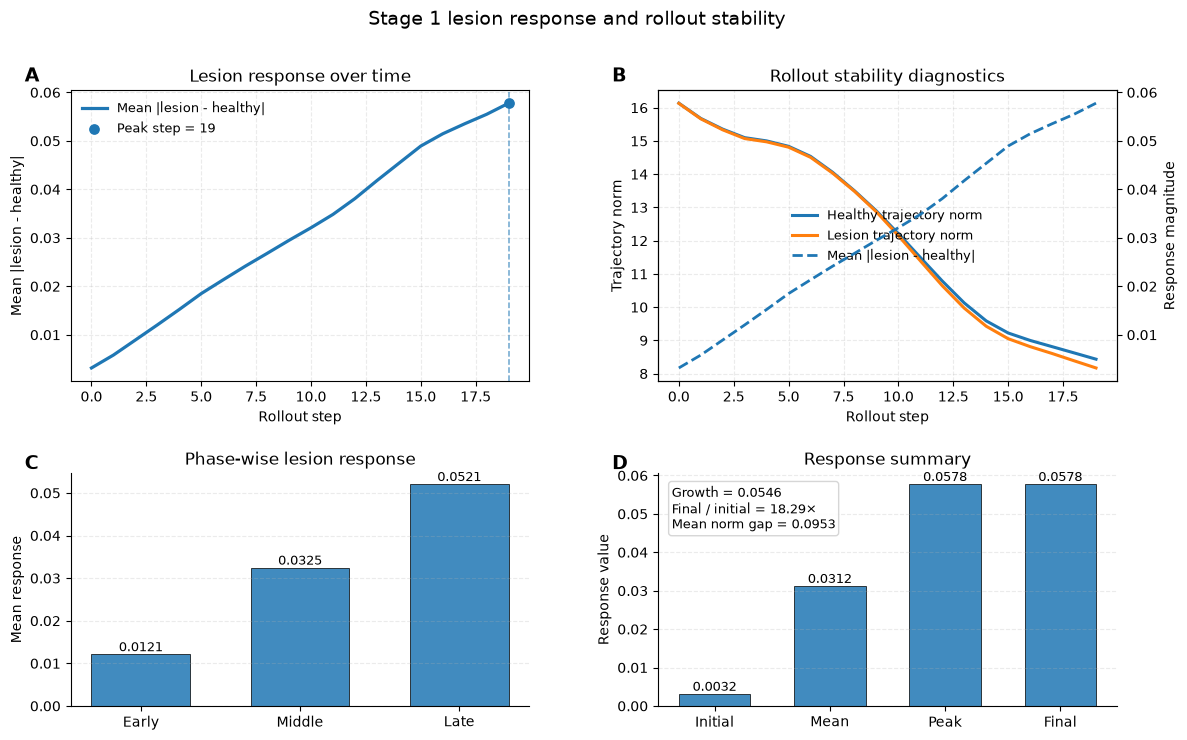

    phase  mean_response
0   Early       0.012146
1  Middle       0.032464
2    Late       0.052096
    metric     value
0  Initial  0.003160
1     Mean  0.031242
2     Peak  0.057776
3    Final  0.057776


{'n_seed': 64,
 'rollout_horizon': 20,
 'roi_num': 360,
 'initial_response': 0.003159591229632497,
 'mean_response': 0.031242214527446778,
 'peak_response': 0.05777638405561447,
 'peak_step': 19,
 'final_response': 0.05777638405561447,
 'growth_abs': 0.054616792825981975,
 'growth_ratio': 18.286031273750755,
 'norm_gap_mean': 0.09525679301205807,
 'norm_gap_final': 0.26413424428940147}

In [17]:
diag2 = plot_stage1_response_and_stability(
    stage1_res,
    figsize=(13.5, 8.0),
    save_path="./results/stage1_response_and_stability_combo.png",
)

print(diag2["phase_df"])
print(diag2["summary_df"])
diag2["diagnostics"]

<Axes: title={'center': 'Top 20 lesion-response ROIs'}, ylabel='Mean |lesion - healthy|'>

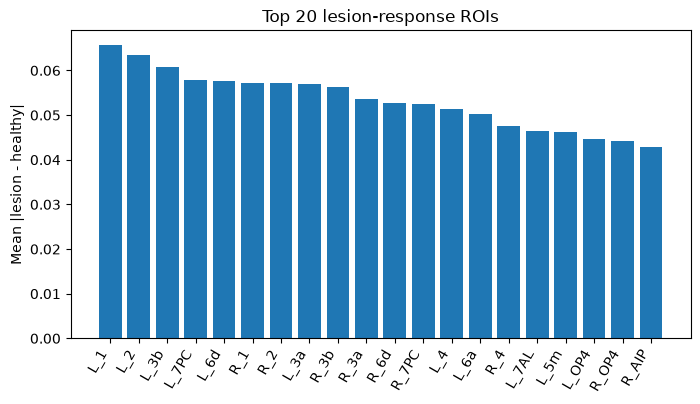

In [18]:
plot_top_response_bar(stage1_res, top_k=20,roi_names=roi_names,show_roi_id=False)

In [19]:
# 生成并保存 mmp360_centroids.csv
centroid_df = compute_mmp360_centroids(
    dlabel_path=dlabel_path,
    left_surf_path=left_surf_path,
    right_surf_path=right_surf_path,
)
centroid_df["roi_name_std"] = centroid_df["roi_name"].apply(standardize_mmp_name)
print("Number of centroids:", len(centroid_df))
print(centroid_df.head())

centroid_df.to_csv(out_csv_path, index=False, encoding="utf-8-sig")
print(f"Saved to: {out_csv_path}")

pixdim[1,2,3] should be non-zero; setting 0 dims to 1


Number of centroids: 360
   label_id   roi_name hemi          x          y          z  n_vertices  \
0       181   L_V1_ROI    L -11.487024 -81.522721   1.665239         831   
1       182  L_MST_ROI    L -43.708631 -68.772403   7.232940          73   
2       183   L_V6_ROI    L -12.989170 -77.504467  29.401838         114   
3       184   L_V2_ROI    L -10.701199 -81.900865   4.141142         619   
4       185   L_V3_ROI    L -16.650090 -86.649342   6.021596         337   

  roi_name_std  
0         L_V1  
1        L_MST  
2         L_V6  
3         L_V2  
4         L_V3  
Saved to: ./MNI-MMP_centroid/mmp360_centroids.csv


In [20]:
# 和 Stage 1 lesion response 结果做合并
lesion_df = stage1_res["lesion_response_df"].copy()
lesion_df["roi_name_std"] = lesion_df["roi_name"].apply(standardize_mmp_name)

centroid_df["roi_name_std"] = centroid_df["roi_name"].apply(standardize_mmp_name)

brainmap_df = lesion_df.merge(
    centroid_df[
        [
            "roi_name_std",
            "label_id",
            "roi_name",
            "hemi",
            "x",
            "y",
            "z",
            "n_vertices",
        ]
    ].rename(columns={"roi_name": "roi_name_mmp"}),
    on="roi_name_std",
    how="left"
)

print("Stage1 rows:", len(lesion_df))
print("Merged rows:", len(brainmap_df))
print("Missing centroid rows:", brainmap_df["x"].isna().sum())
brainmap_df.to_csv("./data/derived/MNI-MMP_centroid/stage1_brainmap_df.csv", index=False, encoding="utf-8-sig")
print("Saved: ./data/derived/MNI-MMP_centroid/stage1_brainmap_df.csv")
brainmap_df.head()

Stage1 rows: 360
Merged rows: 360
Missing centroid rows: 0
Saved: ./MNI-MMP_centroid/stage1_brainmap_df.csv


,roi,roi_name,response_abs,response_signed,roi_name_std,label_id,roi_name_mmp,hemi,x,y,z,n_vertices
0,50,L_1,0.065697,-0.065697,L_1,231,L_1_ROI,L,-44.994062,-25.264478,52.284173,401
1,51,L_2,0.063563,-0.063059,L_2,232,L_2_ROI,L,-35.859237,-34.796621,52.598390,574
2,8,L_3b,0.060690,-0.060663,L_3b,189,L_3b_ROI,L,-37.012333,-23.630290,52.148540,574
3,46,L_7PC,0.057976,-0.057907,L_7PC,227,L_7PC_ROI,L,-31.680263,-48.905361,58.318566,171
4,53,L_6d,0.057571,-0.057442,L_6d,234,L_6d_ROI,L,-32.019137,-13.248388,62.935249,154


In [21]:
# 保存对齐后的坐标表
mmp360_centroids_aligned = brainmap_df[["roi","roi_name","roi_name_std","label_id","hemi","x","y","z","n_vertices",]].copy()
mmp360_centroids_aligned = mmp360_centroids_aligned.sort_values("roi").reset_index(drop=True)
mmp360_centroids_aligned.to_csv(
    "./data/derived/MNI-MMP_centroid/mmp360_centroids_aligned_to_model.csv",
    index=False,
    encoding="utf-8-sig"
)
mmp360_centroids_aligned.head()

,roi,roi_name,roi_name_std,label_id,hemi,x,y,z,n_vertices
0,0,L_V1,L_V1,181,L,-11.487024,-81.522721,1.665239,831
1,1,L_MST,L_MST,182,L,-43.708631,-68.772403,7.232940,73
2,2,L_V6,L_V6,183,L,-12.989170,-77.504467,29.401838,114
3,3,L_V2,L_V2,184,L,-10.701199,-81.900865,4.141142,619
4,4,L_V3,L_V3,185,L,-16.650090,-86.649342,6.021596,337


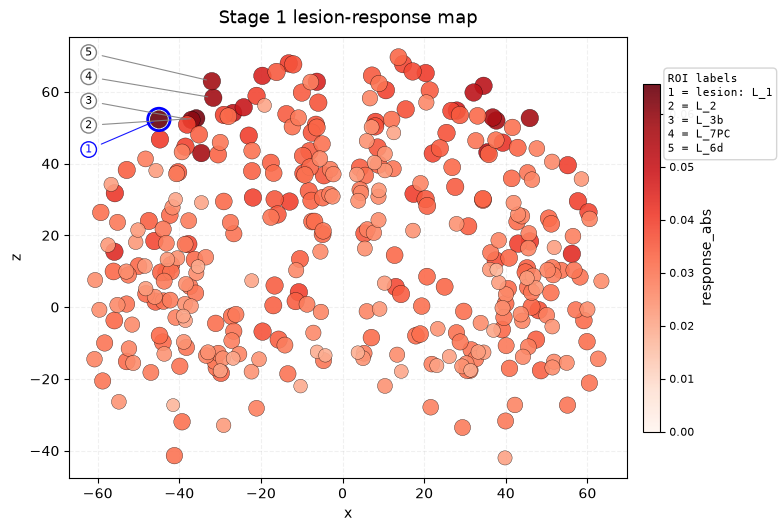

In [22]:
fig, ax = plot_stage1_centroid_brainmap_paper(
    brainmap_df=brainmap_df,
    value_col="response_abs",  #也可response_signed
    lesion_idx=lesion_idx,
    top_k_label=5,
    cmap=None,
    title="Stage 1 lesion-response map",
    save_path="./results/stage1_xz_response_abs_numbered.png"
)

pixdim[1,2,3] should be non-zero; setting 0 dims to 1
/root/NPCI/stage1_visualization.py:605: RuntimeWarning: Mean of empty slice
  face_values = np.nanmean(vertex_values[faces], axis=1)


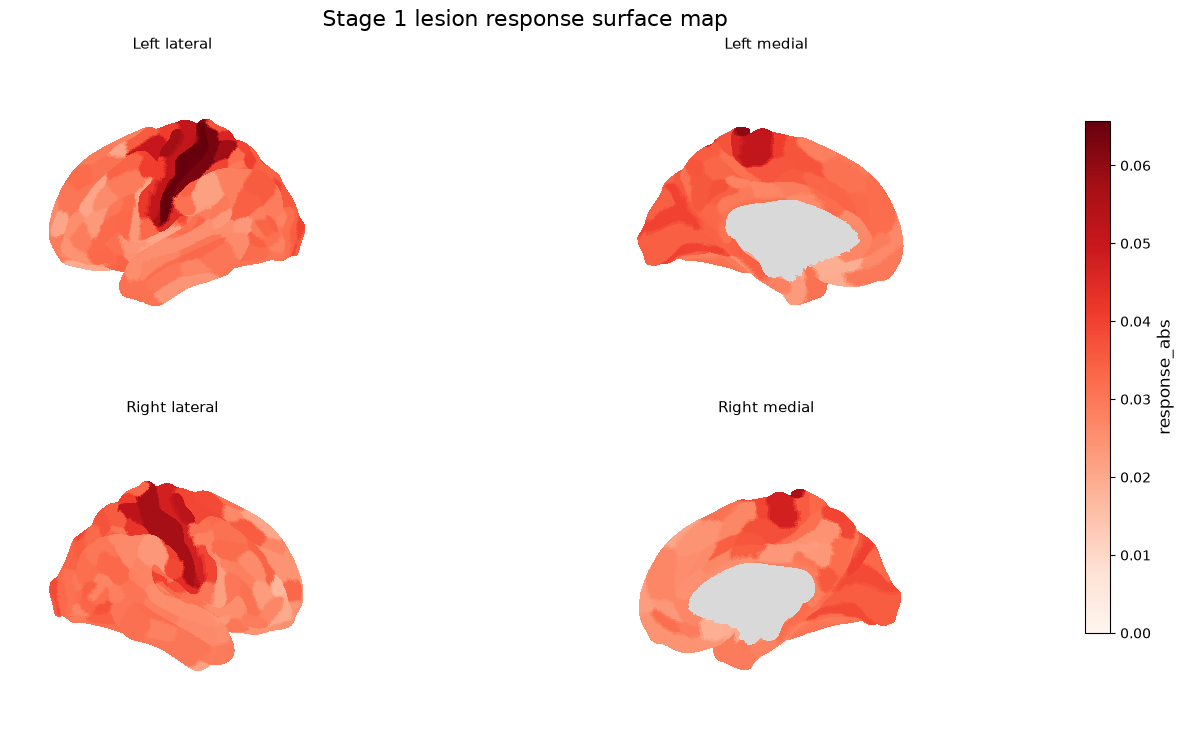

In [23]:
dlabel_path = r"./data/derived/MNI-MMP_centroid/HCP_MMP1.0_Glasser.32k_fs_LR.dlabel.nii"
left_surf_path = r"./data/derived/MNI-MMP_centroid/S1200.L.midthickness_MSMAll.32k_fs_LR.surf.gii"
right_surf_path = r"./data/derived/MNI-MMP_centroid/S1200.R.midthickness_MSMAll.32k_fs_LR.surf.gii"

lesion_df = stage1_res["lesion_response_df"].copy()
lesion_idx = 50
fig_surface, axes_surface = plot_stage1_surface_brainmap(
    dlabel_path=dlabel_path,
    left_surf_path=left_surf_path,
    right_surf_path=right_surf_path,
    lesion_df=lesion_df,
    aligned_centroid_df=mmp360_centroids_aligned,
    lesion_idx=lesion_idx,
    value_col="response_abs",
    cmap="Reds",
    save_path="./results/stage1_surface_response.png",
    suptitle="Stage 1 lesion response surface map"
)

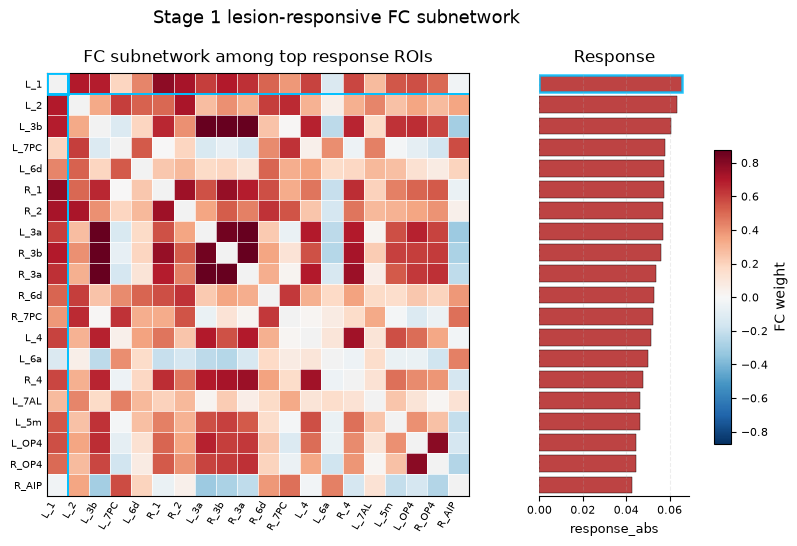

In [24]:
node_subset = get_top_response_node_subset(
    brainmap_df=brainmap_df,
    value_col="response_abs",
    lesion_idx=lesion_idx,
    top_n=30
)

edge_df_top_response = build_high_fc_edge_df(
    fc_matrix=empirical_FC_t1,
    node_subset=node_subset,
    edge_mode="top_k_per_node",
    top_k_per_node=2
)

fig, axes, fc_subnet_info = plot_stage1_fc_subnetwork_matrix(
    brainmap_df=brainmap_df,
    fc_matrix=empirical_FC_t1,
    lesion_idx=lesion_idx,
    value_col="response_abs",
    roi_names=roi_names,
    node_subset=node_subset,
    top_k=20,
    lesion_first=True,
    title="Stage 1 lesion-responsive FC subnetwork",
    save_path="./results/stage1_fc_subnetwork_matrix_paper.png",
)

Local lpcmci

In [25]:
# whole-brain lagged candidate screening
# 全脑范围内计算 Xi(t-1) → Xj(t) 的滞后关联强度；
# 结合 Stage 1 病灶响应先验；
# 筛出病灶相关候选节点；
# 暂时不让 FC 参与筛选，保证 FC 只在后面用于图压缩。
screen_res = run_lagged_candidate_screening(
    signals=signals,
    lesion_idx=lesion_idx,
    roi_names=roi_names,
    lesion_response_prior=stage1_res,     # Stage 1 dynamic abnormality prior
    empirical_FC=None,                    # keep FC out of screening; FC is used only in pruning
    
    tau=BEST_CONFIG["tau"],
    max_candidate_nodes=BEST_CONFIG["max_candidate_nodes"],
    min_candidate_nodes=BEST_CONFIG["min_candidate_nodes"],
    top_k_direct_lagged=BEST_CONFIG["top_k_direct_lagged"],
    top_k_response=BEST_CONFIG["top_k_response"],
    top_k_fc=BEST_CONFIG["top_k_fc"],

    w_lagged=BEST_CONFIG["w_lagged"],
    w_response=BEST_CONFIG["w_response"],
    w_fc=BEST_CONFIG["w_fc"],

    standardize=BEST_CONFIG["standardize"],
)

print(screen_res["info"])
print(screen_res["candidate_nodes"][:20])
screen_res["node_score_df"].head(30)

{'lesion_idx': 50, 'roi_num': 360, 'tau': 1, 'n_candidate_nodes': 49, 'max_candidate_nodes': 50, 'min_candidate_nodes': 30, 'screening_role': 'high-recall candidate generation before LPCMCI'}
[50, 51, 8, 230, 231, 188, 52, 232, 7, 233, 46, 226, 53, 187, 35, 99, 41, 280, 279, 100]


,node,roi_name,parent_proxy,child_proxy,parent_proxy_norm,child_proxy_norm,lagged_direct_score,lagged_direct_norm,lesion_response_prior,lesion_response_norm,fc_lesion_abs,fc_norm,final_screen_score,selected,lagged_role
0,50,L_1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,2.600000,True,lesion node
1,51,L_2,0.858886,0.906909,0.968309,1.000000,0.906909,1.000000,0.063563,1.000000,0.0,0.0,1.600000,True,mixed lagged proxy
2,8,L_3b,0.853369,0.881852,0.962090,0.972372,0.881852,0.972372,0.060690,0.954792,0.0,0.0,1.545247,True,mixed lagged proxy
3,230,R_1,0.886995,0.894816,1.000000,0.986666,0.894816,0.986666,0.057261,0.900844,0.0,0.0,1.527172,True,mixed lagged proxy
4,231,R_2,0.817322,0.881250,0.921450,0.971707,0.881250,0.971707,0.057187,0.899686,0.0,0.0,1.511519,True,mixed lagged proxy
5,188,R_3b,0.828242,0.860001,0.933761,0.948277,0.860001,0.948277,0.056197,0.884104,0.0,0.0,1.478740,True,mixed lagged proxy
6,52,L_3a,0.829196,0.835862,0.934837,0.921660,0.835862,0.921660,0.056993,0.896637,0.0,0.0,1.459643,True,mixed lagged proxy
7,232,R_3a,0.821825,0.835367,0.926527,0.921115,0.835367,0.921115,0.053623,0.843615,0.0,0.0,1.427284,True,mixed lagged proxy
8,7,L_4,0.831530,0.778710,0.937468,0.858642,0.831530,0.916884,0.051406,0.808734,0.0,0.0,1.402124,True,mixed lagged proxy
9,233,R_6d,0.801760,0.777701,0.903906,0.857530,0.801760,0.884058,0.052735,0.829647,0.0,0.0,1.381847,True,mixed lagged proxy


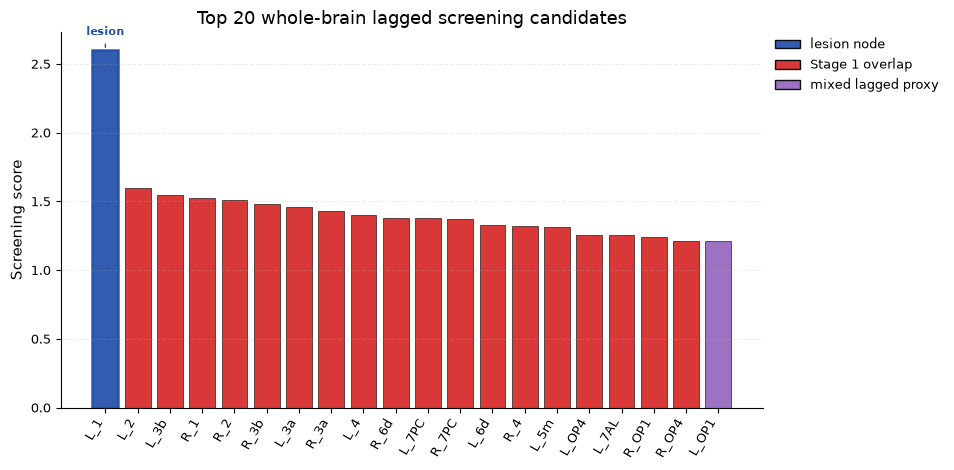

In [26]:
plot_screening_node_scores(
    node_score_df=screen_res["node_score_df"],
    top_k=20,
    roi_names=roi_names,
    lesion_idx=lesion_idx,
    stage1_res=stage1_res,
    x_rotation=60
)

In [27]:
# LPCMCI on screened candidate subnetwork
# node_map 的作用是：LPCMCI 在局部子网上跑，内部编号是 0,1,2,...
# node_map 负责把局部编号映射回原始全脑 ROI 编号。
local_lpcmci_res, node_map = run_candidate_subnetwork_lpcmci(
    signals=signals,
    candidate_nodes=screen_res["candidate_nodes"],
    tau_min=BEST_CONFIG["tau_min"],
    tau_max=BEST_CONFIG["tau_max"],
    pc_alpha=BEST_CONFIG["pc_alpha"],
    verbosity=0,
    standardize=BEST_CONFIG["standardize"],
    max_cond_px=1,
    max_p_global=2,
    max_p_non_ancestral=2,
    max_q_global=5,
    max_pds_set=8,
)
# 把 LPCMCI 结果转成全脑 ROI 边表，不使用同期边。
local_edge_df = lpcmci_to_edge_df(
    local_lpcmci_res,
    node_map=node_map,
    include_contemp=False,
    lag_only=True,
    alpha_level=BEST_CONFIG["alpha_level"],
)

print("local LPCMCI lagged edges:", len(local_edge_df))
local_edge_df.head(20)

[Stage2] Running LPCMCI on screened subnetwork: n_nodes=49, tau_max=1
local LPCMCI lagged edges: 861


,src,dst,src_local,dst_local,tau,link,val,abs_val,p
0,151,12,41,40,1,<->,0.418325,0.418325,1.595818e-197
1,151,15,41,30,1,<->,0.393153,0.393153,1.130010e-172
2,151,155,41,46,1,<->,0.375092,0.375092,3.944748e-156
3,226,233,11,9,1,<->,-0.329416,0.329416,9.227202e-119
4,95,49,22,47,1,<->,0.311999,0.311999,4.249043e-106
5,182,2,36,26,1,<->,-0.309068,0.309068,4.753663e-104
6,226,50,11,0,1,<->,-0.306664,0.306664,2.188802e-102
7,2,182,26,36,1,<->,0.303158,0.303158,5.461573e-100
8,226,46,11,10,1,<->,-0.295964,0.295964,3.415976e-95
9,151,156,41,39,1,<->,0.284283,0.284283,1.209924e-87


In [28]:
# lesion-centered first/second-order LPCMCI neighborhood：提取病灶中心一阶 / 二阶邻域
#先取病灶节点的一阶因果邻居；
# 如果一阶邻居太少，扩展到二阶；
# 如果节点太多，按 LPCMCI 强度压缩节点。
lesion_nodes, lesion_sub_edges, subnet_info = extract_lesion_neighborhood(
    edge_df=local_edge_df,
    lesion_idx=lesion_idx,
    min_nodes=BEST_CONFIG["min_lesion_sub_nodes"],
    max_nodes=BEST_CONFIG["max_lesion_sub_nodes"],
    direction="both",
    expand_to_second_order=BEST_CONFIG["expand_to_second_order"],
)

print(subnet_info)
lesion_sub_edges.head(20)

{'lesion_idx': 50, 'hop1_nodes': [2, 7, 8, 9, 12, 15, 39, 51, 53, 54, 55, 100, 101, 103, 151, 155, 182, 187, 188, 219, 226, 231, 233, 234, 280, 283, 296, 347], 'hop2_nodes': [], 'used_hop': 1, 'n_nodes': 29, 'n_edges': 354}


,src,dst,src_local,dst_local,tau,link,val,abs_val,p
0,151,12,41,40,1,<->,0.418325,0.418325,1.595818e-197
1,151,15,41,30,1,<->,0.393153,0.393153,1.130010e-172
2,151,155,41,46,1,<->,0.375092,0.375092,3.944748e-156
3,226,233,11,9,1,<->,-0.329416,0.329416,9.227202e-119
4,182,2,36,26,1,<->,-0.309068,0.309068,4.753663e-104
5,226,50,11,0,1,<->,-0.306664,0.306664,2.188802e-102
6,2,182,26,36,1,<->,0.303158,0.303158,5.461573e-100
7,233,226,9,11,1,<->,0.277222,0.277222,2.897784e-83
8,219,231,20,4,1,<->,0.276662,0.276662,6.370153e-83
9,151,226,41,11,1,<->,0.272984,0.272984,1.069905e-80


In [29]:
# FC约束删边，规则：
#直接连接 lesion 的边优先保留；
# p 值显著且 LPCMCI 强度高的边优先保留；
# FC 只用于边太多时的压缩；
# FC 不用于否定强因果边。
lesion_core_edges, prune_info = prune_edges_by_lpcmci_fc_constraints(
    sub_edges=lesion_sub_edges,
    empirical_FC=empirical_FC,
    lesion_idx=lesion_idx,
    max_edges=BEST_CONFIG["max_edges"],
    alpha_level=BEST_CONFIG["prune_alpha_level"],
    strong_quantile=BEST_CONFIG["strong_quantile"],
    causal_weight=BEST_CONFIG["causal_weight"],
    fc_weight=BEST_CONFIG["fc_weight"],
    max_direct_lesion_edges=BEST_CONFIG["max_direct_lesion_edges"],
)

print(prune_info)
lesion_core_edges.head(20)

{'reason': 'strong_edges_exceed_limit', 'n_before': 354, 'n_tier1_direct_strong': 6, 'n_tier2_strong': 47, 'n_after': 20, 'strong_abs_val_threshold': 0.16067388028850849, 'fc_used': False}


,src,dst,src_local,dst_local,tau,link,val,abs_val,p,fc_abs,causal_norm,fc_norm,fused_score,direct_lesion_edge,strong_significant_edge
0,226,50,11,0,1,<->,-0.306664,0.306664,2.188802e-102,0.382426,0.703964,0.468606,0.656893,True,True
1,54,50,35,0,1,<->,0.225744,0.225744,4.220632e-55,0.242579,0.489429,0.296142,0.450772,True,True
2,219,50,20,0,1,<->,0.192261,0.192261,3.572830e-40,0.514435,0.400660,0.631404,0.446809,True,True
3,182,50,36,0,1,<->,0.179388,0.179388,4.029852e-35,0.192774,0.366531,0.234722,0.340169,True,True
4,12,50,40,0,1,<->,-0.173391,0.173391,6.969843e-33,0.013405,0.350631,0.013519,0.283209,True,True
5,50,219,0,20,1,<->,0.163392,0.163392,2.401057e-29,0.514435,0.324122,0.631404,0.385578,True,True
6,151,12,41,40,1,<->,0.418325,0.418325,1.595818e-197,0.692238,1.000000,0.850676,0.970135,False,True
7,151,15,41,30,1,<->,0.393153,0.393153,1.130010e-172,0.618887,0.933264,0.760217,0.898655,False,True
8,151,155,41,46,1,<->,0.375092,0.375092,3.944748e-156,0.231929,0.885380,0.283009,0.764906,False,True
9,226,233,11,9,1,<->,-0.329416,0.329416,9.227202e-119,0.616621,0.764285,0.757422,0.762912,False,True


In [30]:
# 生成干预候选节点
candidate_df = build_intervention_candidates_from_core(
    lesion_core_edges,
    lesion_idx=lesion_idx,
    exclude_lesion=True,
)

candidate_df.head(20)

,node,candidate_score,is_upstream_of_lesion,is_downstream_of_lesion
0,151,4.301960,False,False
1,219,4.063608,True,True
2,226,3.621117,True,False
3,12,2.896044,True,False
4,182,2.864176,True,False
5,54,1.912310,True,False
6,231,1.667786,False,False
7,2,1.524007,False,False
8,233,1.415123,False,False
9,15,0.898655,False,False


In [31]:
# 证明方法合理性
overlap_info = compute_stage1_screening_overlap(
    stage1_res=stage1_res,
    screen_res=screen_res,
    stage1_top_k=30,
    screening_top_k=30,
)

overlap_info

{'stage1_top_k': 30,
 'screening_top_k': 30,
 'stage1_nodes': [7,
  8,
  9,
  11,
  35,
  41,
  46,
  49,
  50,
  51,
  52,
  53,
  54,
  55,
  95,
  99,
  182,
  187,
  188,
  221,
  226,
  230,
  231,
  232,
  233,
  279,
  280,
  283,
  295,
  296],
 'screening_nodes': [2,
  7,
  8,
  35,
  41,
  46,
  50,
  51,
  52,
  53,
  95,
  99,
  100,
  101,
  187,
  188,
  215,
  218,
  219,
  221,
  226,
  230,
  231,
  232,
  233,
  279,
  280,
  283,
  295,
  336],
 'overlap_nodes': [7,
  8,
  35,
  41,
  46,
  50,
  51,
  52,
  53,
  95,
  99,
  187,
  188,
  221,
  226,
  230,
  231,
  232,
  233,
  279,
  280,
  283,
  295],
 'n_stage1_nodes': 30,
 'n_screening_nodes': 30,
 'n_overlap_nodes': 23,
 'n_union_nodes': 37,
 'stage1_screen_overlap_topK': 0.7666666666666667,
 'screening_overlap_precision': 0.7666666666666667,
 'jaccard': 0.6216216216216216,
 'overlap_judgement': 'moderate',
 'stage1_score_col': 'response_abs',
 'screening_score_col': 'final_screen_score'}

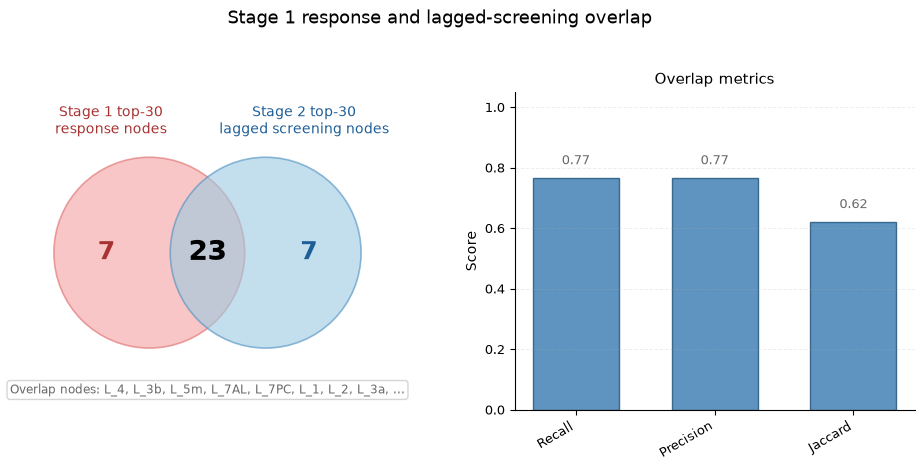

(<Figure size 980x480 with 2 Axes>,
 (<Axes: >, <Axes: title={'center': 'Overlap metrics'}, ylabel='Score'>))

In [32]:
# overlap图
plot_stage2_screening_overlap(
    overlap_info=overlap_info,
    roi_names=roi_names,
    title="Stage 1 response and lagged-screening overlap",
    max_overlap_show=8,
    save_path="./results/stage1_stage2_overlap.png"
)

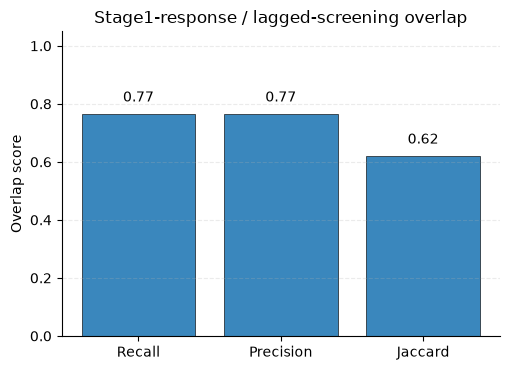

(<Figure size 520x380 with 1 Axes>,
 <Axes: title={'center': 'Stage1-response / lagged-screening overlap'}, ylabel='Overlap score'>)

In [33]:
# 指标柱状图
plot_stage1_screening_overlap_metrics(
    overlap_info=overlap_info,
    save_path="./results/stage1_screening_overlap_metrics.png",
)

In [34]:
# 把结果写回去
screen_res["info"].update({
    "stage1_screen_overlap_topK": overlap_info["stage1_screen_overlap_topK"],
    "screening_overlap_precision": overlap_info["screening_overlap_precision"],
    "stage1_screen_jaccard": overlap_info["jaccard"],
    "overlap_judgement": overlap_info["overlap_judgement"],
    "overlap_nodes": overlap_info["overlap_nodes"],
})

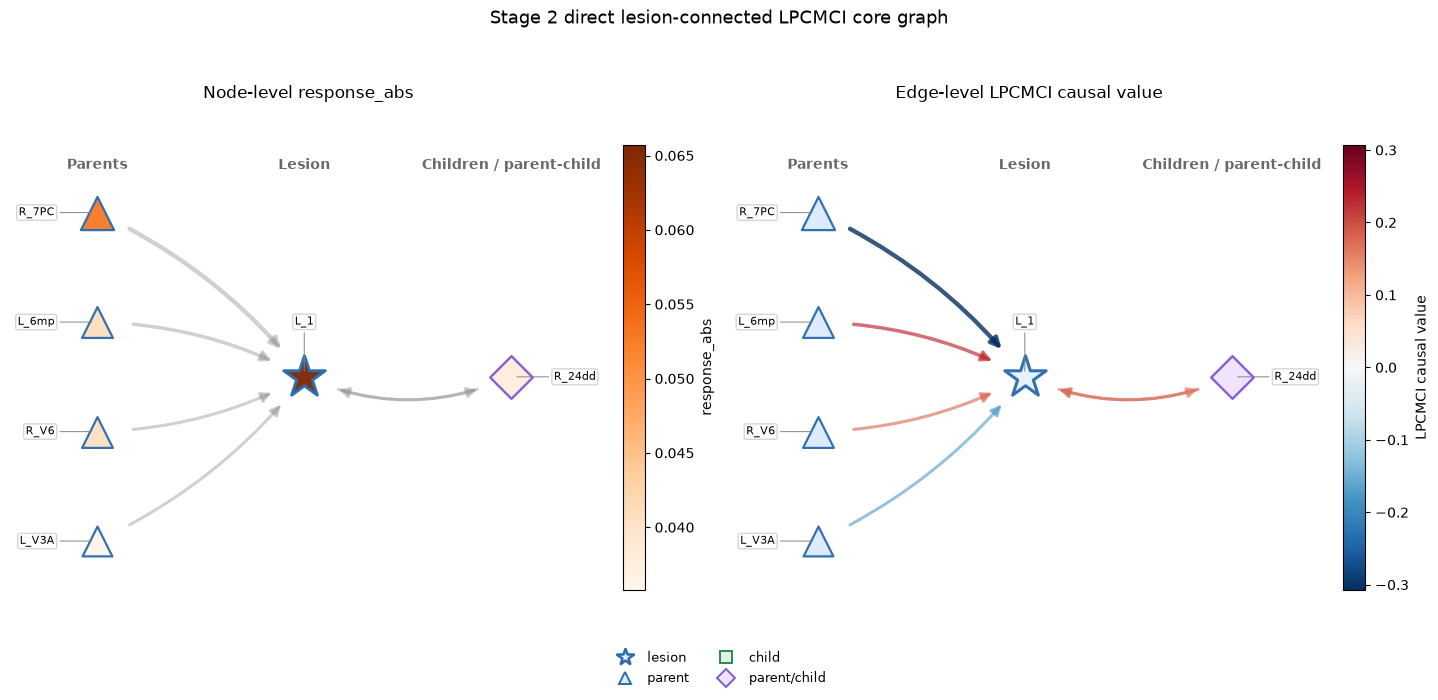

   src  dst  src_local  dst_local  tau link       val   abs_val  \
0  226   50         11          0    1  <-> -0.306664  0.306664   
1   54   50         35          0    1  <->  0.225744  0.225744   
2  219   50         20          0    1  <->  0.192261  0.192261   
3  182   50         36          0    1  <->  0.179388  0.179388   
4   12   50         40          0    1  <-> -0.173391  0.173391   

               p    fc_abs  causal_norm   fc_norm  fused_score  \
0  2.188802e-102  0.382426     0.703964  0.468606     0.656893   
1   4.220632e-55  0.242579     0.489429  0.296142     0.450772   
2   3.572830e-40  0.514435     0.400660  0.631404     0.446809   
3   4.029852e-35  0.192774     0.366531  0.234722     0.340169   
4   6.969843e-33  0.013405     0.350631  0.013519     0.283209   

   direct_lesion_edge  strong_significant_edge  
0                True                     True  
1                True                     True  
2                True                     True  
3   

In [35]:
# 直接 lesion 子图
direct_lesion_edges = lesion_core_edges[
    (lesion_core_edges["src"].astype(int) == int(lesion_idx))
    | (lesion_core_edges["dst"].astype(int) == int(lesion_idx))
].copy()

fig_core, axes_core, core_info = plot_lpcmci_lesion_core_graph(
    lesion_core_edges=direct_lesion_edges,
    lesion_idx=lesion_idx,
    candidate_df=candidate_df,
    stage1_res=stage1_res,
    roi_names=roi_names,
    node_score_source="response_abs",

    max_edges=30,
    top_score_nodes=12,
    top_label_k=8,

    edge_alpha=0.42,
    edge_width_scale=2.2,

    node_size_min=220,
    node_size_scale=440,
    lesion_node_size=980,

    title="Stage 2 direct lesion-connected LPCMCI core graph",
    save_path="./results/stage2_direct_lesion_core_graph_split.png",
)

print(core_info["edge_df_plotted"].head())

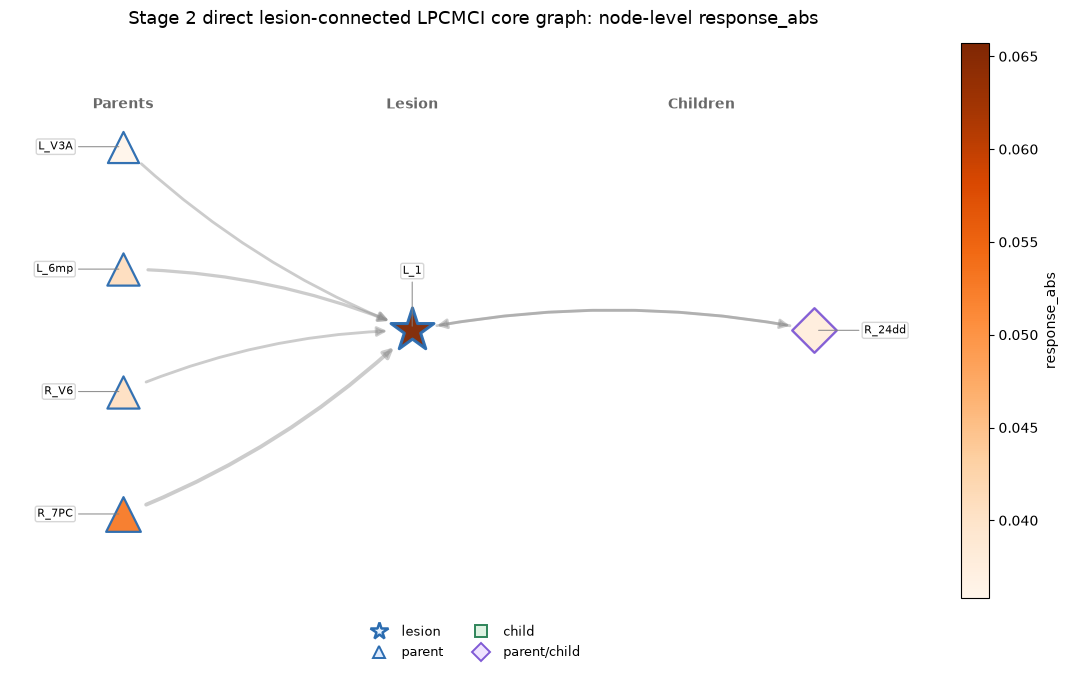

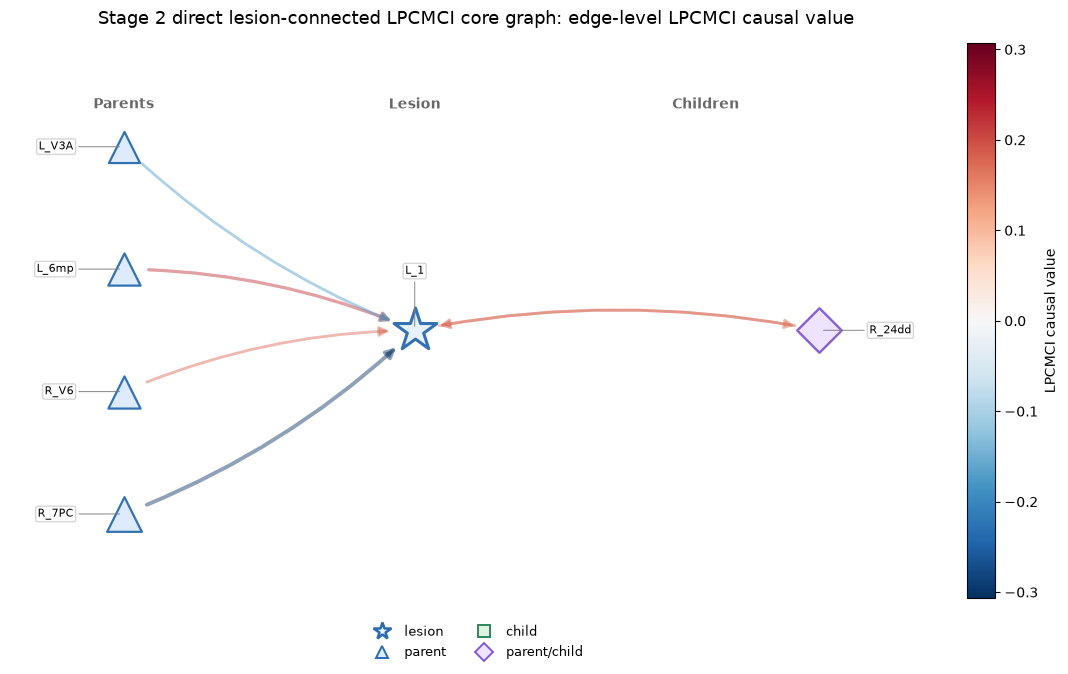

In [36]:
# 直接lesion子图
direct_lesion_edges = lesion_core_edges[
    (lesion_core_edges["src"].astype(int) == int(lesion_idx))
    | (lesion_core_edges["dst"].astype(int) == int(lesion_idx))
].copy()
fig_resp, ax_resp, fig_edge, ax_edge, graph_info = plot_lpcmci_lesion_core_graph_split(
    lesion_core_edges=direct_lesion_edges,
    lesion_idx=lesion_idx,
    candidate_df=candidate_df,
    stage1_res=stage1_res,
    roi_names=roi_names,
    node_score_source="response_abs",

    max_edges=30,
    top_score_nodes=12,
    top_label_k=8,

    edge_alpha=0.45,
    edge_width_scale=1.8,

    node_size_min=240,
    node_size_scale=480,
    lesion_node_size=1050,

    title_prefix="Stage 2 direct lesion-connected LPCMCI core graph",
    save_prefix="./results/stage2_direct_lesion_core_graph",
)

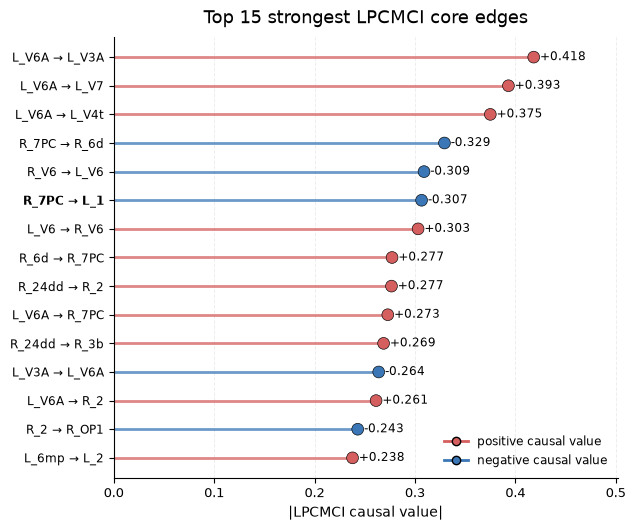

In [37]:
# 全局 Top-K strongest core edges
import importlib
import stage2_visualization
importlib.reload(stage2_visualization)
from stage2_visualization import *
fig, ax, top_edge_df = plot_stage2_top_core_edges(
    lesion_core_edges=lesion_core_edges,
    top_k=15,
    roi_names=roi_names,
    lesion_idx=lesion_idx,
    plot_type="lollipop",
    direct_lesion_only=False,   # 也可看lesion 直接相连的 Top-K core edges
    title="Top 15 strongest LPCMCI core edges",
    save_path="./results/stage2_top15_core_edges_lollipop.png",
)

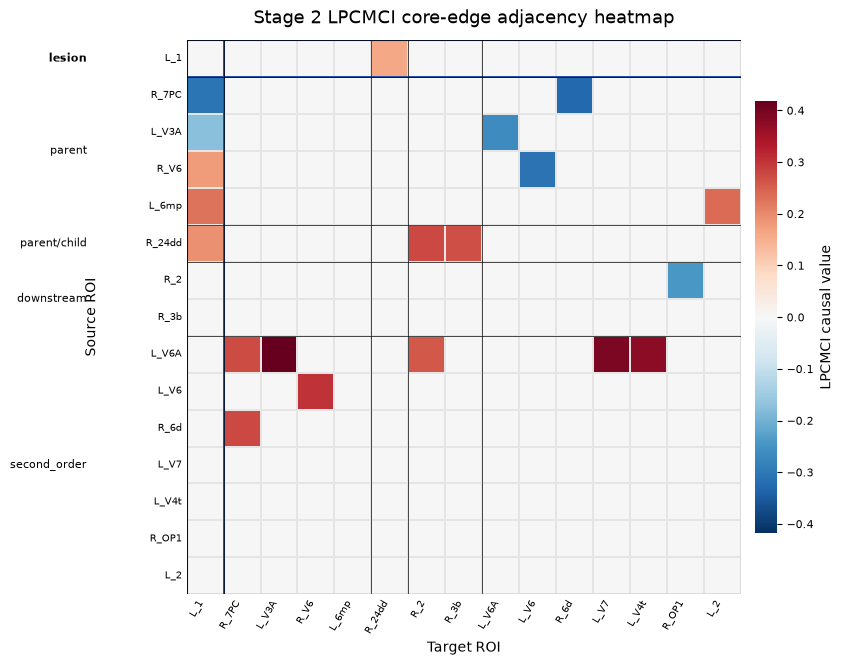

In [38]:
#邻接矩阵热图
fig, ax, heatmap_info = plot_lpcmci_adjacency_heatmap(
    lesion_core_edges=lesion_core_edges,   # 一定传 core edges，不要传 local edges
    lesion_idx=lesion_idx,
    candidate_df=candidate_df,
    stage1_res=stage1_res,
    roi_names=roi_names,
    node_score_source="response_abs",
    value_col="val",

    max_nodes=40,
    figsize=(10.5, 8.4),

    title="Stage 2 LPCMCI core-edge adjacency heatmap",
    grid_linewidth=0.04,

    save_path="./results/stage2_lpcmci_core_adjacency_heatmap.png"
)

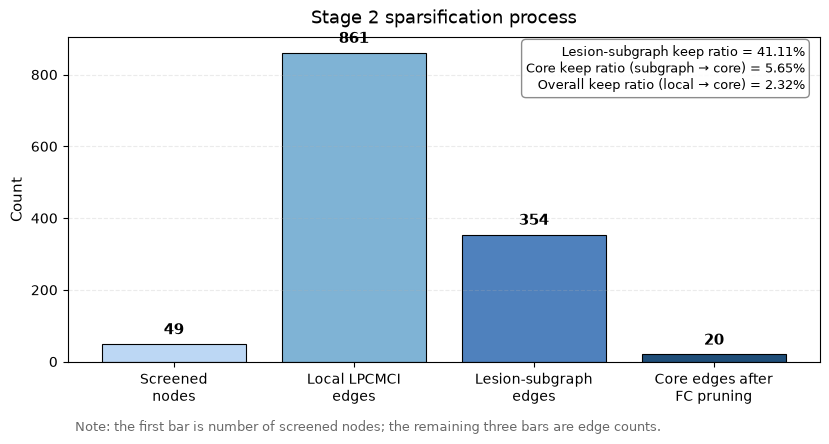

,stage,count
0,screened_nodes,49
1,local_edges,861
2,lesion_subgraph_edges,354
3,core_edges,20


In [39]:
# 图稀疏化过程柱状图
stage2_summary = {
    "n_screen_nodes": len(screen_res["candidate_nodes"]),
    "n_local_edges": len(local_edge_df),
    "n_lesion_sub_edges": len(lesion_sub_edges),
    "n_core_edges": len(lesion_core_edges),
}

fig, ax, sparsify_df = plot_stage2_sparsification_summary(
    summary=stage2_summary,
    title="Stage 2 sparsification process",
    save_path="./results/stage2_sparsification_summary.png",
)
sparsify_df

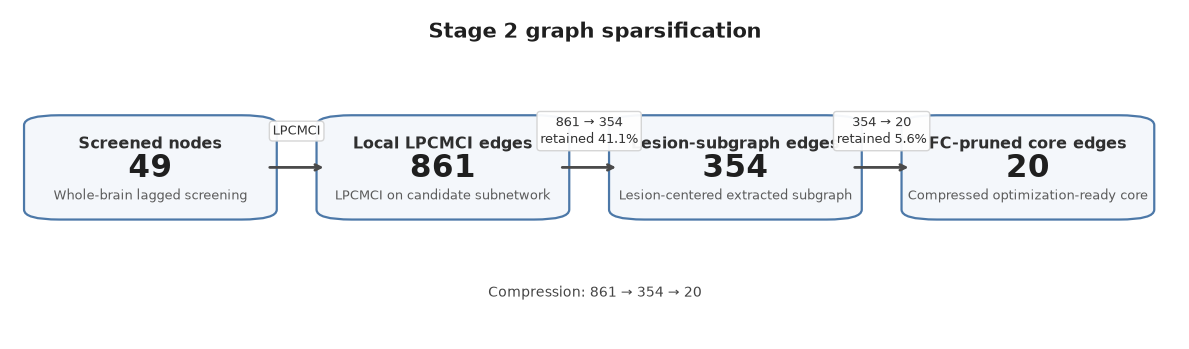

In [40]:
# 图稀疏化过程流程图
fig, ax = plot_stage2_sparsification_flowchart(
    summary=stage2_summary,
    title="Stage 2 graph sparsification",
    save_path="./results/stage2_sparsification_flowchart.png",
)

In [41]:
# 进入stage3 之前的质量检查
quality = check_stage2_quality(
    stage1_res=stage1_res,
    screen_res=screen_res,
    local_edge_df=local_edge_df,
    lesion_sub_edges=lesion_sub_edges,
    lesion_core_edges=lesion_core_edges,
    lesion_idx=lesion_idx,
    top_k=30
)

quality

{'stage1_screen_overlap_topK': 1.0,
 'n_screen_nodes': 49,
 'n_local_edges': 861,
 'local_edge_density': 0.36607142857142855,
 'n_lesion_sub_edges': 354,
 'n_direct_lesion_edges_before_prune': 40,
 'n_core_edges': 20,
 'n_direct_lesion_edges_after_prune': 6,
 'overlap_nodes': [7,
  8,
  9,
  11,
  35,
  41,
  46,
  49,
  50,
  51,
  52,
  53,
  54,
  55,
  95,
  99,
  182,
  187,
  188,
  221,
  226,
  230,
  231,
  232,
  233,
  279,
  280,
  283,
  295,
  296],
 'overlap_judgement': 'good',
 'density_judgement': 'too_dense',
 'core_judgement': 'enough_for_intervention'}

Intervention optimization

In [42]:
# 单节点 + greedy 多节点最优干预
candidate_nodes = candidate_df["node"].head(20).astype(int).drop_duplicates().tolist()
candidate_nodes = [
    n for n in candidate_nodes
    if int(n) != int(lesion_idx)
]
ROLLOUT_HORIZON = stage1_res["healthy_traj"].shape[1]
stage3_res = run_single_node_search(
    model=ANN,
    candidate_nodes=candidate_nodes,
    roi_num=ROI_num,
    using_steps=using_steps,
    lesion_idx=lesion_idx,

    seed_inputs=stage1_res["seed_inputs"],
    healthy_traj=stage1_res["healthy_traj"],
    lesion_traj=stage1_res["lesion_traj"],

    horizon=BEST_CONFIG["horizon"],
    lesion_strength=BEST_CONFIG["lesion_strength"],
    lesion_mode=BEST_CONFIG["lesion_mode"],

    signs=BEST_CONFIG["signs"],
    strengths=BEST_CONFIG["strengths"],
    schedules=BEST_CONFIG["schedules"],

    alpha_traj=BEST_CONFIG["alpha_traj"],
    beta_fc=BEST_CONFIG["beta_fc"],
    lambda_node=BEST_CONFIG["lambda_node"],
    lambda_strength=BEST_CONFIG["lambda_strength"],
    lambda_temporal=BEST_CONFIG["lambda_temporal"],

    batch_size=BEST_CONFIG["batch_size"],

    run_greedy=BEST_CONFIG["run_greedy"],
    max_interventions=BEST_CONFIG["max_interventions"],
    top_m_per_step=BEST_CONFIG["top_m_per_step"],
    min_marginal_gain=BEST_CONFIG["min_marginal_gain"],
    force_accept_first=BEST_CONFIG["force_accept_first"],
)

print(stage3_res["single_df"].head())
print(stage3_res["greedy_history"])
print(stage3_res["greedy_trial_df"].head())

print("Best single policy:")
print(stage3_res["best_single_policy"])

print("Best final policy:")
print(stage3_res["best_policy"])
print("Best final objective:")
print(stage3_res["best_objective"])
# 后面需要扩展时修改
# schedules=("constant","early_pulse","middle_pulse","late_pulse","ramp_up","ramp_decay","exponential_decay")

   node  sign  strength  schedule  objective  traj_recovery  fc_recovery  \
0   231     1       0.6  constant   0.600484       0.439736     0.215935   
1    51     1       0.4  constant   0.550868       0.438571     0.150372   
2    54     1       0.2  constant   0.512276       0.328482     0.234742   
3   233     1       0.3  constant   0.435360       0.330215     0.138931   
4   219     1       0.2  constant   0.374004       0.333245     0.055949   

   D_lesion_traj  D_policy_traj  D_lesion_fc  D_policy_fc  node_cost  \
0       0.684629       0.383573     1.393389     1.092508        1.0   
1       0.684629       0.384371     1.393389     1.183863        1.0   
2       0.684629       0.459740     1.393389     1.066303        1.0   
3       0.684629       0.458554     1.393389     1.199805        1.0   
4       0.684629       0.456480     1.393389     1.315431        1.0   

   strength_cost  temporal_cost  
0            0.6            0.0  
1            0.4            0.0  
2       

In [43]:
single_df = attach_candidate_scores(
    single_df=stage3_res["single_df"],
    candidate_df=candidate_df,
    roi_names=roi_names if "roi_names" in globals() else None,
)
single_df.head(10)
stage3_res["single_df_aug"] = attach_candidate_scores(
    single_df=stage3_res["single_df"],
    candidate_df=candidate_df,
    roi_names=roi_names if "roi_names" in globals() else None,
)

print(stage3_res["single_df_aug"].head(10))

   node roi_name  sign  strength     schedule  objective  traj_recovery  \
0   231      R_2     1       0.6     constant   0.600484       0.439736   
1    51      L_2     1       0.4     constant   0.550868       0.438571   
2    54    L_6mp     1       0.2     constant   0.512276       0.328482   
3   233     R_6d     1       0.3     constant   0.435360       0.330215   
4   219   R_24dd     1       0.2     constant   0.374004       0.333245   
5   151    L_V6A     1       0.2     constant   0.264071       0.187173   
6   226    R_7PC     1       0.7      ramp_up   0.233655       0.167968   
7   188     R_3b     1       0.4  early_pulse   0.189926       0.141643   
8   280    R_OP1     1       0.5      ramp_up   0.149304       0.085092   
9    15     L_V7     1       0.2     constant   0.124542       0.087841   

   fc_recovery  D_lesion_traj  D_policy_traj  D_lesion_fc  D_policy_fc  \
0     0.215935       0.684629       0.383573     1.393389     1.092508   
1     0.150372       0.684

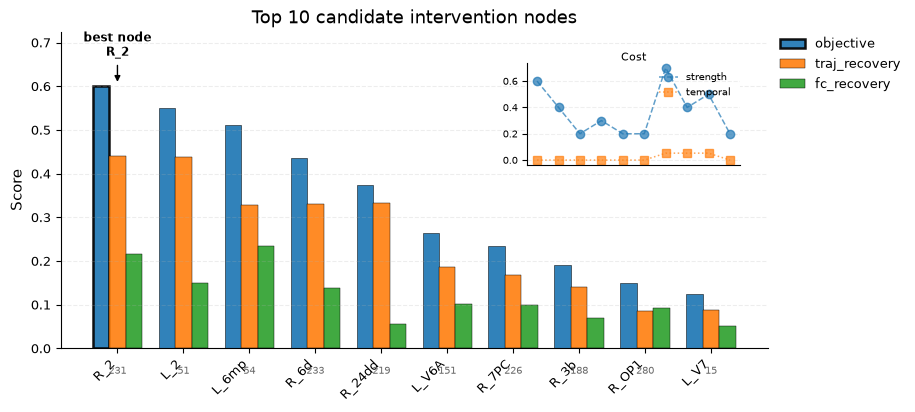

In [44]:
# 单节点objective ranking bar
fig, ax = plot_stage3_objective_ranking_bar(
    single_df=stage3_res["single_df"],
    top_k=10,
    roi_names=roi_names,
    mode="grouped",  # objective_only更间接一点但解释力不如grouped
    show_cost=True,
    cost_mode="inset",
    x_rotation=45,
    mark_best=True,
    legend_outside=True,
    figsize=(10.8, 4.8),
    save_path="./results/stage3_top10_candidate_intervention_nodes_with_cost.png"
)

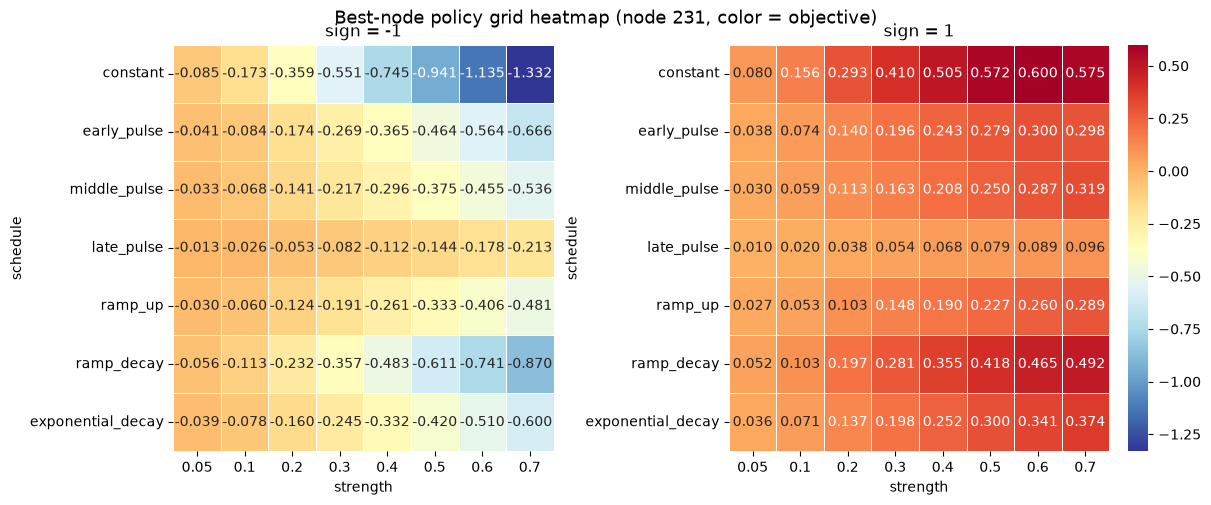

(<Figure size 1200x480 with 3 Axes>,
 array([<Axes: title={'center': 'sign = -1'}, xlabel='strength', ylabel='schedule'>,
        <Axes: title={'center': 'sign = 1'}, xlabel='strength', ylabel='schedule'>],
       dtype=object))

In [45]:
# best-node policy grid heatmap
# 先取最优节点
best_node = int(single_df.iloc[0]["node"])
best_grid = stage3_res["all_grid"][best_node]
plot_stage3_bestnode_policy_grid_heatmap(
    grid_df=best_grid,
    node=best_node,
    metric_col="objective",   # 想画 traj_recovery / fc_recovery改就行
    save_path="./results/stage3_bestnode_policy_grid_heatmap.png",
)

In [46]:
# Top-K candidate score table
topk_table = build_stage3_topk_candidate_score_table(
    single_df=single_df,
    top_k=10,
    include_roi_name=True,
    roi_name_col="roi_name",
    save_csv_path="./results/stage3_top10_candidate_score_table.csv",
)
# 加一个 Styler
topk_table.style.hide(axis="index").set_caption(
    "Top-K candidate intervention nodes"
)

node,roi_name,objective,traj_recovery,fc_recovery,strength,schedule
231,R_2,0.600000,0.440000,0.216000,0.600000,constant
51,L_2,0.551000,0.439000,0.150000,0.400000,constant
54,L_6mp,0.512000,0.328000,0.235000,0.200000,constant
233,R_6d,0.435000,0.330000,0.139000,0.300000,constant
219,R_24dd,0.374000,0.333000,0.056000,0.200000,constant
151,L_V6A,0.264000,0.187000,0.101000,0.200000,constant
226,R_7PC,0.234000,0.168000,0.100000,0.700000,ramp_up
188,R_3b,0.190000,0.142000,0.070000,0.400000,early_pulse
280,R_OP1,0.149000,0.085000,0.093000,0.500000,ramp_up
15,L_V7,0.125000,0.088000,0.051000,0.200000,constant


In [47]:
# 更正式一点
styled_topk = (
    topk_table.style
    .hide(axis="index")
    .set_caption("Top-K candidate intervention nodes")
    .format({
        "objective": "{:.3f}",
        "traj_recovery": "{:.3f}",
        "fc_recovery": "{:.3f}",
        "strength": "{:.3f}",
    })
)

styled_topk

node,roi_name,objective,traj_recovery,fc_recovery,strength,schedule
231,R_2,0.600,0.440,0.216,0.600,constant
51,L_2,0.551,0.439,0.150,0.400,constant
54,L_6mp,0.512,0.328,0.235,0.200,constant
233,R_6d,0.435,0.330,0.139,0.300,constant
219,R_24dd,0.374,0.333,0.056,0.200,constant
151,L_V6A,0.264,0.187,0.101,0.200,constant
226,R_7PC,0.234,0.168,0.100,0.700,ramp_up
188,R_3b,0.190,0.142,0.070,0.400,early_pulse
280,R_OP1,0.149,0.085,0.093,0.500,ramp_up
15,L_V7,0.125,0.088,0.051,0.200,constant


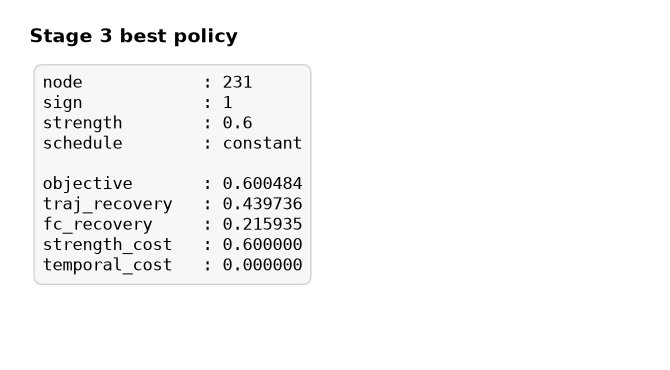

(<Figure size 680x380 with 1 Axes>, <Axes: >)

In [48]:
# best policy 参数展示
best_row = single_df.iloc[0]

plot_stage3_best_policy_card(
    best_row=best_row,
    title="Stage 3 best policy",
    save_path="./results/stage3_best_policy_card.png",
)

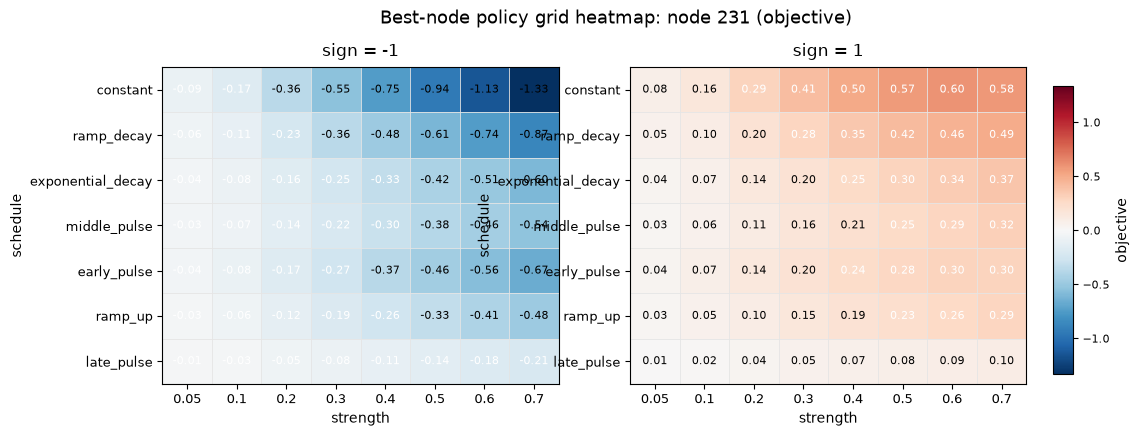

In [49]:
# 画 best node 的 grid heatmap
#objective heatmap
fig, axes = plot_stage3_best_node_grid_heatmap(
    grid_df=stage3_res["all_grid"][best_node],
    metric="objective",
    title=f"Best-node policy grid heatmap: node {best_node} (objective)",
    figsize=(10.8, 4.8),
    annotate=True,
    cmap=None,
    save_path="./results/stage3_best_node_grid_objective.png"
)

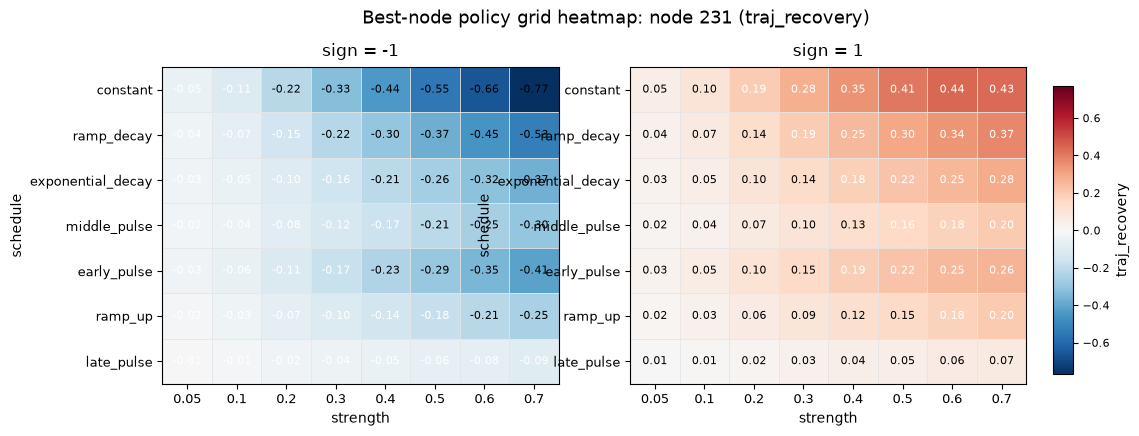

(<Figure size 1080x480 with 3 Axes>,
 array([<Axes: title={'center': 'sign = -1'}, xlabel='strength', ylabel='schedule'>,
        <Axes: title={'center': 'sign = 1'}, xlabel='strength', ylabel='schedule'>],
       dtype=object))

In [50]:
# traj_recovery heatmap
plot_stage3_best_node_grid_heatmap(
    grid_df=stage3_res["all_grid"][best_node],
    metric="traj_recovery",
    title=f"Best-node policy grid heatmap: node {best_node} (traj_recovery)",
    cmap=None,
    save_path="./results/stage3_best_node_grid_traj_recovery.png"
)

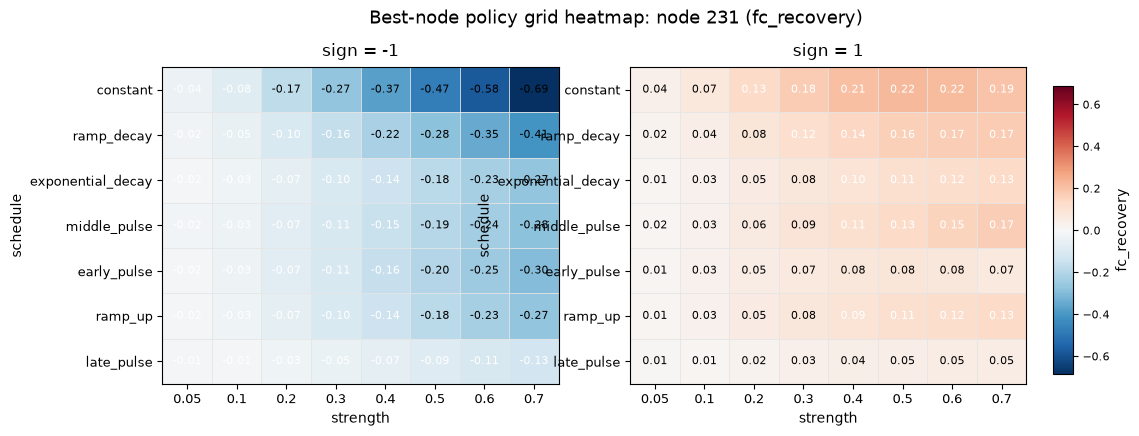

(<Figure size 1080x480 with 3 Axes>,
 array([<Axes: title={'center': 'sign = -1'}, xlabel='strength', ylabel='schedule'>,
        <Axes: title={'center': 'sign = 1'}, xlabel='strength', ylabel='schedule'>],
       dtype=object))

In [51]:
# fc_recovery heatmap
plot_stage3_best_node_grid_heatmap(
    grid_df=stage3_res["all_grid"][best_node],
    metric="fc_recovery",
    title=f"Best-node policy grid heatmap: node {best_node} (fc_recovery)",
    cmap=None,
    save_path="./results/stage3_best_node_grid_fc_recovery.png"
)

In [52]:
# 画 Top-K candidate score table
#先生成表
stage3_topk_table = make_stage3_topk_table(
    single_df=single_df,
    top_k=20,
    roi_names=roi_names if "roi_names" in globals() else None,
)

stage3_topk_table.head(20)

,rank,node,roi_label,sign,strength,schedule,objective,traj_recovery,fc_recovery,strength_cost,temporal_cost
0,1,231,R_2,1,0.6,constant,0.600484,0.439736,0.215935,0.6,0.000000
1,2,51,L_2,1,0.4,constant,0.550868,0.438571,0.150372,0.4,0.000000
2,3,54,L_6mp,1,0.2,constant,0.512276,0.328482,0.234742,0.2,0.000000
3,4,233,R_6d,1,0.3,constant,0.435360,0.330215,0.138931,0.3,0.000000
4,5,219,R_24dd,1,0.2,constant,0.374004,0.333245,0.055949,0.2,0.000000
5,6,151,L_V6A,1,0.2,constant,0.264071,0.187173,0.101123,0.2,0.000000
6,7,226,R_7PC,1,0.7,ramp_up,0.233655,0.167968,0.099609,0.7,0.052632
7,8,188,R_3b,1,0.4,early_pulse,0.189926,0.141643,0.070355,0.4,0.052632
8,9,280,R_OP1,1,0.5,ramp_up,0.149304,0.085092,0.092766,0.5,0.052632
9,10,15,L_V7,1,0.2,constant,0.124542,0.087841,0.050876,0.2,0.000000


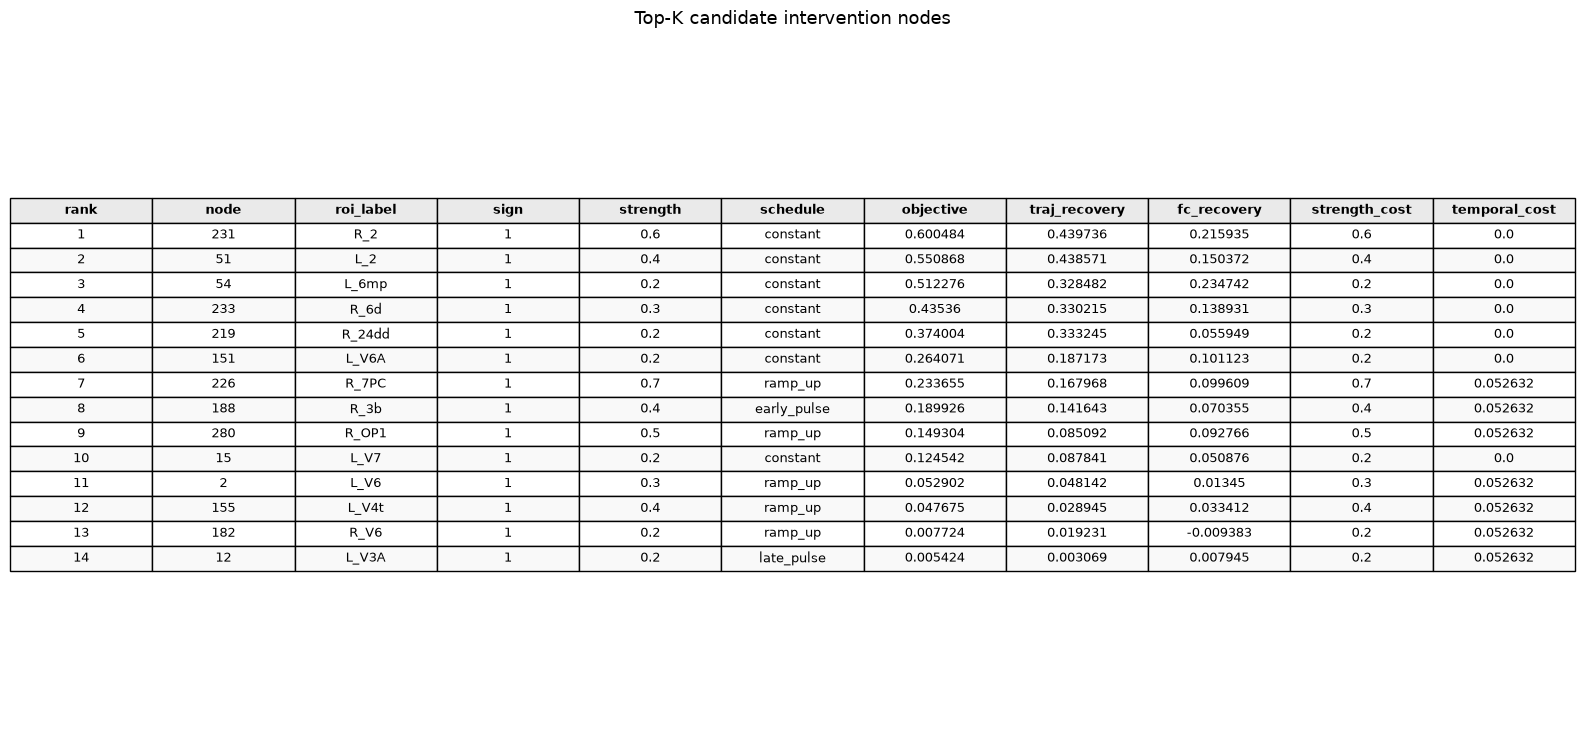

In [53]:
# 再画成表格
plot_stage3_topk_table(
    table_df=stage3_topk_table,
    title="Top-K candidate intervention nodes",
    save_path="./results/stage3_topk_candidate_table.png",
)
stage3_topk_table.to_csv(
    "./results/stage3_topk_candidate_table.csv",
    index=False,
    encoding="utf-8-sig"
)

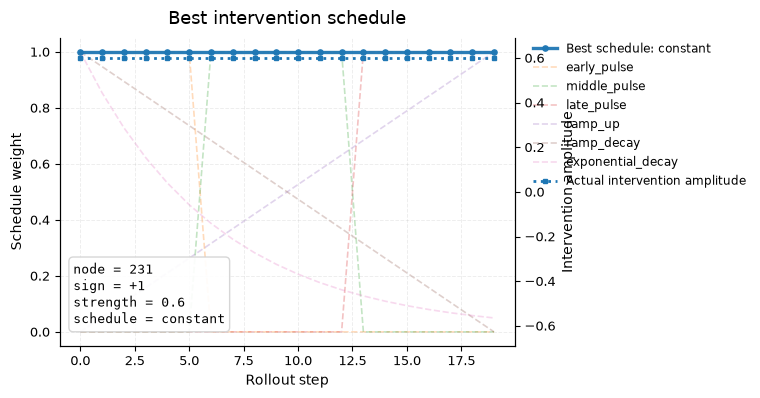

(<Figure size 740x440 with 2 Axes>,
 <Axes: title={'center': 'Best intervention schedule'}, xlabel='Rollout step', ylabel='Schedule weight'>,
 <Axes: ylabel='Intervention amplitude'>)

In [54]:
# 最优干预策略在 rollout 过程中的时序权重。
plot_stage3_best_policy_schedule(
    best_row=best_row,
    horizon=ROLLOUT_HORIZON,
    schedules=("constant","early_pulse","middle_pulse","late_pulse","ramp_up","ramp_decay","exponential_decay"),
    show_all_schedules=True,   # 只想画最优 schedule就改成False
    save_path="./results/stage3_best_policy_schedule.png",
)

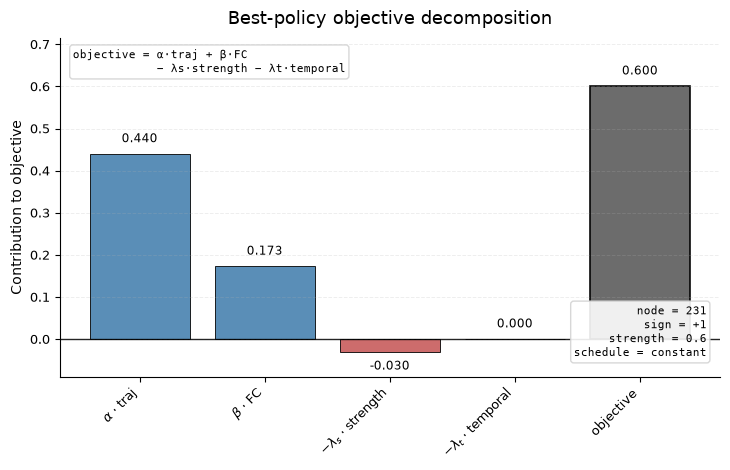

(<Figure size 740x480 with 1 Axes>,
 <Axes: title={'center': 'Best-policy objective decomposition'}, ylabel='Contribution to objective'>)

In [55]:
# best policy 的 objective 分解图
plot_stage3_objective_decomposition(
    best_row=best_row,
    alpha_traj=1.0,
    beta_fc=0.8,
    lambda_strength=0.05,
    lambda_temporal=0.03,
    title="Best-policy objective decomposition",
    save_path="./results/stage3_objective_decomposition.png"
)

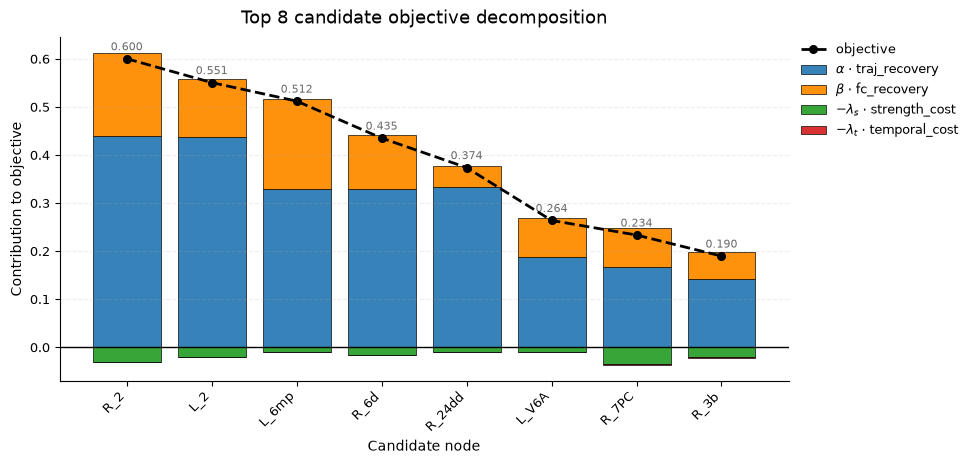

(<Figure size 1080x520 with 1 Axes>,
 <Axes: title={'center': 'Top 8 candidate objective decomposition'}, xlabel='Candidate node', ylabel='Contribution to objective'>,
    node roi_name  sign  strength     schedule  objective  traj_recovery  \
 0   231      R_2     1       0.6     constant   0.600484       0.439736   
 1    51      L_2     1       0.4     constant   0.550868       0.438571   
 2    54    L_6mp     1       0.2     constant   0.512276       0.328482   
 3   233     R_6d     1       0.3     constant   0.435360       0.330215   
 4   219   R_24dd     1       0.2     constant   0.374004       0.333245   
 5   151    L_V6A     1       0.2     constant   0.264071       0.187173   
 6   226    R_7PC     1       0.7      ramp_up   0.233655       0.167968   
 7   188     R_3b     1       0.4  early_pulse   0.189926       0.141643   
 
    fc_recovery  D_lesion_traj  D_policy_traj  ...  node_cost  strength_cost  \
 0     0.215935       0.684629       0.383573  ...        1.0     

In [56]:
# Top-K candidate objective decomposition 对比图
plot_stage3_topk_objective_decomposition(
    single_df=single_df,
    top_k=8,
    alpha_traj=1.0,
    beta_fc=0.8,
    lambda_strength=0.05,
    lambda_temporal=0.03,
    label_col="roi_name",
    x_rotation=45,
    legend_outside=True,
    title="Top 8 candidate objective decomposition",
    save_path="./results/stage3_top8_objective_decomposition_roi_name.png",
)

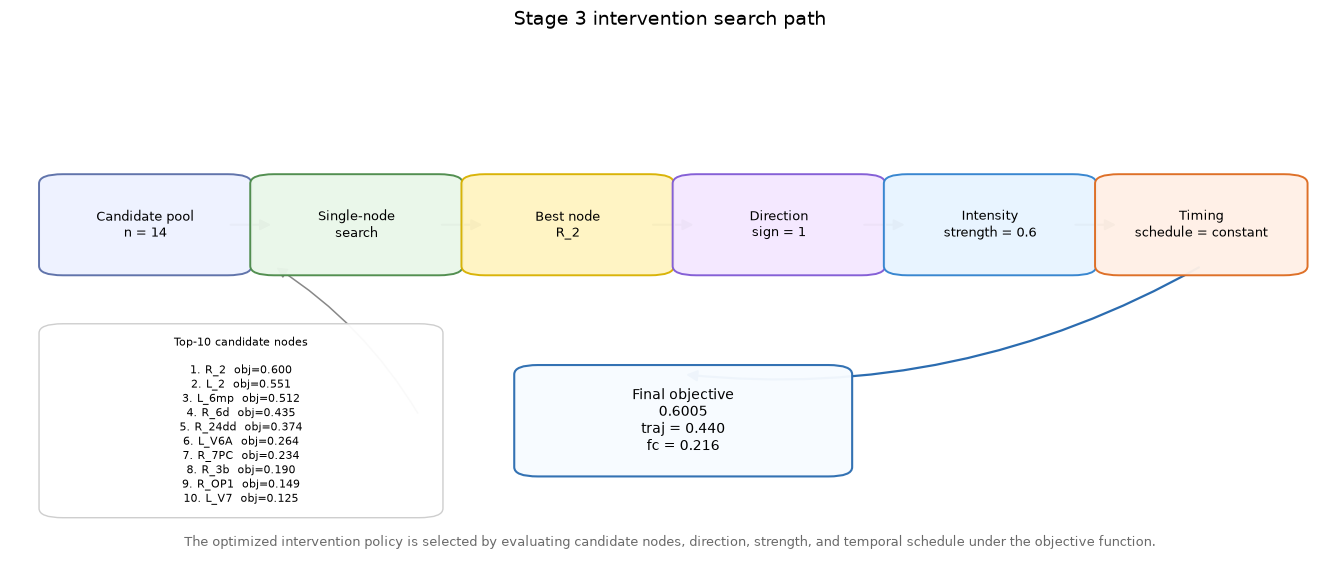

{'n_candidates': 14, 'best_node': 231, 'best_node_label': 'R_2', 'best_sign': np.int64(1), 'best_strength': np.float64(0.6), 'best_schedule': 'constant', 'best_objective': 0.6004837386074344}


In [57]:
# 干预策略搜索路径
fig, ax, search_path_summary = plot_stage3_intervention_search_path_graph(
    stage3_res=stage3_res,
    roi_names=roi_names if "roi_names" in globals() else None,
    top_k_show=10,
    figsize=(13.5, 5.8),
    title="Stage 3 intervention search path",
    save_path="./results/stage3_intervention_search_path.png",
)

print(search_path_summary)

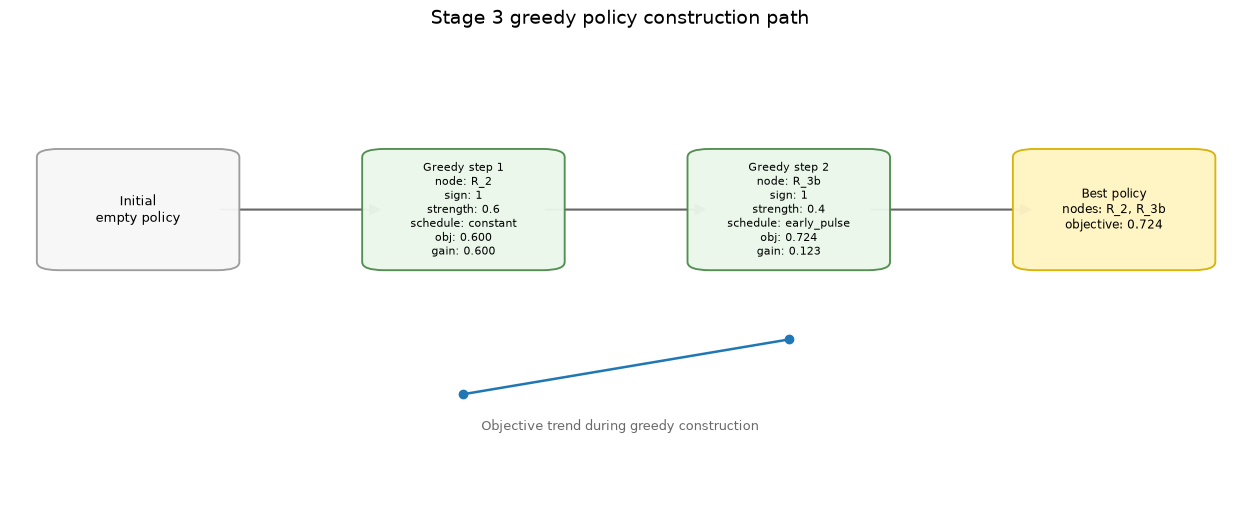

{'n_steps': 2, 'final_nodes': 'R_2, R_3b', 'final_objective': 0.7235566930185251}


In [58]:
# 贪心搜索过程
fig, ax, greedy_summary = plot_stage3_greedy_policy_construction_path(
    greedy_history=stage3_res["greedy_history"],
    roi_names=roi_names if "roi_names" in globals() else None,
    figsize=(12.5, 5.2),
    title="Stage 3 greedy policy construction path",
    save_path="./results/stage3_greedy_policy_construction_path.png",
)

print(greedy_summary)

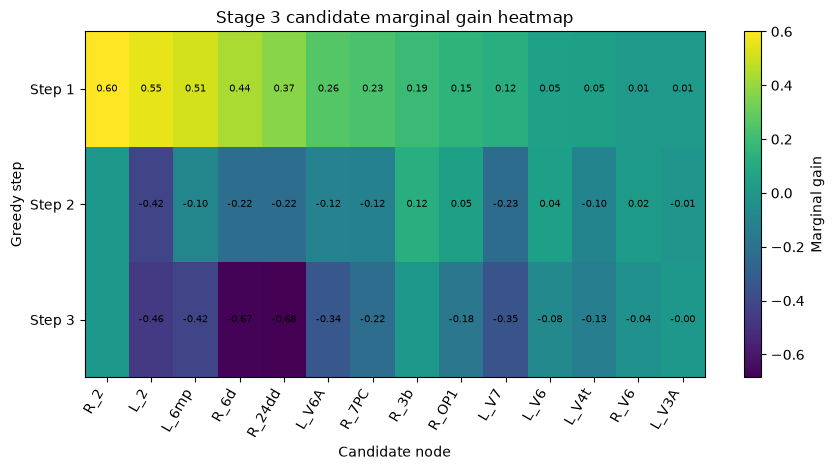

node_label       R_2       L_2     L_6mp      R_6d    R_24dd     L_V6A  \
step                                                                     
1           0.600484  0.550868  0.512276  0.435360  0.374004  0.264071   
2           0.000000 -0.417396 -0.095144 -0.220272 -0.218599 -0.116105   
3           0.000000 -0.464547 -0.418232 -0.670750 -0.684777 -0.335555   

node_label     R_7PC      R_3b     R_OP1      L_V7      L_V6     L_V4t  \
step                                                                     
1           0.233655  0.189926  0.149304  0.124542  0.052902  0.047675   
2          -0.121453  0.123073  0.045832 -0.228208  0.039574 -0.103506   
3          -0.223802  0.000000 -0.175683 -0.348509 -0.079468 -0.134242   

node_label      R_V6     L_V3A  
step                            
1           0.007724  0.005424  
2           0.017677 -0.013975  
3          -0.035969 -0.001059  


In [59]:
# 搜索过程依据
fig3, ax3, heatmap_info = plot_stage3_candidate_marginal_gain_map(
    greedy_trial_df=stage3_res["greedy_trial_df"],
    roi_names=roi_names if "roi_names" in globals() else None,
    mode="heatmap",   # 也可换ranking版
    top_show_nodes=18,
    title_prefix="Stage 3 candidate marginal gain",
    save_path="./results/stage3_candidate_marginal_gain_heatmap.png",
)

print(heatmap_info["heatmap_df"])

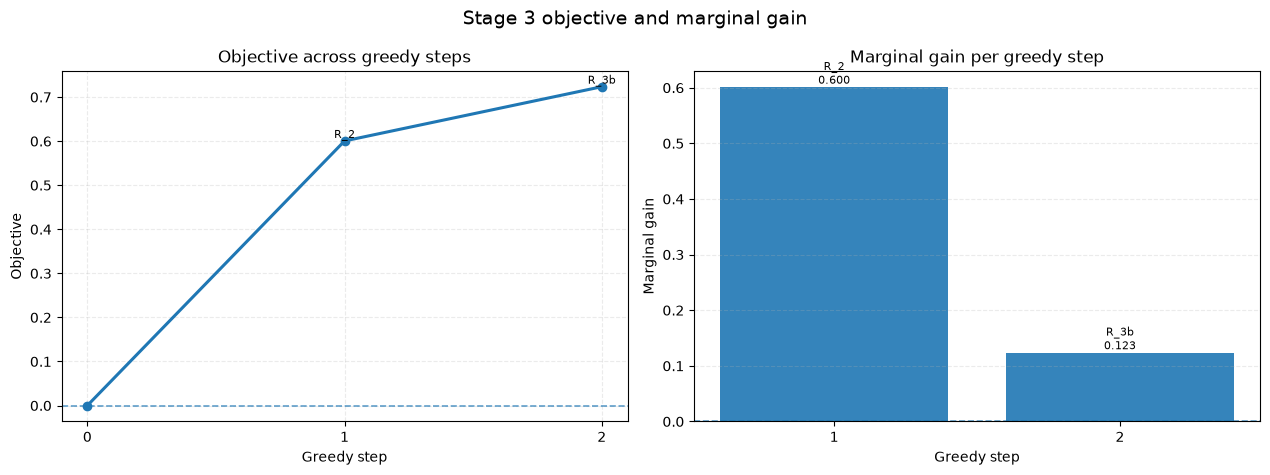

{'n_steps': 2, 'final_objective': 0.7235566930185251, 'total_gain': 0.7235566930185251, 'selected_nodes': ['R_2', 'R_3b']}


In [60]:
# 核心定量图
fig1, axes1, combo_summary = plot_stage3_objective_marginal_gain_combo(
    greedy_history=stage3_res["greedy_history"],
    roi_names=roi_names if "roi_names" in globals() else None,
    baseline_objective=0.0,
    title="Stage 3 objective and marginal gain",
    save_path="./results/stage3_objective_marginal_gain_combo.png",
)

print(combo_summary)

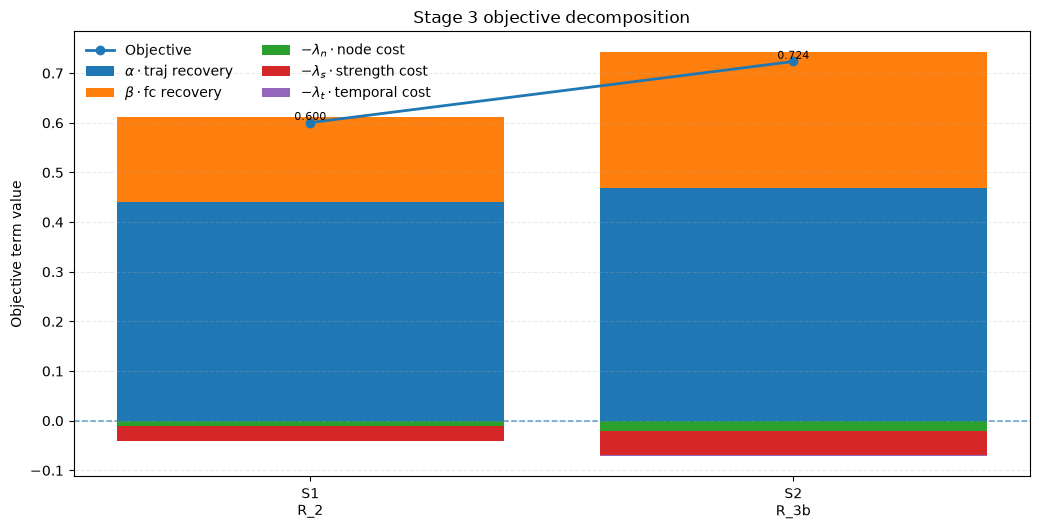

   step node_label  traj_term   fc_term  node_term  strength_term  \
0     1        R_2   0.439736  0.172748      -0.01          -0.03   
1     2       R_3b   0.469300  0.274256      -0.02          -0.05   

   temporal_term  objective  
0      -0.000000   0.600484  
1      -0.001579   0.723557  


In [61]:
# objective分解过程
fig2, ax2, decomp_df = plot_stage3_objective_decomposition_stackedbar(
    greedy_history=stage3_res["greedy_history"],
    roi_names=roi_names if "roi_names" in globals() else None,
    alpha_traj=1.0,
    beta_fc=0.8,
    lambda_node=0.01,
    lambda_strength=0.05,
    lambda_temporal=0.03,
    title="Stage 3 objective decomposition",
    save_path="./results/stage3_objective_decomposition_stackedbar.png",
)

print(decomp_df)

Recovery evaluation

In [62]:
# =========================================================
# Stage 4: use final policy from Stage 3
# =========================================================
best_policy = stage3_res["best_policy"]
best_node = int(best_policy[0]["node"])   # primary policy node, usually greedy step 1

if "best_policy_traj" in stage3_res and stage3_res["best_policy_traj"] is not None:
    best_policy_traj = stage3_res["best_policy_traj"]
elif "best_multi_policy_traj" in stage3_res and stage3_res["best_multi_policy_traj"] is not None:
    best_policy_traj = stage3_res["best_multi_policy_traj"]
else:
    # fallback: only for old single-node pipeline
    best_single_node = int(stage3_res["single_df"].iloc[0]["node"])
    best_policy_traj = stage3_res["best_details"][best_single_node]["policy_traj"]

print("Stage 4 uses final policy:")
print(best_policy)
print("Primary policy node:", best_node)

stage4_res = summarize_recovery(
    healthy_traj=stage1_res["healthy_traj"],
    lesion_traj=stage1_res["lesion_traj"],
    policy_traj=stage3_res["best_policy_traj"],
    policy=stage3_res["best_policy"],
    roi_names=roi_names,

    alpha_traj=BEST_CONFIG["alpha_traj"],
    beta_fc=BEST_CONFIG["beta_fc"],
    lambda_node=BEST_CONFIG["lambda_node"],
    lambda_strength=BEST_CONFIG["lambda_strength"],
    lambda_temporal=BEST_CONFIG["lambda_temporal"],
    distance_metric="rmse",
)

print(stage4_res["metrics"])
print(stage4_res["time_recovery_df"].head())
print(stage4_res["roi_recovery_df"].head())
print(stage4_res["distance_df"].head())

Stage 4 uses final policy:
[{'node': 231, 'sign': 1, 'strength': 0.6, 'schedule': 'constant', 'schedule_vector': array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1.])}, {'node': 188, 'sign': 1, 'strength': 0.4, 'schedule': 'early_pulse', 'schedule_vector': array([1., 1., 1., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0.])}]
Primary policy node: 231
{'objective': 0.7235566930185251, 'traj_recovery': 0.4693003427588308, 'D_lesion_traj': 0.6846287346611792, 'D_policy_traj': 0.36333223482267385, 'fc_recovery': 0.3428204378246178, 'D_lesion_fc': 1.393389386478247, 'D_policy_fc': 0.915707026946256, 'FC_healthy': array([[1.        , 0.36357236, 0.8032566 , ..., 0.93659003, 0.95451683,
        0.94570536],
       [0.36357236, 1.        , 0.7702791 , ..., 0.34158349, 0.2982982 ,
        0.39039108],
       [0.8032566 , 0.7702791 , 1.        , ..., 0.73146145, 0.7214112 ,
        0.76861985],
       ...,
       [0.93659003, 0.3

In [63]:
print("Stage 3 final greedy step:")
if "greedy_history" in stage3_res and len(stage3_res["greedy_history"]) > 0:
    print(stage3_res["greedy_history"].tail(1)[[
        "step", "selected_node", "sign", "strength", "schedule",
        "objective", "marginal_gain", "traj_recovery", "fc_recovery",
        "strength_cost", "temporal_cost"
    ]])
else:
    print(stage3_res["single_df"].head(1)[[
        "node", "sign", "strength", "schedule",
        "objective", "traj_recovery", "fc_recovery",
        "strength_cost", "temporal_cost"
    ]])

print("\nStage 4 metrics:")
print({
    "objective": stage4_res["metrics"]["objective"],
    "traj_recovery": stage4_res["metrics"]["traj_recovery"],
    "fc_recovery": stage4_res["metrics"]["fc_recovery"],
    "node_cost": stage4_res["metrics"].get("node_cost", None),
    "strength_cost": stage4_res["metrics"]["strength_cost"],
    "temporal_cost": stage4_res["metrics"]["temporal_cost"],
})

Stage 3 final greedy step:
   step  selected_node  sign  strength     schedule  objective  marginal_gain  \
1     2            188     1       0.4  early_pulse   0.723557       0.123073   

   traj_recovery  fc_recovery  strength_cost  temporal_cost  
1         0.4693      0.34282            1.0       0.052632  

Stage 4 metrics:
{'objective': 0.7235566930185251, 'traj_recovery': 0.4693003427588308, 'fc_recovery': 0.3428204378246178, 'node_cost': 2.0, 'strength_cost': 1.0, 'temporal_cost': 0.05263157894736842}


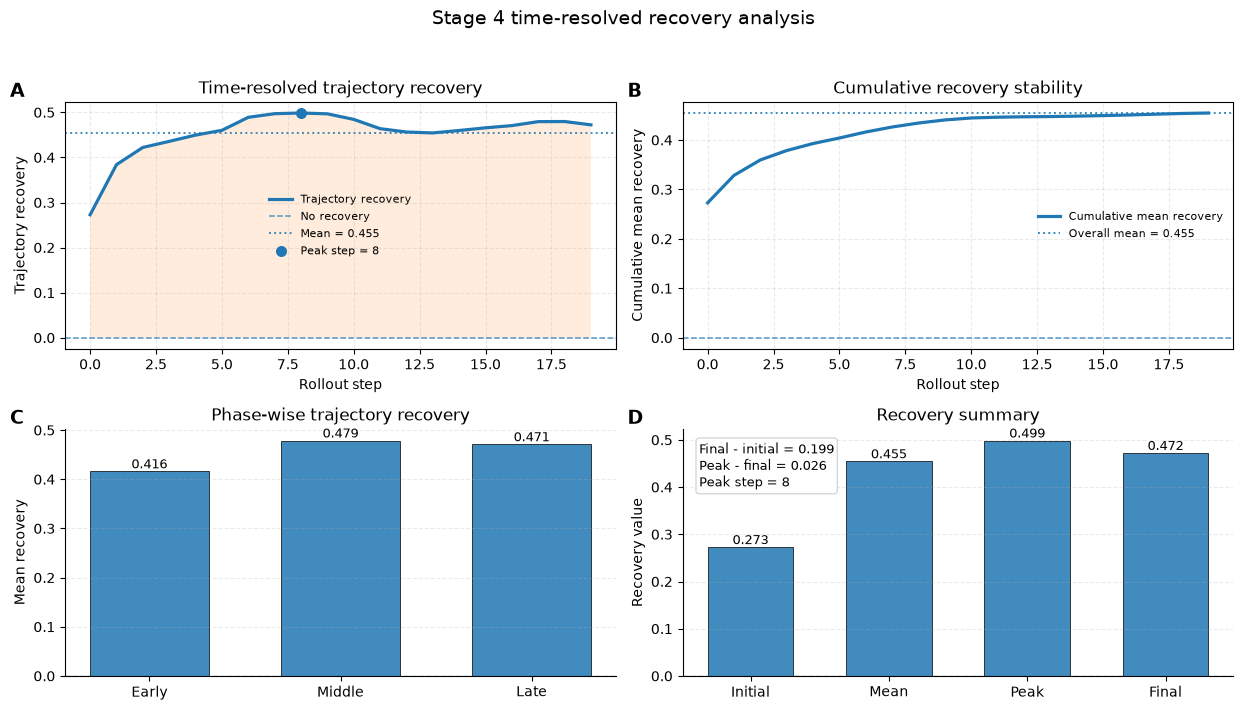

    phase  mean_recovery
0   Early       0.416194
1  Middle       0.478782
2    Late       0.471255
    metric     value
0  Initial  0.272848
1     Mean  0.454618
2     Peak  0.498569
3    Final  0.472297


{'initial_recovery': 0.2728475588499495,
 'mean_recovery': 0.45461793313074866,
 'peak_recovery': 0.498569422290867,
 'peak_step': 8,
 'final_recovery': 0.4722970914753716,
 'final_minus_initial': 0.1994495326254221,
 'peak_minus_final': 0.026272330815495404}

In [64]:
# 可视化
time_recovery_panel = plot_time_recovery(
    stage4_res["time_recovery_df"],
    figsize=(12.5, 7.2),
    save_path="./results/stage4_time_resolved_recovery_combo.png",
)

print(time_recovery_panel["phase_df"])
print(time_recovery_panel["summary_df"])
time_recovery_panel["diagnostics"]

(<Figure size 1500x450 with 3 Axes>,
 array([<Axes: title={'center': 'Healthy FC'}>,
        <Axes: title={'center': 'Lesion FC'}>,
        <Axes: title={'center': 'Policy FC'}>], dtype=object))

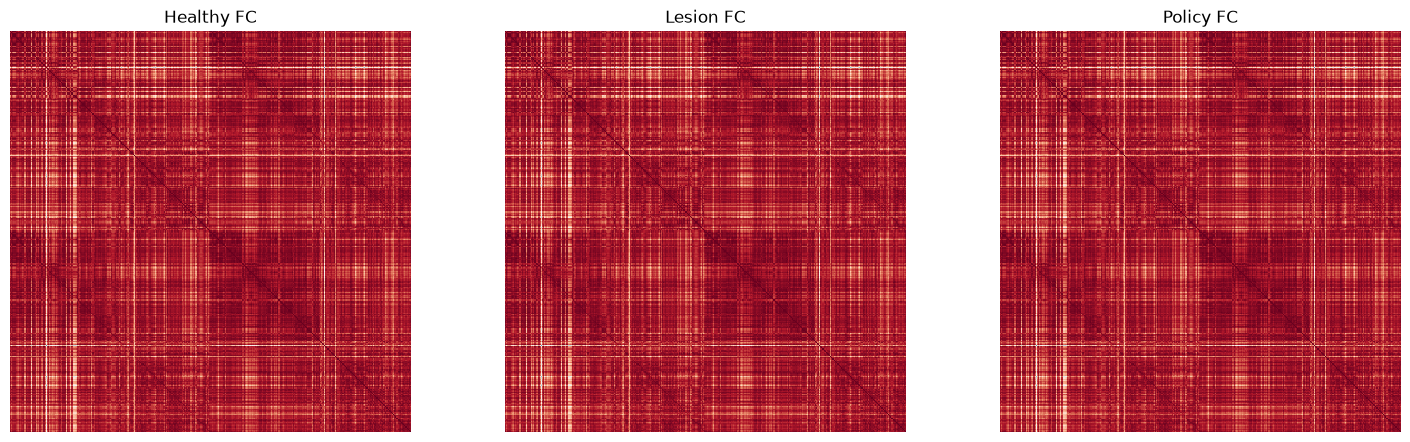

In [65]:
plot_fc_triplet(
    stage4_res["metrics"]["FC_healthy"],
    stage4_res["metrics"]["FC_lesion"],
    stage4_res["metrics"]["FC_policy"],
    neworder=neworder,
)

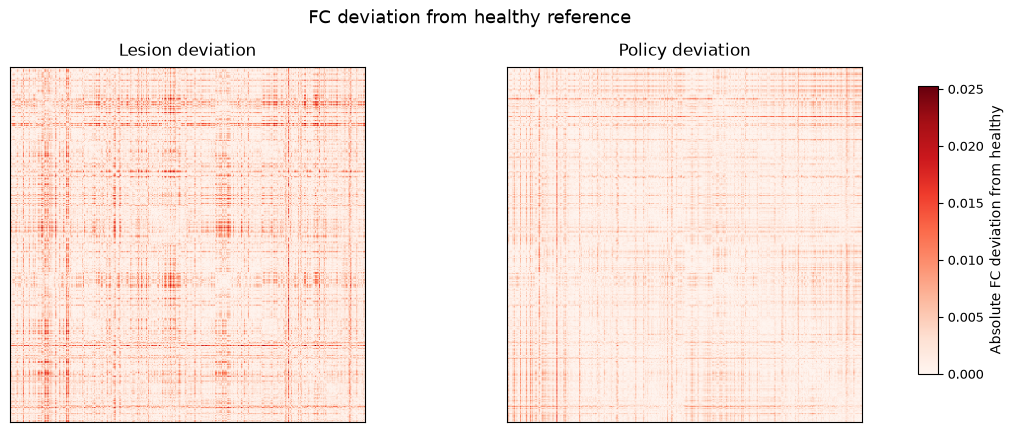

In [66]:
# FC差异图
fig, axes, fc_diff_info = plot_stage4_fc_difference_maps(
    stage4_res["metrics"]["FC_healthy"],
    stage4_res["metrics"]["FC_lesion"],
    stage4_res["metrics"]["FC_policy"],
    neworder=neworder if "neworder" in globals() else None,
    save_path="./results/stage4_fc_difference_maps.png",
)

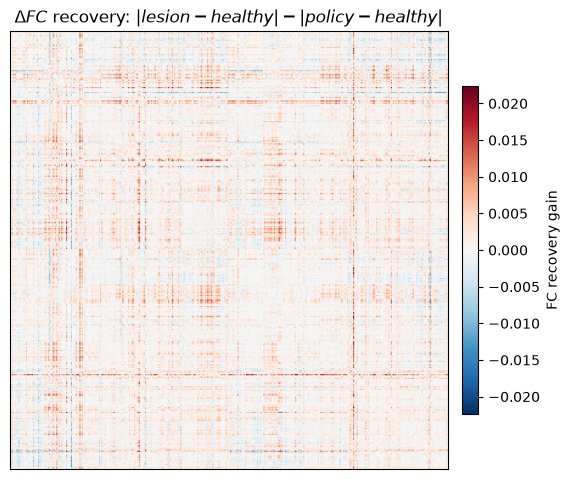

In [67]:
# FC recovery map
fig, ax, fc_delta_info = plot_stage4_fc_recovery_delta_map(
    stage4_res["metrics"]["FC_healthy"],
    stage4_res["metrics"]["FC_lesion"],
    stage4_res["metrics"]["FC_policy"],
    neworder=neworder if "neworder" in globals() else None,
    save_path="./results/stage4_fc_recovery_delta_map.png",
)

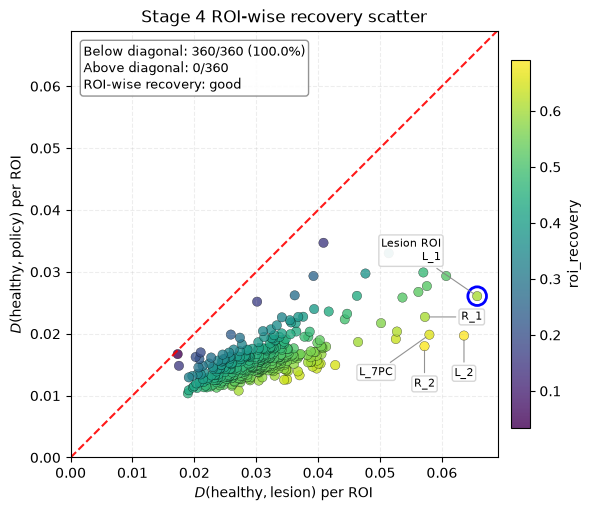

{'n_total': 360, 'n_below_diagonal': 360, 'n_above_diagonal': 0, 'fraction_below_diagonal': 1.0, 'judgement': 'good'}


In [68]:
# Recovery scatter 图
fig, ax, scatter_summary = plot_stage4_recovery_scatter(
    roi_recovery_df=stage4_res["roi_recovery_df"],
    roi_names=roi_names if "roi_names" in globals() else None,
    lesion_idx=lesion_idx,
    top_k_label=5,
    color_by="roi_recovery",   # 也可以改成 "improvement"
    save_path="./results/stage4_recovery_scatter.png",
)
#挤的话调draw_scatter_callout_labels函数的offset_frac=(0.090, 0.080)
print(scatter_summary)

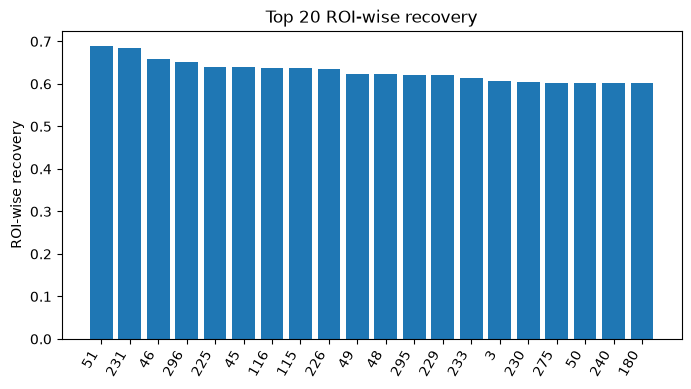

In [69]:
ax=plot_top_roi_recovery(stage4_res["roi_recovery_df"], top_k=20)
plt.show()

<Axes: title={'center': 'Three-trajectory distance over time'}, xlabel='Rollout step', ylabel='Distance to healthy trajectory'>

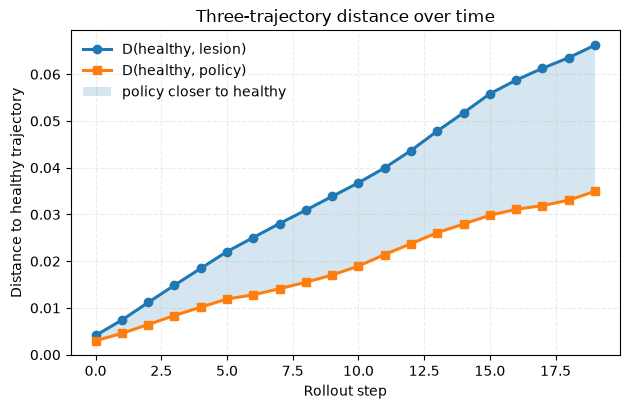

In [70]:
plot_three_trajectory_distance(stage4_res["distance_df"])

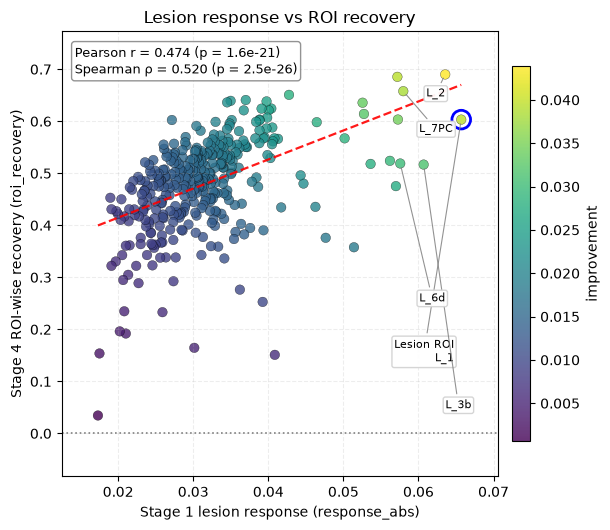

{'n_roi': 360, 'pearson_r': 0.47366878064673035, 'pearson_p': 1.5635385989966482e-21, 'spearman_rho': 0.5199968106749794, 'spearman_p': 2.500547448447364e-26, 'slope': 5.584333571912886, 'intercept': 0.30312086393744436}


,roi,response_abs,roi_name,roi_recovery,improvement,D_lesion_roi,D_policy_roi,_label_name
0,50,0.065697,L_1,0.603155,0.039626,0.065697,0.026072,L_1
1,51,0.063563,L_2,0.690067,0.043863,0.063563,0.019700,L_2
2,8,0.060690,L_3b,0.516725,0.031360,0.060690,0.029330,L_3b
3,46,0.057976,L_7PC,0.657808,0.038137,0.057976,0.019839,L_7PC
4,53,0.057571,L_6d,0.518853,0.029871,0.057571,0.027700,L_6d


In [71]:
# lesion_response_vs_recovery_scatter,是一个 Stage 1 ↔ Stage 4 的桥接图
fig, ax, response_recovery_df, response_recovery_summary = plot_lesion_response_vs_recovery_scatter(
        lesion_response_df=stage1_res["lesion_response_df"],
        roi_recovery_df=stage4_res["roi_recovery_df"],
        roi_names=roi_names if "roi_names" in globals() else None,
        lesion_idx=lesion_idx,
        response_col="response_abs",
        recovery_col="roi_recovery",
        label_top_k=5,
        color_by="improvement",   # 也可以换成 "roi_recovery" 或 None
        save_path="./results/stage4_lesion_response_vs_recovery_scatter.png",
    )

print(response_recovery_summary)
response_recovery_df.head()

In [72]:
# ROI recovery Top-K 表
roi_recovery_topk_table = make_stage4_roi_recovery_topk_table(
    lesion_response_df=stage1_res["lesion_response_df"],
    roi_recovery_df=stage4_res["roi_recovery_df"],
    top_k=20,
    roi_names=roi_names if "roi_names" in globals() else None,
    sort_by="roi_recovery",      # 也可以改成 "improvement"：roi_recovery 是相对恢复比例,improvement 是绝对下降量
    response_col="response_abs",
    save_csv_path="./results/stage4_roi_recovery_top20_table.csv",
)

roi_recovery_topk_table

,rank,roi,ROI,Stage1_response_abs,D_lesion_roi,D_policy_roi,roi_recovery,improvement
0,1,51,L_2,0.063563,0.063563,0.019700,0.690067,0.043863
1,2,231,R_2,0.057187,0.057187,0.017991,0.685409,0.039196
2,3,46,L_7PC,0.057976,0.057976,0.019839,0.657808,0.038137
3,4,296,R_AIP,0.042756,0.042756,0.014931,0.650789,0.027825
4,5,225,R_7PL,0.036992,0.036992,0.013285,0.640868,0.023707
5,6,45,L_7PL,0.034980,0.034980,0.012617,0.639300,0.022363
6,7,116,L_AIP,0.039765,0.039765,0.014385,0.638246,0.025380
7,8,115,L_PFt,0.034508,0.034508,0.012549,0.636354,0.021960
8,9,226,R_7PC,0.052555,0.052555,0.019148,0.635658,0.033407
9,10,49,L_MIP,0.040395,0.040395,0.015169,0.624472,0.025226


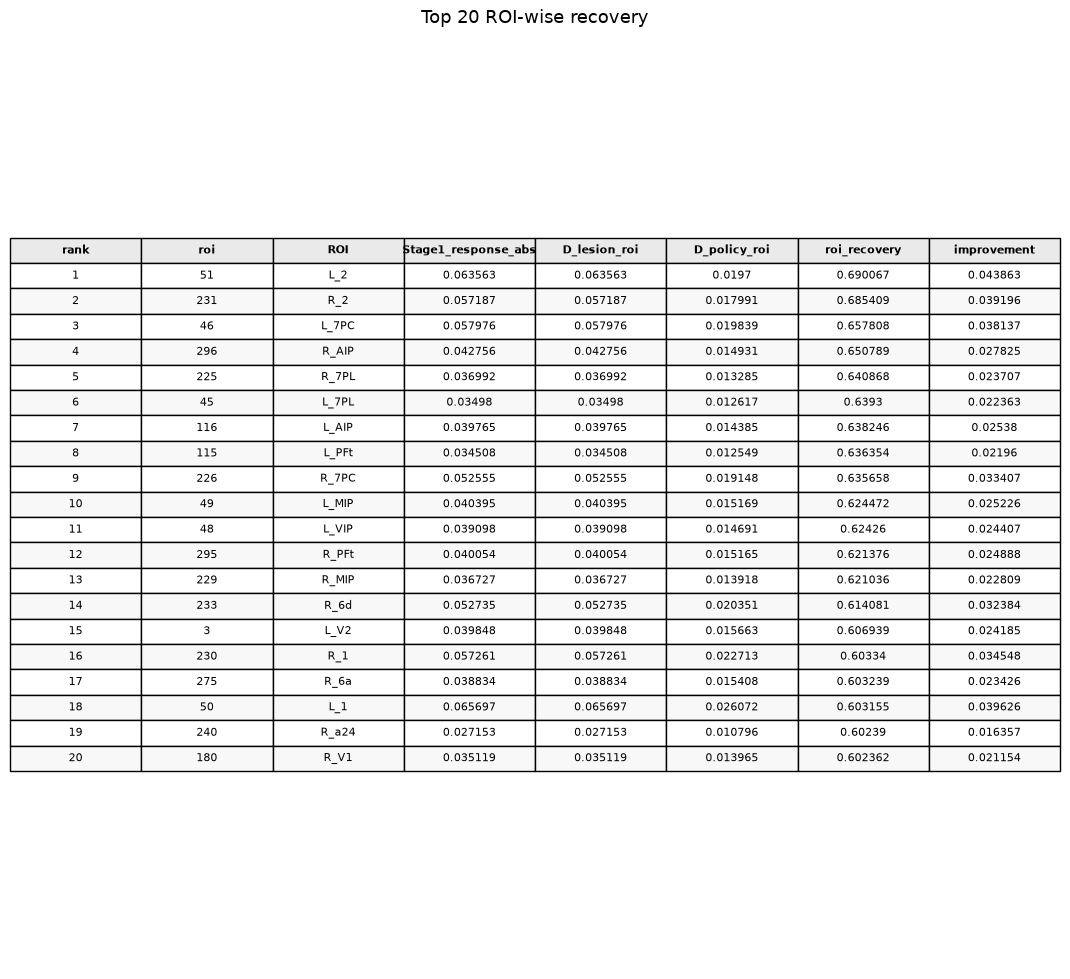

(<Figure size 1080x990 with 1 Axes>,
 <Axes: title={'center': 'Top 20 ROI-wise recovery'}>)

In [73]:
# 表格图
plot_stage4_roi_recovery_topk_table(
    table_df=roi_recovery_topk_table,
    title="Top 20 ROI-wise recovery",
    save_path="./results/stage4_roi_recovery_top20_table.png",
)

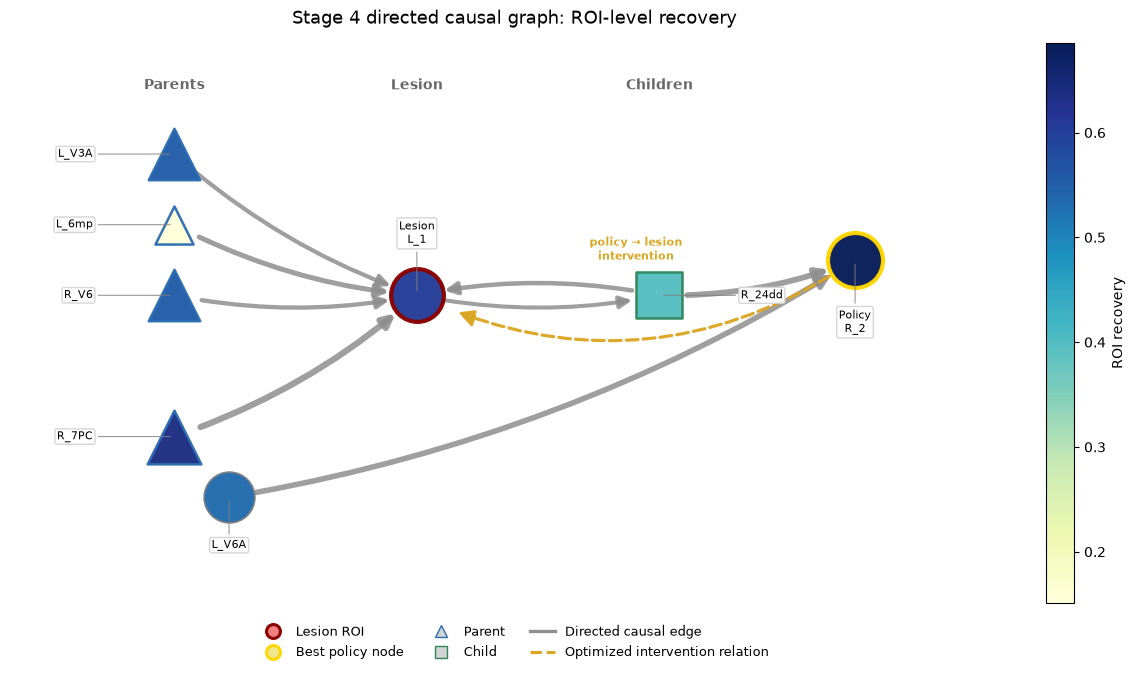

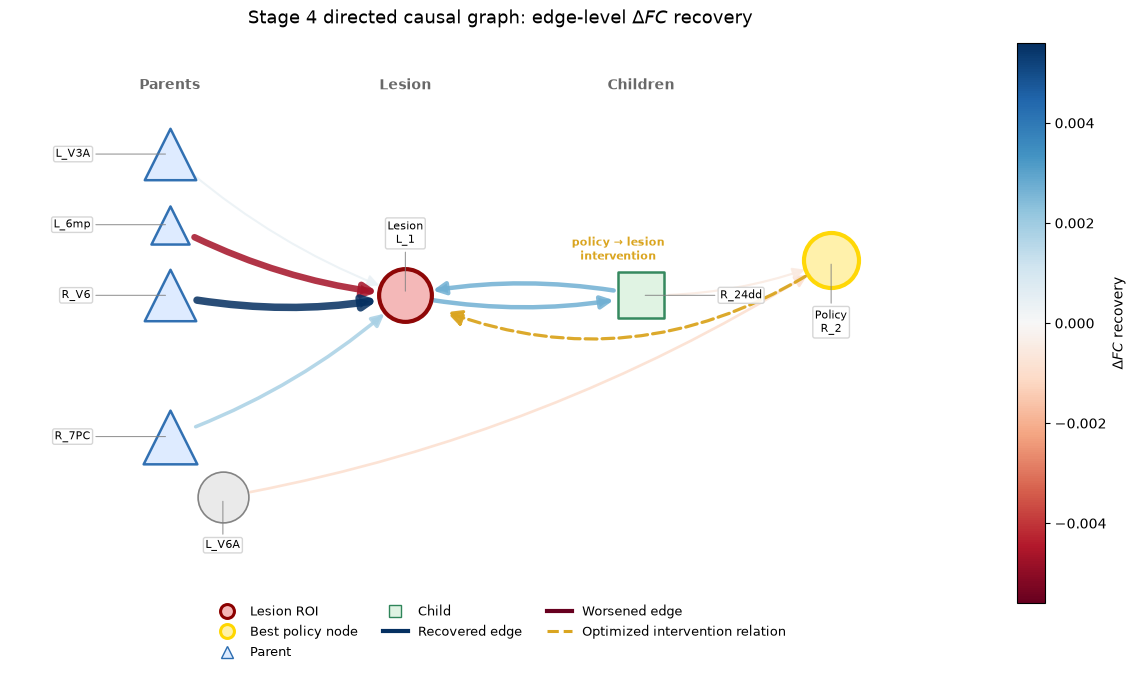

{'best_policy_node': 231, 'lesion_idx': 50, 'has_direct_policy_to_lesion': False, 'has_direct_lesion_to_policy': False, 'has_path_policy_to_lesion': False, 'has_path_lesion_to_policy': True, 'has_undirected_path': True, 'shortest_path_policy_to_lesion': None, 'shortest_path_lesion_to_policy': [50, 219, 231], 'shortest_path_undirected': [231, 219, 50]}
   src  dst  src_local  dst_local  tau link       val   abs_val  \
0  226   50         11          0    1  <-> -0.306664  0.306664   
1   54   50         35          0    1  <->  0.225744  0.225744   
2  219   50         20          0    1  <->  0.192261  0.192261   
3  182   50         36          0    1  <->  0.179388  0.179388   
4   12   50         40          0    1  <-> -0.173391  0.173391   
5   50  219          0         20    1  <->  0.163392  0.163392   
6  219  231         20          4    1  <->  0.276662  0.276662   
7  151  231         41          4    1  <->  0.261312  0.261312   

               p    fc_abs  ...  direct_le

In [74]:
fig_node, ax_node, fig_edge, ax_edge, causal_graph_info = plot_stage4_directed_causal_intervention_graph_split(
        core_edge_df=lesion_core_edges,
        stage4_metrics=stage4_res["metrics"],
        lesion_idx=lesion_idx,
        best_policy=best_policy,
        roi_recovery_df=stage4_res["roi_recovery_df"],
        stage1_response_df=stage1_res["lesion_response_df"],
        roi_names=roi_names if "roi_names" in globals() else None,
        top_k_edges=8,
        mode="lesion_neighborhood",
        show_policy_to_lesion_link=True,
        save_prefix="./results/stage4_directed_causal_graph",
    )

print(causal_graph_info["path_info"])
print(causal_graph_info["focus_edges"].head(20))
print(causal_graph_info["node_df"].head())

In [75]:
best_policy = stage3_res["best_policy"]
best_node = int(best_policy[0]["node"])

print("best_node =", best_node)
print("lesion_idx =", lesion_idx)
print("best_policy =", best_policy)

path_check = extract_policy_lesion_paths(
    lesion_core_edges=lesion_core_edges,   # 注意：用完整 lesion_core_edges，不是 direct_lesion_edges
    lesion_idx=lesion_idx,
    best_policy=best_policy,
    direction="auto",
    max_hops=5,
    top_k_paths=5,
    score_col="abs_val",
    score_mode="mean",
    path_mode="topk_union",
    allow_undirected_fallback=True,
)

print("has_path:", path_check["has_path"])
print("direction_used:", path_check["direction_used"])
print("search_type:", path_check["search_type"])
print("selected_paths:", path_check["selected_paths"])
print("selected_path_scores:", path_check["selected_path_scores"])

best_node = 231
lesion_idx = 50
best_policy = [{'node': 231, 'sign': 1, 'strength': 0.6, 'schedule': 'constant', 'schedule_vector': array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1.])}, {'node': 188, 'sign': 1, 'strength': 0.4, 'schedule': 'early_pulse', 'schedule_vector': array([1., 1., 1., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0.])}]
has_path: True
direction_used: lesion_to_policy
search_type: directed
selected_paths: [[50, 219, 231]]
selected_path_scores: [0.2200268664324525]


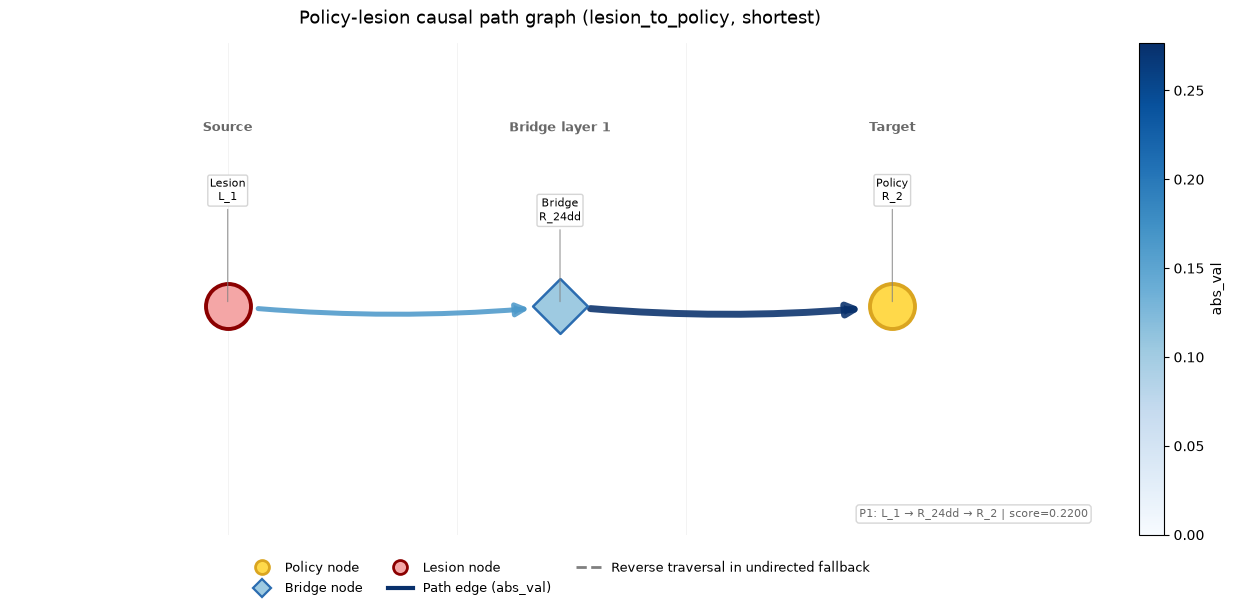

[[50, 219, 231]]
   src  dst path_id  path_step  causal_src  causal_dst  is_reverse_traversal  \
0   50  219     [1]          1          50         219                 False   
1  219  231     [1]          2         219         231                 False   

   src_local  dst_local  tau  ...   abs_val             p    fc_abs  \
0          0         20    1  ...  0.163392  2.401057e-29  0.514435   
1         20          4    1  ...  0.276662  6.370153e-83  0.485815   

   causal_norm   fc_norm  fused_score  direct_lesion_edge  \
0     0.324122  0.631404     0.385578                True   
1     0.624423  0.596108     0.618760               False   

   strong_significant_edge  _path_score_for_sort  path_count  
0                     True              0.163392           1  
1                     True              0.276662           1  

[2 rows x 22 columns]


In [76]:
# 画 shortest path 版本
fig_union, ax_union, path_info_short = plot_stage4_policy_lesion_path_graph(
    lesion_core_edges=lesion_core_edges,
    lesion_idx=lesion_idx,
    best_policy=best_policy,
    roi_names=roi_names if "roi_names" in globals() else None,

    direction="auto",
    max_hops=5,
    top_k_paths=1,
    path_mode="shortest",

    score_col="abs_val",
    score_mode="mean",
    allow_undirected_fallback=True,

    figsize=(12.5, 6.2),
    show_path_summary=True,
    save_path="./results/stage4_policy_lesion_shortest_path_graph.png",
)

print(path_info_short["path_res"]["selected_paths"])
print(path_info_short["path_edge_df"])

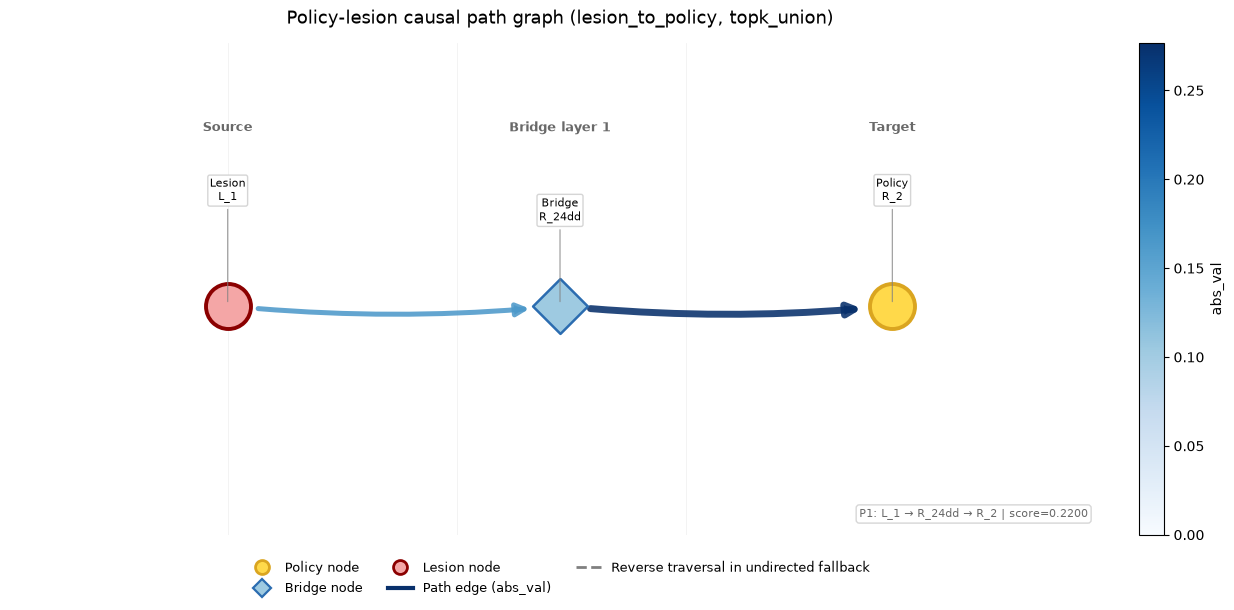

[[50, 219, 231]]
[0.2200268664324525]
   src  dst path_id  path_step  causal_src  causal_dst  is_reverse_traversal  \
0   50  219     [1]          1          50         219                 False   
1  219  231     [1]          2         219         231                 False   

   src_local  dst_local  tau  ...   abs_val             p    fc_abs  \
0          0         20    1  ...  0.163392  2.401057e-29  0.514435   
1         20          4    1  ...  0.276662  6.370153e-83  0.485815   

   causal_norm   fc_norm  fused_score  direct_lesion_edge  \
0     0.324122  0.631404     0.385578                True   
1     0.624423  0.596108     0.618760               False   

   strong_significant_edge  _path_score_for_sort  path_count  
0                     True              0.163392           1  
1                     True              0.276662           1  

[2 rows x 22 columns]


In [77]:
# 画 Top-K paths union 版本:干预节点到病灶节点之间所有可能经过的节点
fig_union, ax_union, path_info_union = plot_stage4_policy_lesion_path_graph(
    lesion_core_edges=lesion_core_edges,
    lesion_idx=lesion_idx,
    best_policy=best_policy,
    roi_names=roi_names if "roi_names" in globals() else None,

    direction="auto",
    max_hops=5,
    top_k_paths=5,
    path_mode="topk_union",

    score_col="abs_val",
    score_mode="mean",
    allow_undirected_fallback=True,

    figsize=(12.5, 6.2),
    show_path_summary=True,
    save_path="./results/stage4_policy_lesion_topk_union_path_graph.png",
)

print(path_info_union["path_res"]["selected_paths"])
print(path_info_union["path_res"]["selected_path_scores"])
print(path_info_union["path_edge_df"])

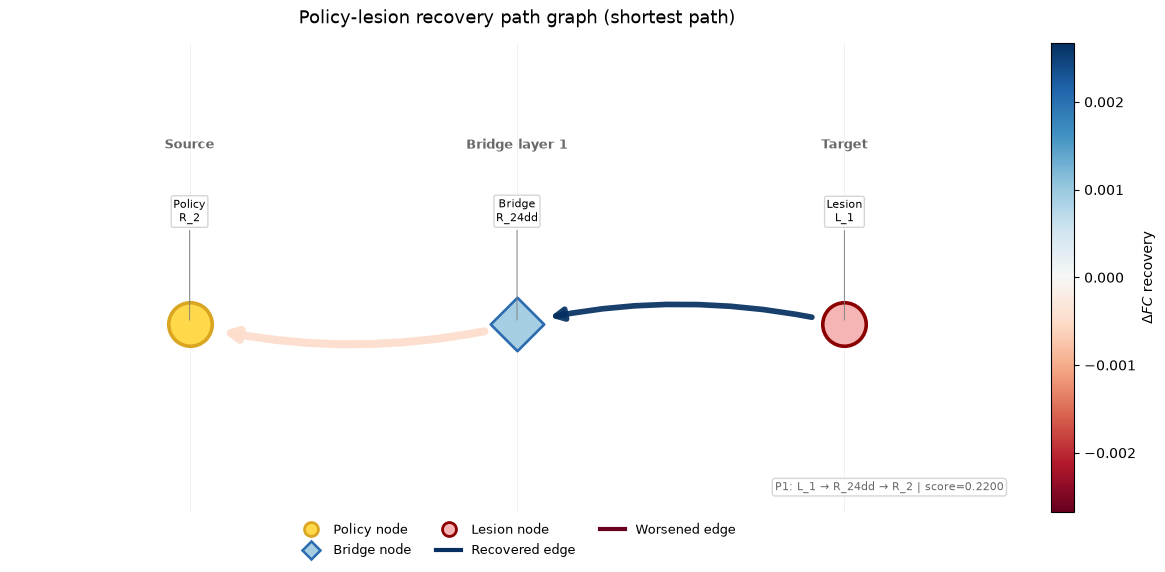

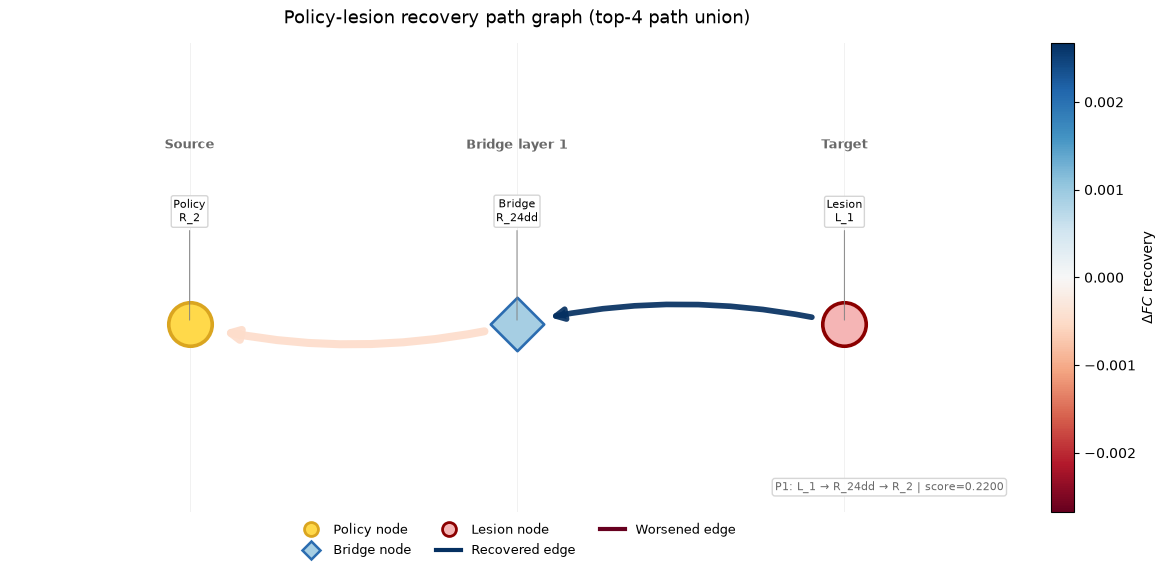

Shortest path:
[[50, 219, 231]]
   src  dst path_id  path_step  causal_src  causal_dst  is_reverse_traversal  \
0   50  219     [1]          1          50         219                 False   
1  219  231     [1]          2         219         231                 False   

   src_local  dst_local  tau  ... strong_significant_edge  fc_healthy  \
0          0         20    1  ...                    True    0.837313   
1         20          4    1  ...                    True    0.828136   

   fc_lesion  fc_policy  lesion_abn  policy_abn  delta_fc_recovery  \
0   0.832908   0.835583    0.004404    0.001730           0.002675   
1   0.827813   0.828958    0.000323    0.000822          -0.000499   

   delta_fc_raw  _path_score_for_sort  path_count  
0      0.002675              0.163392           1  
1      0.001145              0.276662           1  

[2 rows x 29 columns]
Top-K union paths:
[[50, 219, 231]]
   src  dst path_id  path_step  causal_src  causal_dst  is_reverse_traversal  \
0

In [78]:
best_policy = stage3_res["best_policy"]
best_node = int(best_policy[0]["node"])

recovery_path_pair = plot_stage4_policy_lesion_recovery_path_graph_pair(
    core_edge_df=lesion_core_edges,
    stage4_metrics=stage4_res["metrics"],
    best_policy=best_policy,
    lesion_idx=lesion_idx,
    roi_names=roi_names if "roi_names" in globals() else None,

    direction="auto",
    top_k_paths=4,
    max_hops=5,

    save_prefix="./results/stage4_policy_lesion_recovery_path",
)

print("Shortest path:")
print(recovery_path_pair["shortest"]["info"]["selected_paths"])
print(recovery_path_pair["shortest"]["info"]["selected_edge_df"])

print("Top-K union paths:")
print(recovery_path_pair["topk_union"]["info"]["selected_paths"])
print(recovery_path_pair["topk_union"]["info"]["selected_edge_df"])

In [79]:
# 使用 BEST_CONFIG 重新跑完整主线,用于最终复现实验
# final_res = run_full_pipeline_with_config(
#     config=BEST_CONFIG,
#     model=ANN,
#     inputs=inputs,
#     signals=signals,
#     roi_num=ROI_num,
#     using_steps=using_steps,
#     lesion_idx=lesion_idx,
#     empirical_FC=empirical_FC,
#     roi_names=roi_names,
# )
#
# summarize_final_pipeline_result(final_res)

In [80]:
# 假设实验一：在 30、45、60 个 ROI 的 lesion-aware 小规模子系统上运行未筛选的 LPCMCI，作为小规模 full baseline
# hypothesis_df_hop2, hypothesis_details = compare_lagged_hypothesis(
#     signals=signals,
#     lesion_idx=lesion_idx,
#     stage1_res=stage1_res,
#     roi_sizes=(30, 45, 60),
#     hop=2,
#     tau=1,
#     pc_alpha=0.01,
#     alpha_level=0.01,
#     screen_ratio=0.60,
#     min_screen_ratio=0.30,
#     topk_list=(50, 100, 200),
#     save_csv_path="./results/tables/lagged_hypothesis/lagged_hypothesis_hop2_raw.csv",
# )
#
# paper_table_hop2 = build_lagged_hypothesis_paper_table(
#     hypothesis_df_hop2,
#     decimals=3,
#     speedup_decimals=2,
#     save_csv_path="./results/tables/lagged_hypothesis/lagged_hypothesis_hop2_paper_table.csv",
# )
#
# hypothesis_judge_info_hop2 = judge_lagged_hypothesis_result(
#     hypothesis_df_hop2,
#     recall_threshold=0.30,
#     precision_threshold=0.80,
#     jaccard_threshold=0.25,
#     speedup_threshold=3.0,
#     topk_recall_thresholds={
#         "top50_recall": 0.50,
#         "top100_recall": 0.40,
#         "top200_recall": 0.30,
#     },
# )
#
# paper_table_hop2

In [81]:
# # 复算hop=1
# hypothesis_df_hop1 = recompute_lagged_hypothesis_from_details(
#     details=hypothesis_details,
#     lesion_idx=lesion_idx,
#     hop=1,
#     tau=1,
#     topk_list=(50, 100, 200),
#     save_csv_path="./results/tables/lagged_hypothesis/lagged_hypothesis_hop1_raw.csv",
# )
#
# paper_table_hop1 = build_lagged_hypothesis_paper_table(
#     hypothesis_df_hop1,
#     decimals=3,
#     speedup_decimals=2,
#     save_csv_path="./results/tables/lagged_hypothesis/lagged_hypothesis_hop1_paper_table.csv",
# )
# hypothesis_judge_info_hop1 = judge_lagged_hypothesis_result(
#     hypothesis_df_hop1,
#     recall_threshold=0.45,
#     precision_threshold=0.80,
#     jaccard_threshold=0.35,
#     speedup_threshold=3.0,
#     topk_recall_thresholds={
#         "top50_recall": 0.60,
#         "top100_recall": 0.50,
#         "top200_recall": 0.40,
#     },
# )
# paper_table_hop1

In [82]:
# import importlib
# import hypothesis_graph as lhp
# importlib.reload(lhp)
# hop1_df, hop2_df, saved_paths = lhp.make_lagged_hypothesis_figures(
#     hop1_csv="./results/tables/lagged_hypothesis/lagged_hypothesis_hop1_paper_table.csv",
#     hop2_csv="./results/tables/lagged_hypothesis/lagged_hypothesis_hop2_paper_table.csv",
#     out_dir="./results/figures/lagged_hypothesis_figs_paper",
#     show=False,   # 默认就是 False，这里写不写都行
# )
# saved_paths

In [83]:
# 假设验证实验二：在已知 ground truth 的 VAR 模拟数据中，检验“滞后筛选 + 局部 LPCMCI”是否能够在压缩节点规模和降低运行时间的同时，保留大部分真实病灶邻域滞后因果边。
# 保守版max_screen_ratio=0.55
# sim_result_055, sim_details_055 = run_simulated_var_validation_experiment(
#     n_nodes_list=(30, 45, 60),
#     n_repeats=3,
#     base_seed=123,
#     T=1200,
#     burn_in=200,
#     lesion_idx=0,
#     edge_prob=0.03,
#     n_lesion_parents=5,
#     n_lesion_children=5,
#     tau=1,
#     pc_alpha=0.01,
#     alpha_level=0.01,
#
#     max_screen_ratio=0.55,
#     min_screen_nodes=10,
#
#     parent_weight=1.5,
#     child_weight=1.5,
#     spouse_weight=0.5,
#     fill_to_max=True,
#
#     lesion_hop=2,
#     save_csv_path="./results/tables/sim_var_validation/sim_var_validation_ratio055_raw.csv",
# )
#
# layer1_055, layer2_055 = build_simulated_var_two_layer_tables(
#     sim_result_055,
#     save_prefix="./results/tables/sim_var_validation/sim_var_validation_ratio055",
# )
#
# print(layer1_055)
# print(layer2_055)

In [84]:
# summary_055 = summarize_simulated_var_results(sim_result_055)
#
# judge_055 = judge_simulated_var_validation(
#     summary_055,
#     method_name="Screening + Local LPCMCI",
#     lesion_candidate_coverage_threshold=0.60,
#     lesion_recall_threshold=0.60,
#     fpr_threshold=0.01,
#     auroc_threshold=0.70,
# )
#
# judge_055

In [85]:
# 高召回版：max_screen_ratio=0.70
# sim_result_070, sim_details_070 = run_simulated_var_validation_experiment(
#     n_nodes_list=(30, 45, 60),
#     n_repeats=3,
#     base_seed=123,
#     T=1200,
#     burn_in=200,
#     lesion_idx=0,
#     edge_prob=0.03,
#     n_lesion_parents=5,
#     n_lesion_children=5,
#     tau=1,
#     pc_alpha=0.01,
#     alpha_level=0.01,
#
#     max_screen_ratio=0.70,
#     min_screen_nodes=10,
#
#     parent_weight=1.5,
#     child_weight=1.5,
#     spouse_weight=0.5,
#     fill_to_max=True,
#
#     lesion_hop=2,
#     save_csv_path="./results/tables/sim_var_validation/sim_var_validation_ratio070_raw.csv",
# )
#
# layer1_070, layer2_070 = build_simulated_var_two_layer_tables(
#     sim_result_070,
#     save_prefix="./results/tables/sim_var_validation/sim_var_validation_ratio070",
# )
#
# print(layer1_070)
# print(layer2_070)

In [86]:
# summary_070 = summarize_simulated_var_results(sim_result_070)
#
# judge_070 = judge_simulated_var_validation(
#     summary_070,
#     method_name="Screening + Local LPCMCI",
#     lesion_candidate_coverage_threshold=0.75,
#     lesion_recall_threshold=0.75,
#     fpr_threshold=0.02,
#     auroc_threshold=0.70,
# )
#
# judge_070

In [87]:
# max_screen_ratio=0.75
# sim_result_075, sim_details_075 = run_simulated_var_validation_experiment(
#     n_nodes_list=(30, 45, 60),
#     n_repeats=3,
#     base_seed=123,
#     T=1200,
#     burn_in=200,
#     lesion_idx=0,
#     edge_prob=0.03,
#     n_lesion_parents=5,
#     n_lesion_children=5,
#     tau=1,
#     pc_alpha=0.01,
#     alpha_level=0.01,
#
#     max_screen_ratio=0.75,
#     min_screen_nodes=10,
#
#     parent_weight=1.5,
#     child_weight=1.5,
#     spouse_weight=0.5,
#     fill_to_max=True,
#
#     lesion_hop=2,
#     save_csv_path="./results/tables/sim_var_validation/sim_var_validation_ratio075_raw.csv",
# )
#
# layer1_075, layer2_075 = build_simulated_var_two_layer_tables(
#     sim_result_075,
#     save_prefix="./results/tables/sim_var_validation/sim_var_validation_ratio075",
# )
#
# print(layer1_075)
# print(layer2_075)

In [88]:
# summary_075 = summarize_simulated_var_results(sim_result_075)
#
# judge_075 = judge_simulated_var_validation(
#     summary_075,
#     method_name="Screening + Local LPCMCI",
#     lesion_candidate_coverage_threshold=0.80,
#     lesion_recall_threshold=0.80,
#     fpr_threshold=0.03,
#     auroc_threshold=0.70,
# )
#
# judge_075

In [89]:
# 筛选比例对比表
# ratio_compare_table = build_screen_ratio_comparison_table(
#     {
#         "ratio=0.55": sim_result_055,
#         "ratio=0.70": sim_result_070,
#         "ratio=0.75": sim_result_075,
#     },
#     save_csv_path="./results/tables/sim_var_validation/sim_var_validation_ratio_comparison.csv",
# )
#
# print(ratio_compare_table)

In [90]:
# import importlib
# import sim_var_validation_plots as svp
# importlib.reload(svp)
# df_ratio, saved_paths = svp.make_sim_var_validation_figures(
#     ratio_compare_csv="./results/tables/sim_var_validation/sim_var_validation_ratio_comparison.csv",
#     out_dir="./results/figures/sim_var_validation_figs_paper",
#     show=False,   # 默认就是 False
# )
#
# saved_paths

In [91]:
# import importlib
# import Parametric_grid_search
# importlib.reload(Parametric_grid_search)
#
# from Parametric_grid_search import (
#     make_lesion_list_from_stage1_response,
#     run_lesion_node_robustness,
#     summarize_lesion_node_robustness,
#     plot_lesion_node_robustness,
#     print_lesion_node_robustness_conclusion,
# )

In [92]:
# 构造 lesion node 列表
# lesion_list, lesion_list_df = make_lesion_list_from_stage1_response(
#     stage1_res=stage1_res,
#     primary_lesion=lesion_idx,
#     roi_num=ROI_num,
#     roi_names=roi_names,
#     top_n=3,
#     mid_n=2,
#     random_n=2,
#     random_state=123,
#     output_dir=OUTPUT_DIR,
# )
#
# print(lesion_list_df)
# lesion_list

In [93]:
# 固定 BEST_CONFIG，运行多个 lesion node
# robust_res = run_lesion_node_robustness(
#     lesion_list=lesion_list,
#     config=BEST_CONFIG,
#     model=ANN,
#     inputs=inputs,
#     signals=signals,
#     roi_num=ROI_num,
#     using_steps=using_steps,
#     empirical_FC=empirical_FC,
#     roi_names=roi_names,
#     output_dir=OUTPUT_DIR,
# )
#
# robustness_df = robust_res["robustness_df"]
#
# print(robustness_df)

In [94]:
# 输出总体汇总
# overall_summary_df = summarize_lesion_node_robustness(
#     robustness_df=robustness_df,
#     output_dir=OUTPUT_DIR,
# )
#
# print(overall_summary_df)

In [95]:
# 画图并保存
# plot_path = plot_lesion_node_robustness(
#     robustness_df=robustness_df,
#     output_dir=OUTPUT_DIR,
# )
#
# plot_path

In [96]:
# 打印结论
# print_lesion_node_robustness_conclusion(robustness_df)

In [97]:
# 查看每个 lesion node 的结果
# print(
#     robustness_df[
#         [
#             "lesion_idx",
#             "lesion_name",
#             "status",
#             "n_core_edges",
#             "n_direct_lesion_edges_after_prune",
#             "n_candidates",
#             "policy_size",
#             "policy_nodes",
#             "traj_recovery",
#             "fc_recovery",
#             "objective",
#             "success",
#         ]
#     ].sort_values(["success", "traj_recovery"], ascending=[False, False])
# )

In [98]:
# # 干预节点选择策略对照试验
# import importlib
# import stability_analysis
# importlib.reload(stability_analysis)
# from stability_analysis import *
# result_df, random_df, history_df, pools, stage3_outputs = run_single_and_multi_control_experiment(
#     model=ANN,
#     stage1_res=stage1_res,
#     lesion_idx=lesion_idx,
#     roi_num=ROI_num,
#     using_steps=using_steps,
#     empirical_FC=empirical_FC,
#
#     screen_res=screen_res,
#     lesion_core_edges=lesion_core_edges,
#     candidate_df=candidate_df,
#     roi_names=roi_names,
#
#     top_m=20,
#     n_random=30,
#     random_state=BEST_CONFIG['random_state'],
#     random_multi_pool_size=BEST_CONFIG["max_interventions"],
#
#     horizon=BEST_CONFIG["horizon"],
#     lesion_strength=BEST_CONFIG["lesion_strength"],
#     lesion_mode=BEST_CONFIG["lesion_mode"],
#
#     signs=BEST_CONFIG["signs"],
#     strengths=BEST_CONFIG["strengths"],
#     schedules=BEST_CONFIG["schedules"],
#
#     alpha_traj=BEST_CONFIG["alpha_traj"],
#     beta_fc=BEST_CONFIG["beta_fc"],
#     lambda_node=BEST_CONFIG["lambda_node"],
#     lambda_strength=BEST_CONFIG["lambda_strength"],
#     lambda_temporal=BEST_CONFIG["lambda_temporal"],
#
#     batch_size=BEST_CONFIG["batch_size"],
#
#     run_greedy=BEST_CONFIG["run_greedy"],
#     max_interventions=BEST_CONFIG["max_interventions"],
#     top_m_per_step=BEST_CONFIG["top_m_per_step"],
#     min_marginal_gain=BEST_CONFIG["min_marginal_gain"],
#     force_accept_first=BEST_CONFIG["force_accept_first"],
#
#     out_dir="./control_single_multi",
# )
# print(result_df)

In [99]:
# random_df[
#     (random_df["method"] == "Random candidate") &
#     (random_df["mode"] == "multi")
# ][["repeat_id", "candidate_nodes", "policy_nodes", "objective", "traj_recovery", "fc_recovery"]].head()

In [100]:
# # 单节点 vs 多节点 grouped bar
# import importlib
# import stability_analysis
# importlib.reload(stability_analysis)
# from stability_analysis import *
# plot_single_multi_control_bars(
#     result_df,
#     metric="objective",
#     include_oracle=False,  # 想把 Oracle 上界也画进去
#     save_path="./control_single_multi/fig_single_multi_objective.png",
# )
#
# plot_single_multi_control_bars(
#     result_df,
#     metric="traj_recovery",
#     save_path="./control_single_multi/fig_single_multi_traj_recovery.png",
# )
#
# plot_single_multi_control_bars(
#     result_df,
#     metric="fc_recovery",
#     save_path="./control_single_multi/fig_single_multi_fc_recovery.png",
# )

In [101]:
# # 多节点贪心搜索过程图：说明多节点是一点点加入的
# import importlib
# import stability_analysis
# importlib.reload(stability_analysis)
# from stability_analysis import *
# plot_random_multi_distribution_vs_proposed(
#     random_df=random_df,
#     result_df=result_df
# )
# plot_greedy_history(
#     history_df,
#     metric="objective",
#     include_random=False,   #TRUE：random也加进去
#     save_path="./control_single_multi/fig_greedy_history_objective.png",
# )

In [102]:
# paper_table = make_paper_control_table(result_df)
# paper_table.to_csv("./control_single_multi/paper_control_table.csv", index=False)
# print(paper_table)

In [103]:
# paper_table = make_paper_control_table(result_df)
#
# paper_table_simple = paper_table[
#     [
#         "method",
#         "comparison_role",
#         "mode",
#         "policy_nodes",
#         "policy_roi_names",
#         "policy_size",
#         "objective",
#         "objective_std",
#         "traj_recovery",
#         "traj_recovery_std",
#         "fc_recovery",
#         "fc_recovery_std",
#     ]
# ].copy()
# paper_table_main = paper_table_simple[
#     paper_table_simple["comparison_role"].isin([
#         "fair_comparison",
#         "oracle_upper_bound"
#     ])
# ].copy()
#
# paper_table_main

In [135]:
# 方法模块消融实验
import importlib
import ablation_experiments
importlib.reload(ablation_experiments)
from ablation_experiments import *
stage1_provider = make_stage1_provider_from_inputs(
    model=ANN,
    inputs=inputs,
    roi_num=ROI_num,
    using_steps=using_steps,
    roi_names=roi_names,
    best_config=BEST_CONFIG,
)

In [136]:
lesion_list = [5, 23, 47, 50, 51, 226, 231, 247]
BEST_CONFIG = dict(search_res["BEST_CONFIG"])

# 把 NaN 转成 None
for k, v in list(BEST_CONFIG.items()):
    if isinstance(v, float) and np.isnan(v):
        BEST_CONFIG[k] = None

if "prune_weight_pair" in BEST_CONFIG and BEST_CONFIG["prune_weight_pair"] is not None:
    BEST_CONFIG["causal_weight"] = float(BEST_CONFIG["prune_weight_pair"][0])
    BEST_CONFIG["fc_weight"] = float(BEST_CONFIG["prune_weight_pair"][1])

BEST_CONFIG_ABLATION = dict(BEST_CONFIG)
BEST_CONFIG_ABLATION["run_greedy"] = False

top_m_ablation = 20
random_repeats_ablation = 10
key_variants = build_key_ablation_variants(
    BEST_CONFIG_ABLATION,
    include_random=True,
    include_pruning_controls=False,
)

per_lesion_df, random_repeat_df, summary_df, core_summary_df, raw_outputs = run_multi_lesion_ablation_study(
    model=ANN,
    lesion_list=lesion_list,
    roi_num=ROI_num,
    using_steps=using_steps,
    empirical_FC=empirical_FC,
    best_config=BEST_CONFIG_ABLATION,

    stage1_provider=stage1_provider,
    stage2_variant_fn=my_stage2_variant_fn,

    signals=signals,
    roi_names=roi_names,

    variants=key_variants,
    top_m=top_m_ablation,
    random_repeats=random_repeats_ablation,
    random_state=BEST_CONFIG.get("random_state", 123),
    random_pool_size="match_full",

    out_dir="./ablation_multi_lesion_compact_internal",
)

[Ablation] lesion_idx=5, lesion_name=L_V4
[Variant] Full method
[Stage2] Running LPCMCI on screened subnetwork: n_nodes=50, tau_max=1
[Variant] w/o response prior
[Stage2] Running LPCMCI on screened subnetwork: n_nodes=41, tau_max=1
[Variant] w/o LPCMCI
[Variant] Random ranking (10 repeats)
[Ablation] lesion_idx=23, lesion_name=L_A1
[Variant] Full method
[Stage2] Running LPCMCI on screened subnetwork: n_nodes=50, tau_max=1
[Variant] w/o response prior
[Stage2] Running LPCMCI on screened subnetwork: n_nodes=41, tau_max=1
[Variant] w/o LPCMCI
[Variant] Random ranking (10 repeats)
[Ablation] lesion_idx=47, lesion_name=L_LIPv
[Variant] Full method
[Stage2] Running LPCMCI on screened subnetwork: n_nodes=49, tau_max=1
[Variant] w/o response prior
[Stage2] Running LPCMCI on screened subnetwork: n_nodes=41, tau_max=1
[Variant] w/o LPCMCI
[Variant] Random ranking (10 repeats)
[Ablation] lesion_idx=50, lesion_name=L_1
[Variant] Full method
[Stage2] Running LPCMCI on screened subnetwork: n_nodes=

In [137]:
# 生成内部消融结构表
internal_structure_table, internal_structure_formatted = save_compact_internal_ablation_outputs(
    per_lesion_df,
    out_dir="./ablation_multi_lesion_compact_internal",
    reference_variant="Full method",
)

internal_structure_formatted

,Variant,Candidate nodes,Core edges,Direct lesion edges,Best-node overlap
0,Full method,16.1 ± 3.8,20.0 ± 0.0,5.2 ± 2.8,--
1,w/o response prior,15.6 ± 3.9,20.0 ± 0.0,5.4 ± 2.4,0.875
2,w/o LPCMCI,20.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.375
3,Random ranking,16.1 ± 3.8,--,--,0.000


In [138]:
# 提取 Full method 候选预算
full_candidate_budget = extract_full_candidate_budget(
    per_lesion_df,
    reference_variant="Full method",
    min_k=1,
    max_k=20,
    fallback_k=20,
)

main_baselines = build_literature_baseline_variants_no_pcmciplus()

literature_per_lesion_df, literature_summary_df, literature_candidate_df, literature_raw_outputs = \
    run_multi_lesion_literature_baseline_study_full_size_matched_by_baseline_checkpointed(
        model=ANN,
        lesion_list=lesion_list,
        roi_num=ROI_num,
        using_steps=using_steps,
        empirical_FC=empirical_FC,
        best_config=BEST_CONFIG_ABLATION,
        stage1_provider=stage1_provider,
        full_method_per_lesion_df=per_lesion_df,

        signals=signals,
        roi_names=roi_names,
        baselines=main_baselines,
        include_pcmciplus=False,
        fallback_top_m=20,

        out_dir="./ablation_multi_lesion_literature_main_baselines_random_intervention",

        # control-based baselines
        control_ridge=1e-2,
        control_energy_eps=1e-3,
        control_horizon=BEST_CONFIG_ABLATION.get("horizon", 20),
        target_control_m=None,
        tracking_lambda_u=1e-2,

        # Random-intervention baseline
        random_intervention_repeats=50,
        random_intervention_seed=BEST_CONFIG.get("random_state", 123),
        random_intervention_node_pool=None,   # None 表示全脑非病灶 ROI 随机
        random_intervention_signs=None,       # None 表示使用 BEST_CONFIG_ABLATION["signs"]
        random_intervention_strengths=None,   # None 表示使用 BEST_CONFIG_ABLATION["strengths"]
        random_intervention_schedules=None,   # None 表示使用 BEST_CONFIG_ABLATION["schedules"]

        resume=True,
        skip_failed_when_resume=False,
        save_per_baseline_files=True,
    )

[Full-size matched checkpoint] START baseline: Global-FC hub baseline
--------------------------------------------------------------------------------
  [Run] baseline=Global-FC hub baseline, lesion_idx=5, lesion_name=L_V4, K_l=19
    - building candidates ...
    - candidates built: n=19, time=0.0s
    - running Stage 3 ...
    - Stage 3 done: time=65.2s
    - lesion done: total=65.2s
--------------------------------------------------------------------------------
  [Run] baseline=Global-FC hub baseline, lesion_idx=23, lesion_name=L_A1, K_l=16
    - building candidates ...
    - candidates built: n=16, time=0.0s
    - running Stage 3 ...
    - Stage 3 done: time=54.3s
    - lesion done: total=54.3s
--------------------------------------------------------------------------------
  [Run] baseline=Global-FC hub baseline, lesion_idx=47, lesion_name=L_LIPv, K_l=20
    - building candidates ...
    - candidates built: n=20, time=0.0s
    - running Stage 3 ...
    - Stage 3 done: time=68.5s


In [140]:
# 生成 baseline comparison 表
baseline_df, baseline_summary_df, baseline_formatted_df = build_baseline_comparison_results(
    ablation_per_lesion_df=per_lesion_df,
    literature_per_lesion_df=literature_per_lesion_df,
    out_dir="./ablation_multi_lesion_baseline_comparison_random_intervention",
)

baseline_formatted_df

,variant,n_lesions,objective,traj_recovery,fc_recovery,policy_size,success_rate
0,Full method,8,0.7487 ± 0.2482,0.4249 ± 0.1111,0.4159 ± 0.1851,1.0000 ± 0.0000,1.0000
1,Global-FC hub baseline,8,0.4485 ± 0.3134,0.2574 ± 0.1679,0.2464 ± 0.2117,1.0000 ± 0.0000,1.0000
2,NCT-state-transition baseline,8,0.5514 ± 0.2513,0.3144 ± 0.1157,0.3060 ± 0.1870,1.0000 ± 0.0000,1.0000
3,Target-control baseline,8,0.6323 ± 0.2067,0.3620 ± 0.1191,0.3478 ± 0.1807,1.0000 ± 0.0000,1.0000
4,Tracking-control baseline,8,0.6083 ± 0.1386,0.3517 ± 0.0640,0.3286 ± 0.1645,1.0000 ± 0.0000,1.0000
5,Random-intervention baseline,8,-0.3640 ± 0.1474,-0.1913 ± 0.0775,-0.2073 ± 0.1100,1.0000 ± 0.0000,0.0000


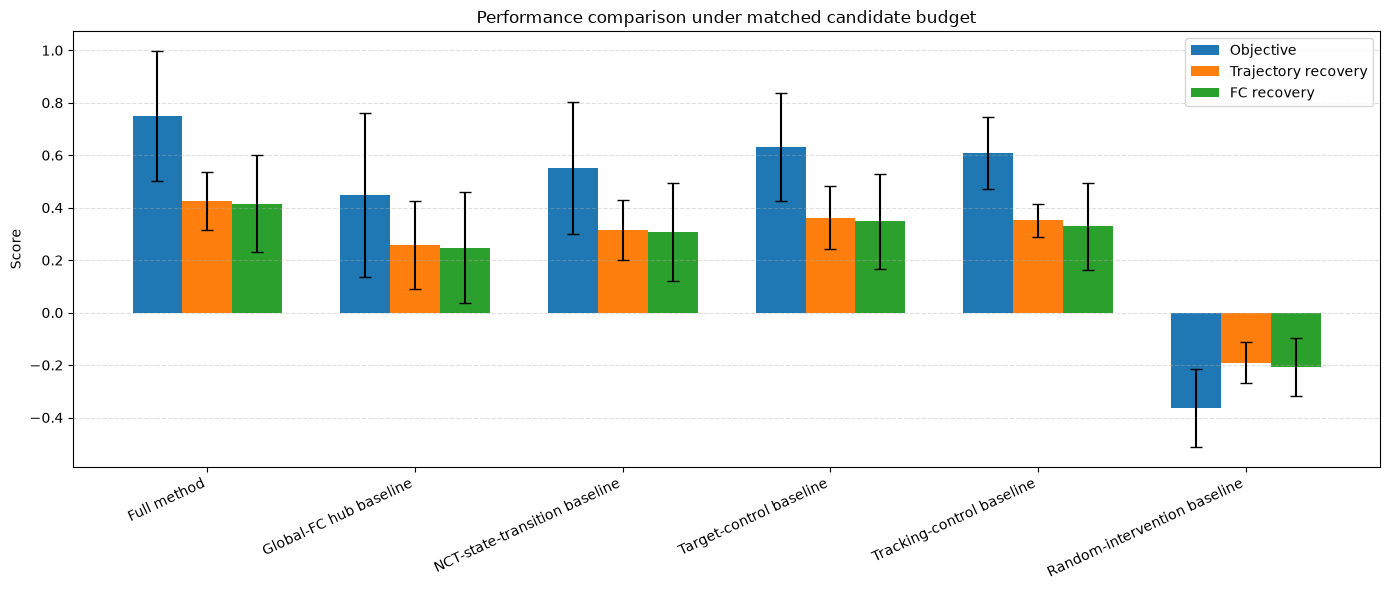

./ablation_multi_lesion_baseline_comparison_random_intervention/baseline_three_metrics_grouped.png


In [141]:
baseline_plot_order = [
    "Full method",
    "Global-FC hub baseline",
    "NCT-state-transition baseline",
    "Target-control baseline",
    "Tracking-control baseline",
    "Random-intervention baseline",
]

fig, ax, save_path = plot_baseline_three_metrics_grouped(
    baseline_summary_df,
    variants=baseline_plot_order,
    out_dir="./ablation_multi_lesion_baseline_comparison_random_intervention",
    save_name="baseline_three_metrics_grouped.png",
    title="Performance comparison under matched candidate budget",
)

print(save_path)

In [130]:
# # 合并消融与baseline
# combined_4_6_df, combined_4_6_summary_df = combine_ablation_and_literature_results(
#     ablation_per_lesion_df=per_lesion_df,
#     literature_per_lesion_df=literature_per_lesion_df,
#     out_dir="./ablation_multi_lesion_combined_budget_matched",
# )

In [ ]:
# full_candidate_budget = extract_full_candidate_budget(
#     per_lesion_df,
#     reference_variant="Full method",
#     min_k=1,
#     max_k=20,
#     fallback_k=20,
# )

# five_lit_baselines = build_literature_baseline_variants_no_pcmciplus()

# literature_per_lesion_df, literature_summary_df, literature_candidate_df, literature_raw_outputs = \
#     run_multi_lesion_literature_baseline_study_full_size_matched_by_baseline_checkpointed(
#         model=ANN,
#         lesion_list=lesion_list,
#         roi_num=ROI_num,
#         using_steps=using_steps,
#         empirical_FC=empirical_FC,
#         best_config=BEST_CONFIG_ABLATION,
#         stage1_provider=stage1_provider,
#         full_method_per_lesion_df=per_lesion_df,
#         signals=signals,
#         roi_names=roi_names,
#         baselines=five_lit_baselines,
#         include_pcmciplus=False,
#         fallback_top_m=20,
#         out_dir="./ablation_multi_lesion_literature_global_lagged_budget_matched",
#         control_ridge=1e-2,
#         control_energy_eps=1e-3,
#         control_horizon=BEST_CONFIG_ABLATION.get("horizon", 20),
#         target_control_m=None,
#         tracking_lambda_u=1e-2,
#         resume=True,
#         skip_failed_when_resume=False,
#         save_per_baseline_files=True,
#     )

In [131]:
# # 生成论文表格
# combined_paper_table = make_ablation_paper_table(combined_4_6_summary_df)
# combined_formatted_table = format_mean_std_table(combined_4_6_summary_df)
# print(combined_formatted_table)

                                variant  n_lesions        objective  \
0                           Full method          8  0.7487 ± 0.2482   
1                    w/o response prior          8  0.7751 ± 0.2474   
2                            w/o LPCMCI          8  0.8583 ± 0.1858   
3                        Random ranking          8  0.7473 ± 0.1934   
4                Global-FC hub baseline          8  0.4485 ± 0.3134   
5  Lagged-only lesion-proximal baseline          8  0.8459 ± 0.1966   
6         NCT-state-transition baseline          8  0.5514 ± 0.2513   
7               Target-control baseline          8  0.6323 ± 0.2067   
8             Tracking-control baseline          8  0.6083 ± 0.1386   
9          Random-intervention baseline          8  0.4802 ± 0.1911   

     traj_recovery      fc_recovery      policy_size success_rate  
0  0.4249 ± 0.1111  0.4159 ± 0.1851  1.0000 ± 0.0000       1.0000  
1  0.4369 ± 0.1056  0.4345 ± 0.1899  1.0000 ± 0.0000       1.0000  
2  0.4800 ± 0.

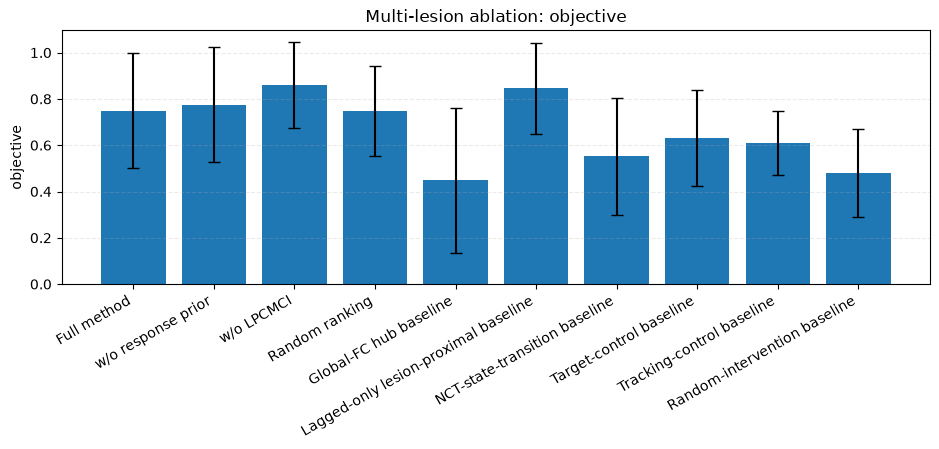

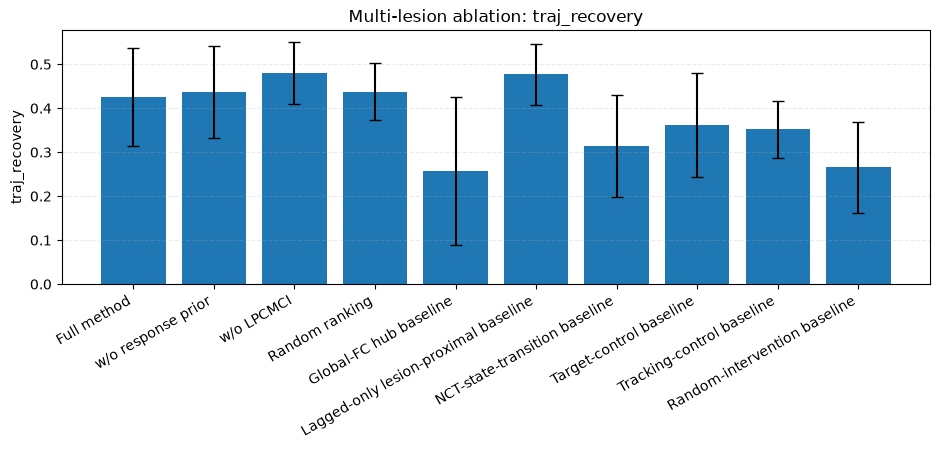

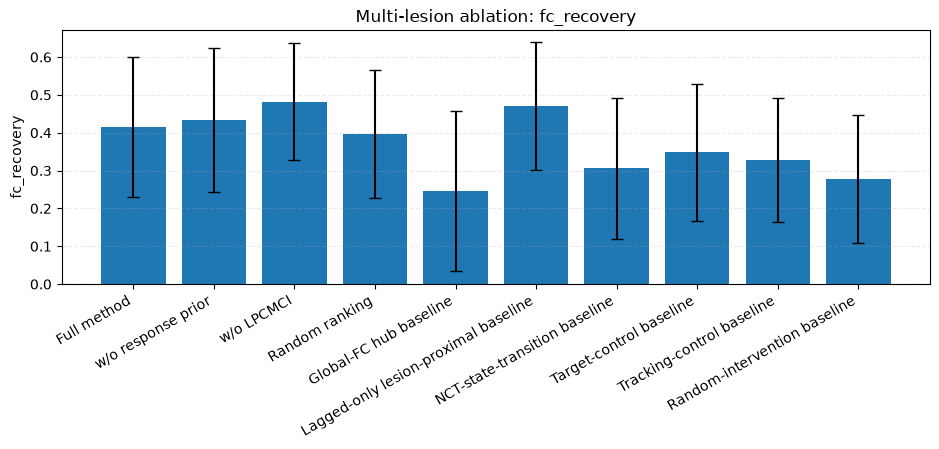

In [132]:
# # Objective / trajectory recovery / FC recovery 三个柱状图
# plot_ablation_three_metrics(
#     combined_4_6_summary_df,
#     out_dir="./ablation_multi_lesion_combined",
# )

In [133]:
# # best-node一致性分析

# best_node_overlap_summary = summarize_best_node_overlap(
#     combined_4_6_df,
#     reference_variant="Full method"
# )

# candidate_hit_summary = candidate_hit_rate_against_reference(
#     combined_4_6_df,
#     reference_variant="Full method"
# )

# print(best_node_overlap_summary)
# print(candidate_hit_summary)

                                variant  n_lesions  best_node_overlap_rate
0                Global-FC hub baseline          8                   0.250
1  Lagged-only lesion-proximal baseline          8                   0.375
2         NCT-state-transition baseline          8                   0.125
3                        Random ranking          8                   0.000
4          Random-intervention baseline          8                   0.000
5               Target-control baseline          8                   0.125
6             Tracking-control baseline          8                   0.125
7                            w/o LPCMCI          8                   0.375
8                    w/o response prior          8                   0.875
                                variant  n_lesions  candidate_hit_rate
0                           Full method          8                 1.0
1                Global-FC hub baseline          8                 0.0
2  Lagged-only lesion-proximal baseli

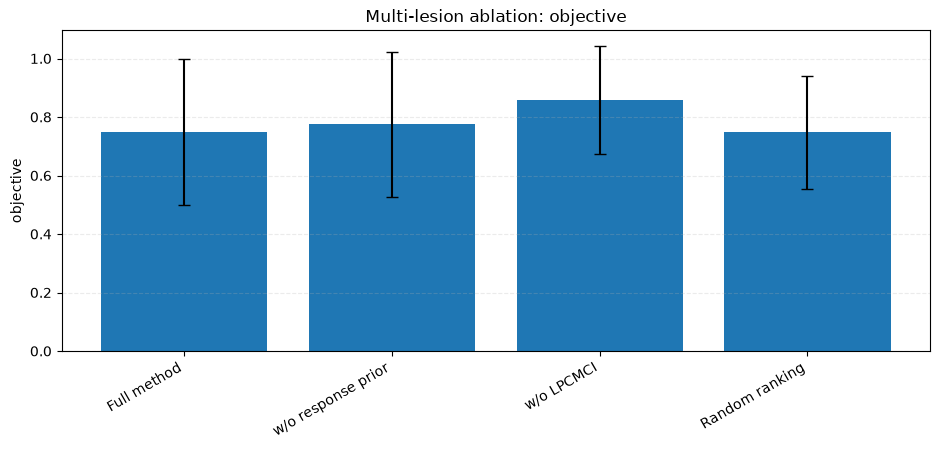

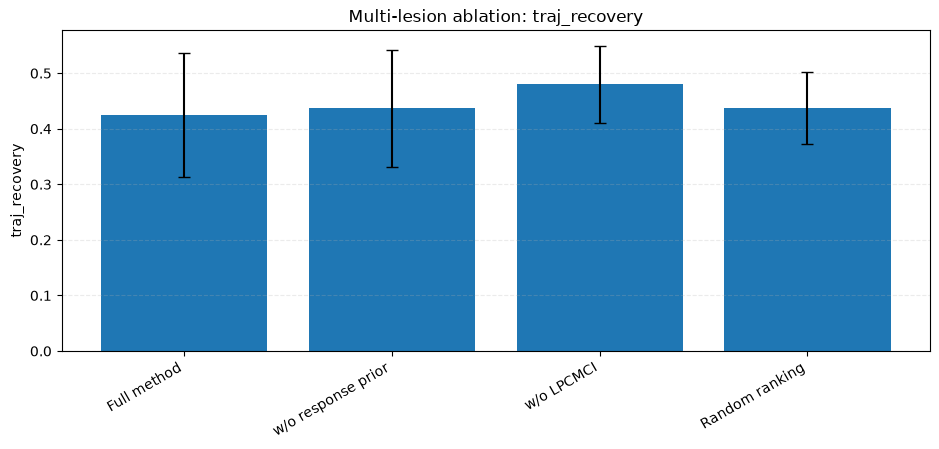

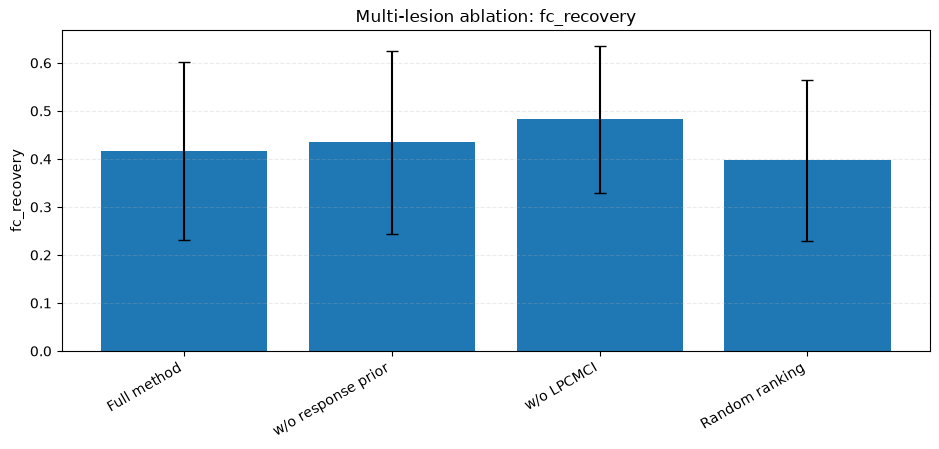

In [134]:
# plot_ablation_three_metrics(
#     summary_df,
#     out_dir="./ablation_multi_lesion"
# )

In [112]:
# import importlib
# import topk_candidate_efficiency as topk
# importlib.reload(topk)
# from intervention_optimization import run_single_node_search
# TOPK_OUT_DIR = "./topk_candidate_efficiency"
# lesion_list_topk = [5, 23, 47, 50, 51, 226, 231, 247]
# topk_variants = [
#     "Full method",
#     "w/o response prior",
#     "w/o LPCMCI",
# ]
# top_k_list = [3, 5, 10, 20]
# # Random ranking 每个 lesion / K 重复次数
# topk_random_repeats = 20
# # Top-K 实验统一使用 single-node Stage3
# BEST_CONFIG_TOPK = topk.make_topk_stage3_config(BEST_CONFIG)
# topk_result_df = topk.run_topk_candidate_efficiency_from_raw_outputs(
#     raw_outputs=raw_outputs,
#     lesion_list=lesion_list_topk,
#     model=ANN,
#     roi_num=ROI_num,
#     using_steps=using_steps,
#     best_config=BEST_CONFIG_TOPK,
#
#     variants=topk_variants,
#     top_k_list=top_k_list,
#     random_repeats=topk_random_repeats,
#     random_state=BEST_CONFIG_TOPK.get("random_state", 123),
#
#     stage3_fn=run_single_node_search,
#
#     out_dir=TOPK_OUT_DIR,
#     verbose=True,
# )
#
# topk_result_df.head()

In [113]:
# topk_summary_df = topk.summarize_topk_efficiency(topk_result_df)
#
# _, topk_summary_table = topk.save_topk_summary_tables(
#     topk_summary_df,
#     out_dir=TOPK_OUT_DIR,
#     # decimals=4,
# )
# # summary表
# print(topk_summary_df)
# # 格式化表
# print(topk_summary_table)

In [114]:
# topk.plot_topk_efficiency_curves(
#     topk_summary_df,
#     metrics=("objective", "traj_recovery", "fc_recovery"),
#     out_dir=TOPK_OUT_DIR,
# )

In [115]:
# # 不同 Top-K 下，最终选择的 best_node 是否稳定。
# topk_inclusion_df, topk_stability_df = topk.save_topk_diagnostics(
#     topk_result_df,
#     out_dir=TOPK_OUT_DIR,
# )
#
# topk_stability_df

In [116]:
# topk.print_topk_result_interpretation_template(language="zh")  #“en"

In [125]:
def make_compact_internal_ablation_table(per_lesion_df, reference_variant="Full method"):
    import numpy as np
    import pandas as pd

    keep_variants = [
        "Full method",
        "w/o response prior",
        "w/o LPCMCI",
        "Random ranking",
    ]

    df = per_lesion_df[
        per_lesion_df["variant"].isin(keep_variants)
    ].copy()

    if "status" in df.columns:
        df = df[df["status"].astype(str) == "ok"].copy()

    rows = []

    for variant, sub in df.groupby("variant"):
        row = {
            "variant": variant,
            "n_lesions": int(sub["lesion_idx"].nunique()),
        }

        for m in [
            "n_candidate_nodes",
            "n_core_edges",
            "n_direct_lesion_edges",
        ]:
            if m in sub.columns:
                vals = pd.to_numeric(sub[m], errors="coerce")
                row[f"{m}_mean"] = float(vals.mean())
                row[f"{m}_std"] = float(vals.std())

        rows.append(row)

    out = pd.DataFrame(rows)

    overlap_df = summarize_best_node_overlap(
        df,
        reference_variant=reference_variant
    )

    out = out.merge(
        overlap_df[["variant", "best_node_overlap_rate"]],
        on="variant",
        how="left"
    )

    order = {
        "Full method": 0,
        "w/o response prior": 1,
        "w/o LPCMCI": 2,
        "Random ranking": 3,
    }

    out["_order"] = out["variant"].map(order)
    out = out.sort_values("_order").drop(columns="_order").reset_index(drop=True)

    # Random ranking 不独立构造 causal core，因此 causal-core 结构指标设为 N.A.
    mask_random = out["variant"] == "Random ranking"
    for col in [
        "n_core_edges_mean",
        "n_core_edges_std",
        "n_direct_lesion_edges_mean",
        "n_direct_lesion_edges_std",
    ]:
        if col in out.columns:
            out.loc[mask_random, col] = np.nan

    return out


def format_compact_internal_ablation_table(df, decimals=3):
    import pandas as pd

    rows = []

    for _, r in df.iterrows():
        row = {
            "Variant": r["variant"],
            "Candidate nodes": (
                f"{r['n_candidate_nodes_mean']:.1f} ± {r['n_candidate_nodes_std']:.1f}"
                if pd.notna(r.get("n_candidate_nodes_mean")) else "N.A."
            ),
            "Core edges": (
                f"{r['n_core_edges_mean']:.1f} ± {r['n_core_edges_std']:.1f}"
                if pd.notna(r.get("n_core_edges_mean")) else "N.A."
            ),
            "Direct lesion edges": (
                f"{r['n_direct_lesion_edges_mean']:.1f} ± {r['n_direct_lesion_edges_std']:.1f}"
                if pd.notna(r.get("n_direct_lesion_edges_mean")) else "N.A."
            ),
            "Best-node overlap": (
                "—" if r["variant"] == "Full method"
                else f"{r['best_node_overlap_rate']:.{decimals}f}"
                if pd.notna(r.get("best_node_overlap_rate")) else "N.A."
            ),
        }
        rows.append(row)

    return pd.DataFrame(rows)

In [126]:
compact_internal_table = make_compact_internal_ablation_table(
    per_lesion_df,
    reference_variant="Full method"
)

compact_internal_formatted = format_compact_internal_ablation_table(
    compact_internal_table
)

compact_internal_formatted

,Variant,Candidate nodes,Core edges,Direct lesion edges,Best-node overlap
0,Full method,16.1 ± 3.8,20.0 ± 0.0,5.2 ± 2.8,—
1,w/o response prior,15.6 ± 3.9,20.0 ± 0.0,5.4 ± 2.4,0.875
2,w/o LPCMCI,20.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.375
3,Random ranking,16.1 ± 3.8,N.A.,N.A.,0.000
